# Detección de emociones en mensajes de estudiantes para un tutor virtual

## 1. Introducción

Las emociones influyen directamente en el aprendizaje. La teoría de control-valor de las emociones de logro [1] sostiene que estados como la frustración, el enojo o la alegría afectan la motivación, la atención y las estrategias de estudio. Del mismo modo, los estudios sobre la dinámica afectiva durante el aprendizaje complejo [2] muestran que la confusión es un estado frecuente y, hasta cierto punto, productivo: cuando se resuelve, favorece una comprensión más profunda. Cuando no se resuelve, en cambio, tiende a convertirse en frustración y, después, en desinterés o abandono de la tarea.

En la educación presencial, un docente percibe estas señales en el rostro, el tono o las preguntas de sus estudiantes y ajusta su explicación sobre la marcha. En los entornos de aprendizaje mediados por tecnología, y en particular en los tutores virtuales basados en chatbots, esa información se pierde: el sistema responde al contenido del mensaje, pero no a la forma en que el estudiante se siente. Un tutor que no distingue entre un estudiante que pregunta por curiosidad y otro que está a punto de rendirse responderá de la misma manera a ambos.

El objetivo de este proyecto es construir un clasificador supervisado que, a partir de un mensaje escrito por un estudiante, identifique su estado emocional entre cinco clases relevantes para el contexto educativo: **frustración, confusión, enojo, alegría y neutral**. Este clasificador está pensado como un componente que, en trabajos futuros, permitirá a un tutor virtual adaptar su estrategia pedagógica, por ejemplo simplificando la explicación cuando detecta frustración o confusión.

El principal reto es la escasez de datos: no existen datasets públicos y abiertos de mensajes de estudiantes en español etiquetados con estas emociones. Para abordarlo, se construye un dataset a partir de la versión en español de GoEmotions [3], cuyas 27 emociones originales se agrupan en las cinco clases de interés, y se complementa con mensajes de contexto educativo generados con un modelo de lenguaje. Como representación de los textos se usan embeddings de un modelo Sentence-BERT multilingüe preentrenado [4] (transfer learning), sobre los cuales se entrenan y comparan estadísticamente clasificadores de aprendizaje supervisado, siguiendo una metodología de validación con repeated k-fold cross-validation.

## 2. Análisis exploratorio de datos (EDA)

El dataset del proyecto se construye a partir de **tres fuentes**:

| Fuente (columna `fuente`) | Origen | Tamaño aproximado |
|---|---|---|
| `goemotions` | GoEmotions traducido automáticamente al español (`mrm8488/go_emotions-es-mt`): comentarios de Reddit etiquetados por personas. | ~54 000 comentarios antes de filtrar |
| `gpt` | Mensajes de contexto educativo generados con ChatGPT. | ~1 000 (≈ 200 por clase) |
| `gemini` | Mensajes de contexto educativo generados con Gemini. | ~500 (≈ 100 por clase) |

La sección se organiza en tres partes:

- **Parte A (2.1 a 2.4):** carga, análisis y transformación de GoEmotions hasta las cinco clases del proyecto.
- **Parte B (2.5 y 2.6):** carga y verificación de los datasets sintéticos y unificación de las tres fuentes en un único DataFrame con la columna `fuente`.
- **Parte C (2.7 a 2.14):** análisis del dataset unificado. Cada análisis se presenta para el conjunto completo y **desglosado por fuente**, con dos objetivos: caracterizar el dataset final y comparar los datos reales (Reddit) con los sintéticos (GPT y Gemini).

Cada decisión se justifica junto al código que la implementa, y al final de cada subsección se resumen las cifras clave.

### Configuración general

Antes de empezar se importan las bibliotecas y se fijan los elementos comunes a toda la notebook:

- **Semilla global (`42`)**: se usa en todo muestreo aleatorio para que los resultados sean reproducibles.
- **Orden y paleta de colores de las clases**: cada clase tiene siempre el mismo color en todos los gráficos de la notebook (EDA, matriz de confusión, t-SNE), de modo que, por ejemplo, la frustración se reconozca a simple vista. La paleta se eligió para que los cinco colores se distingan también con los tipos de daltonismo más comunes.
- **Orden y paleta de colores de las fuentes**: una segunda paleta, distinta de la de las clases, identifica siempre a `goemotions`, `gpt` y `gemini`, para que en los gráficos desglosados por fuente no se confunda una fuente con una clase.
- **Agrupación de emociones**: el diccionario que asigna cada emoción original de GoEmotions a una de las cinco clases se define aquí porque se usa desde la subsección 2.3; su justificación está en la subsección 2.4.
- **Rutas de los datos**: en Colab, la notebook monta Google Drive y lee los CSV sintéticos desde la carpeta indicada en `CARPETA_DRIVE`, donde también guarda el dataset final, de modo que los archivos persisten entre sesiones. Fuera de Colab se usa la carpeta local `data/`. Todas las rutas dependen de una sola variable, `DIRECTORIO_DATOS`; la opción de subir los archivos directamente a la sesión de Colab queda comentada.

In [83]:
%pip install -q datasets spacy

In [84]:
import itertools
import os
import random
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Semilla global para que todo muestreo aleatorio sea reproducible
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# ------------------------------------------------------------------
# Rutas de los datos (configuración única)
# ------------------------------------------------------------------
# Opción activa: en Colab se leen los CSV desde Google Drive; fuera de Colab, desde la carpeta local data/.
# Cambiar CARPETA_DRIVE si los CSV están en otra carpeta de "Mi unidad".
CARPETA_DRIVE = "/content/drive/MyDrive/analisis_sentimientos/data"

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
    DIRECTORIO_DATOS = CARPETA_DRIVE
else:
    DIRECTORIO_DATOS = "data"

# Otra opción en Colab (sin Drive): subir los dos CSV a la sesión (panel "Archivos" > "Subir")
# y usar la línea siguiente. Los archivos se pierden al reiniciar el entorno de ejecución.
# DIRECTORIO_DATOS = "/content"

RUTA_CSV_GPT = os.path.join(DIRECTORIO_DATOS, "dataset_sentimientos_educativo_gpt.csv")
RUTA_CSV_GEMINI = os.path.join(DIRECTORIO_DATOS, "dataset_sentimientos_educativo_gemini.csv")
RUTA_DATASET_FINAL = os.path.join(DIRECTORIO_DATOS, "dataset_final.csv")

# Comprobación temprana para que un error de ruta se detecte aquí y no en la sección 2.5
for ruta in [RUTA_CSV_GPT, RUTA_CSV_GEMINI]:
    if not os.path.exists(ruta):
        contenido = sorted(os.listdir(DIRECTORIO_DATOS)) if os.path.isdir(DIRECTORIO_DATOS) else "la carpeta no existe"
        raise FileNotFoundError(
            f"No se encontró {ruta}. Contenido de '{DIRECTORIO_DATOS}': {contenido}. "
            f"Revise CARPETA_DRIVE (o DIRECTORIO_DATOS) y el nombre de los archivos."
        )
print(f"Carpeta de datos: {os.path.abspath(DIRECTORIO_DATOS)}")

# Orden fijo de las clases y nombres para mostrar en los gráficos
ORDEN_CLASES = ["frustracion", "confusion", "enojo", "alegria", "neutral"]
NOMBRES_CLASES = {
    "frustracion": "Frustración",
    "confusion": "Confusión",
    "enojo": "Enojo",
    "alegria": "Alegría",
    "neutral": "Neutral",
}

# Paleta fija por clase (se reutiliza en toda la notebook)
PALETA_CLASES = {
    "frustracion": "#eb6834",  # naranja
    "confusion": "#2a78d6",    # azul
    "enojo": "#e87ba4",        # magenta
    "alegria": "#eda100",      # amarillo
    "neutral": "#1baf7a",      # verde agua
}
COLOR_GENERAL = "#5f6b7a"  # gris para gráficos que no distinguen clases ni fuentes

# Orden fijo de las fuentes y paleta por fuente (distinta de la paleta de clases)
ORDEN_FUENTES = ["goemotions", "gpt", "gemini"]
NOMBRES_FUENTES = {
    "goemotions": "GoEmotions (Reddit)",
    "gpt": "GPT",
    "gemini": "Gemini",
}
PALETA_FUENTES = {
    "goemotions": "#264653",  # azul petróleo oscuro
    "gpt": "#8e44ad",         # violeta
    "gemini": "#b5651d",      # siena
}

# Agrupación de las emociones originales en las 5 clases (justificada en 2.4)
MAPEO_CLASES = {
    "annoyance": "frustracion",
    "disappointment": "frustracion",
    "confusion": "confusion",
    "anger": "enojo",
    "disgust": "enojo",
    "joy": "alegria",
    "gratitude": "alegria",
    "admiration": "alegria",
    "approval": "alegria",
    "relief": "alegria",
    "excitement": "alegria",
    "neutral": "neutral",
}

# Estilo de los gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# Mostrar los textos completos en las tablas
pd.set_option("display.max_colwidth", None)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta de datos: /content/drive/MyDrive/analisis_sentimientos/data


---

## Parte A: GoEmotions

### 2.1 Carga de GoEmotions

Se usa el dataset **`mrm8488/go_emotions-es-mt`** de Hugging Face, que es la versión de GoEmotions traducida automáticamente al español. Se carga con la biblioteca `datasets` y, a continuación, se muestra su estructura: los splits disponibles y el número de filas de cada uno.

In [85]:
from datasets import load_dataset

ds = load_dataset("mrm8488/go_emotions-es-mt")
print(ds)

print("\nFilas por split:")
for nombre_split, split in ds.items():
    print(f"  {nombre_split:<12}{split.num_rows:>8,}")
print(f"  {'total':<12}{sum(s.num_rows for s in ds.values()):>8,}")

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 5427
    })
})

Filas por split:
  train         43,410
  validation     5,426
  test           5,427
  total         54,263


**Unión de los splits.** Los tres splits (`train`, `validation` y `test`) se unen en un único DataFrame. Más adelante los modelos se evaluarán con un esquema propio de *repeated k-fold cross-validation*, que genera sus propias particiones de entrenamiento y validación; por eso las particiones originales no se usan. Se agrega la columna `split` para conservar el origen de cada fila por si se necesita consultarlo.

In [86]:
df_crudo = pd.concat(
    [split.to_pandas().assign(split=nombre_split) for nombre_split, split in ds.items()],
    ignore_index=True,
)
# La columna labels llega como arreglo de NumPy; se convierte a lista de enteros
df_crudo["labels"] = df_crudo["labels"].apply(lambda etiquetas: [int(e) for e in etiquetas])

print("Dimensiones:", df_crudo.shape)
print("Columnas:", list(df_crudo.columns))
print("\nTipos de datos:")
print(df_crudo.dtypes)

Dimensiones: (54263, 5)
Columnas: ['text', 'labels', 'id', 'text_es', 'split']

Tipos de datos:
text       object
labels     object
id         object
text_es    object
split      object
dtype: object


In [87]:
df_crudo.head()

,text,labels,id,text_es,split
0,My favourite food is anything I didn't have to cook myself.,[27],eebbqej,Mi comida favorita es cualquier cosa que no tuviera que cocinar yo mismo.,train
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead",[27],ed00q6i,"Ahora, si lo hace fuera de sí mismo, todo el mundo pensará que está teniendo una risa jodiendo con la gente en lugar de realmente muerto",train
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj,POR QUÉ FUE EL FOLLADO ES LA BAYLESS ISOING,train
3,To make her feel threatened,[14],ed7ypvh,Para hacerla sentir amenazada.,train
4,Dirty Southern Wankers,[3],ed0bdzj,Sucio sureño Wankers,train


**Descripción de las columnas**

| Columna | Descripción |
|---|---|
| `text` | Comentario original de Reddit, en inglés. |
| `text_es` | Traducción automática del comentario al español. **Es la columna que se usará para modelar.** |
| `labels` | Lista de índices de emociones. El dataset es multietiqueta, así que un comentario puede tener varias. |
| `id` | Identificador del comentario en Reddit. |
| `split` | Partición original de la que proviene la fila (columna agregada en esta notebook). |

**Descripción del dataset original.** GoEmotions [3] es un corpus de aproximadamente 58 000 comentarios en inglés extraídos de Reddit, publicado por Google Research en 2020 (Demszky et al.). Cada comentario fue anotado por personas mediante *crowdsourcing* con una o varias de **27 emociones más la categoría `neutral`** (28 categorías en total). La versión usada aquí contiene los comentarios de la versión simplificada del dataset original (unos 54 000, porque esa versión descarta los comentarios sin acuerdo suficiente entre anotadores), con su traducción automática al español.

[3] D. Demszky, D. Movshovitz-Attias, J. Ko, A. Cowen, G. Nemade y S. Ravi, "GoEmotions: A dataset of fine-grained emotions," en *Proc. 58th Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2020, pp. 4040–4054.

**Cifras clave de 2.1**

- Filas por split: `train` = [COMPLETAR], `validation` = [COMPLETAR], `test` = [COMPLETAR].
- Filas del DataFrame unido (`df_crudo`): [COMPLETAR].

### 2.2 Decodificación de las etiquetas

La columna `labels` solo contiene índices numéricos. Para poder analizarlos se define la lista ordenada de las 28 categorías de GoEmotions, donde la posición de cada nombre corresponde a su índice (0 = `admiration`, …, 27 = `neutral`).

In [88]:
EMOCIONES_GOEMOTIONS = [
    "admiration", "amusement", "anger", "annoyance", "approval", "caring",
    "confusion", "curiosity", "desire", "disappointment", "disapproval",
    "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief",
    "joy", "love", "nervousness", "optimism", "pride", "realization",
    "relief", "remorse", "sadness", "surprise", "neutral",
]
print(f"Número de categorías: {len(EMOCIONES_GOEMOTIONS)}")

Número de categorías: 28


**Verificación del orden.** Un error en el orden de la lista asignaría nombres equivocados a todas las etiquetas sin que el código falle, así que se comprueba explícitamente. Para ello se cargan los nombres de las etiquetas desde el dataset original `google-research-datasets/go_emotions` (configuración `simplified`) y se comparan con la lista definida. Esos nombres corresponden al archivo `emotions.txt` del repositorio oficial de Google Research (https://github.com/google-research/google-research/blob/master/goemotions/data/emotions.txt), que define el orden oficial de las 28 categorías.

In [89]:
ds_original = load_dataset("google-research-datasets/go_emotions", "simplified")
nombres_oficiales = ds_original["train"].features["labels"].feature.names

assert nombres_oficiales == EMOCIONES_GOEMOTIONS, "El orden de las emociones no coincide con el dataset original"
print("El orden de las 28 emociones coincide con el dataset original.")

# Comprobación adicional: todos los índices del dataset en español están dentro del rango válido
indices_usados = {indice for etiquetas in df_crudo["labels"] for indice in etiquetas}
assert indices_usados <= set(range(len(EMOCIONES_GOEMOTIONS))), "Hay índices fuera del rango 0-27"
print(f"Índices presentes en el dataset: {min(indices_usados)} a {max(indices_usados)}")

El orden de las 28 emociones coincide con el dataset original.
Índices presentes en el dataset: 0 a 27


Con el orden verificado, se crea un nuevo DataFrame (`df_etiquetado`) con dos columnas adicionales: `emociones`, con la lista de nombres de cada comentario, y `n_etiquetas`, con la cantidad de etiquetas que tiene.

In [90]:
df_etiquetado = df_crudo.copy()
df_etiquetado["emociones"] = df_etiquetado["labels"].apply(
    lambda etiquetas: [EMOCIONES_GOEMOTIONS[i] for i in etiquetas]
)
df_etiquetado["n_etiquetas"] = df_etiquetado["labels"].apply(len)

df_etiquetado[["text_es", "labels", "emociones", "n_etiquetas"]].sample(8, random_state=SEMILLA)

,text_es,labels,emociones,n_etiquetas
34480,Esto es realmente espeluznante.,[11],[disgust],1
15157,"Bien, tomaré esto con una pizca de sal, pero tómelo en consideración. Gracias.","[4, 15]","[approval, gratitude]",2
28594,"Me encanta bloodborne, empecé mi segundo juego a través de pero renunciar después de que me puse ocupado con cosas de la escuela.. necesidad de volver a ella sin embargo.. amor ese juego",[18],[love],1
20091,"Dios mío, me alegro de que tú también estuvieras allí. Hiciste que su día apestara un poco menos.",[17],[joy],1
14786,Sí... una mujer que espera que un hombre nunca piense en otras mujeres por el resto de su vida es una especie especial de delirante.,[0],[admiration],1
31660,100% sí,[27],[neutral],1
6975,La gente siempre los parry (600ms) :(,"[3, 9, 25]","[annoyance, disappointment, sadness]",3
45915,Título: geez otro idiota Texto: ooh well lol,[1],[amusement],1


**Cifras clave de 2.2**

- Las 28 categorías definidas coinciden con las del dataset original.
- Filas de `df_etiquetado`: [COMPLETAR] (igual que `df_crudo`; en esta subsección no se elimina ninguna fila).

### 2.3 Análisis del dataset original (28 categorías)

Antes de filtrar o agrupar se analiza el dataset tal como viene, para entender su desbalance, su carácter multietiqueta y qué emociones tienden a aparecer juntas.

#### 2.3.1 Distribución de las 28 emociones

Se cuenta cada aparición de una emoción: un comentario con dos etiquetas suma una vez a cada una de ellas. Por eso el total de apariciones es mayor que el número de comentarios.

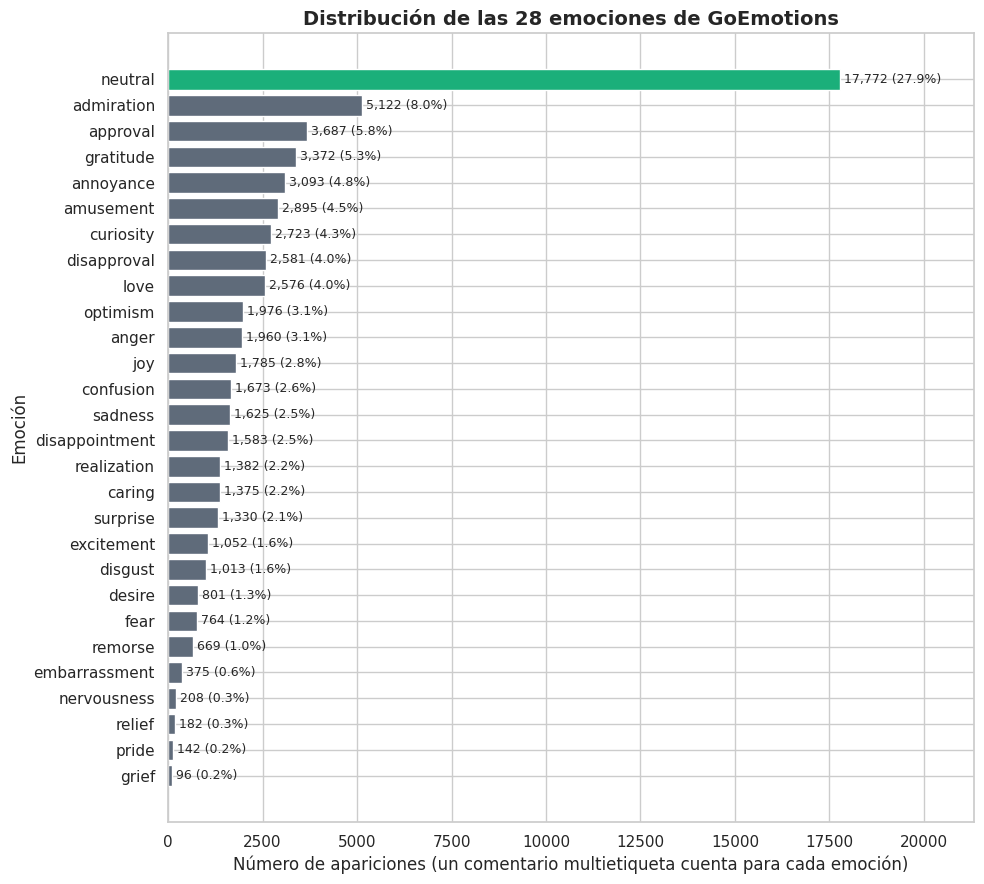

Total de apariciones: 63,812 en 54,263 comentarios
Ratio entre la emoción más frecuente y la menos frecuente: 185.1


In [91]:
conteo_emociones = df_etiquetado["emociones"].explode().value_counts()
total_apariciones = conteo_emociones.sum()

fig, ax = plt.subplots(figsize=(10, 9))
conteo_ordenado = conteo_emociones.sort_values()
colores = [PALETA_CLASES["neutral"] if e == "neutral" else COLOR_GENERAL for e in conteo_ordenado.index]
ax.barh(conteo_ordenado.index, conteo_ordenado.values, color=colores)
for i, valor in enumerate(conteo_ordenado.values):
    ax.text(valor, i, f" {valor:,} ({valor / total_apariciones:.1%})", va="center", fontsize=9)
ax.set_title("Distribución de las 28 emociones de GoEmotions")
ax.set_xlabel("Número de apariciones (un comentario multietiqueta cuenta para cada emoción)")
ax.set_ylabel("Emoción")
ax.set_xlim(0, conteo_ordenado.max() * 1.2)
plt.tight_layout()
plt.show()

print(f"Total de apariciones: {total_apariciones:,} en {len(df_etiquetado):,} comentarios")
print(f"Ratio entre la emoción más frecuente y la menos frecuente: "
      f"{conteo_emociones.iloc[0] / conteo_emociones.iloc[-1]:.1f}")

**Interpretación.** [COMPLETAR tras ejecutar: comentar el fuerte desbalance entre categorías. `neutral` es la categoría más frecuente, con [COMPLETAR] apariciones ([COMPLETAR] % del total), muy por encima de la segunda (`[COMPLETAR]`, [COMPLETAR] apariciones). Las categorías menos frecuentes (`[COMPLETAR]`, `[COMPLETAR]`) tienen apenas [COMPLETAR] apariciones, lo que da un ratio de [COMPLETAR] entre la más y la menos frecuente.]

#### 2.3.2 Análisis multietiqueta

Se cuenta cuántas etiquetas tiene cada comentario. Esto indica cuántos datos se conservarán al quedarse solo con los comentarios de una única etiqueta (subsección 2.4).

,comentarios,porcentaje
n_etiquetas,,
1,45446,83.75
2,8124,14.97
3,655,1.21
4,37,0.07
5,1,0.00


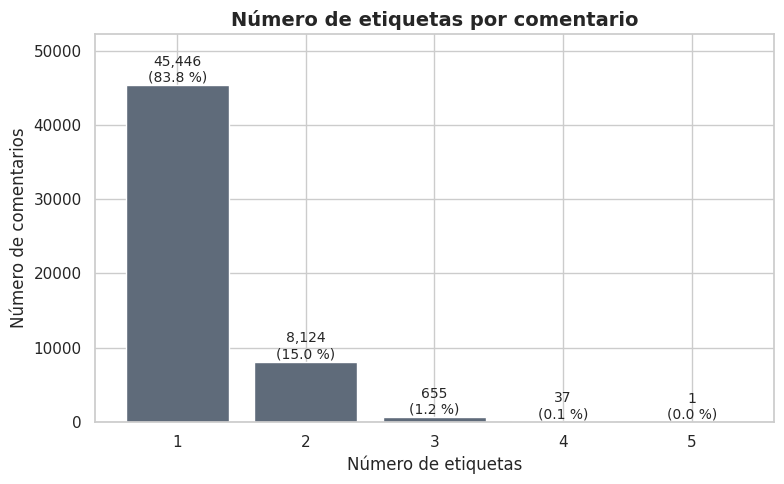

In [92]:
tabla_n_etiquetas = (
    df_etiquetado["n_etiquetas"].value_counts().sort_index()
    .rename_axis("n_etiquetas").to_frame("comentarios")
)
tabla_n_etiquetas["porcentaje"] = (tabla_n_etiquetas["comentarios"] / len(df_etiquetado) * 100).round(2)
display(tabla_n_etiquetas)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(tabla_n_etiquetas.index.astype(str), tabla_n_etiquetas["comentarios"], color=COLOR_GENERAL)
for barra, pct in zip(barras, tabla_n_etiquetas["porcentaje"]):
    ax.annotate(f"{int(barra.get_height()):,}\n({pct:.1f} %)",
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Número de etiquetas por comentario")
ax.set_xlabel("Número de etiquetas")
ax.set_ylabel("Número de comentarios")
ax.set_ylim(0, tabla_n_etiquetas["comentarios"].max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: el [COMPLETAR] % de los comentarios tiene una sola etiqueta, el [COMPLETAR] % tiene dos y solo el [COMPLETAR] % tiene tres o más. Comentar que la mayoría del dataset es de etiqueta única, por lo que filtrar los multietiqueta conserva la mayor parte de los datos.]

#### 2.3.3 Co-ocurrencias de emociones

Entre los comentarios multietiqueta se cuentan los pares de emociones que aparecen juntos. Esto sirve para evaluar la agrupación propuesta en 2.4: si dos emociones que se agruparán en la misma clase (por ejemplo, `annoyance` y `disappointment`, ambas en frustración) aparecen juntas con frecuencia, eso respalda que expresan estados parecidos. Si, en cambio, emociones de clases distintas aparecen juntas a menudo (por ejemplo, `anger` con `annoyance`), eso anticipa que esas clases serán difíciles de separar.

In [93]:
df_multi = df_etiquetado[df_etiquetado["n_etiquetas"] > 1]
conteo_pares = Counter(
    par
    for emociones in df_multi["emociones"]
    for par in itertools.combinations(sorted(emociones), 2)
)

top_pares = pd.DataFrame(
    [(a, b, n) for (a, b), n in conteo_pares.most_common(15)],
    columns=["emocion_1", "emocion_2", "comentarios"],
)
top_pares["clase_1"] = top_pares["emocion_1"].map(MAPEO_CLASES).fillna("(descartada)")
top_pares["clase_2"] = top_pares["emocion_2"].map(MAPEO_CLASES).fillna("(descartada)")
top_pares["misma_clase"] = (top_pares["clase_1"] == top_pares["clase_2"]) & (top_pares["clase_1"] != "(descartada)")
print(f"Comentarios multietiqueta: {len(df_multi):,}")
print("Top 15 de pares de emociones más frecuentes:")
display(top_pares)

Comentarios multietiqueta: 8,817
Top 15 de pares de emociones más frecuentes:


,emocion_1,emocion_2,comentarios,clase_1,clase_2,misma_clase
0,anger,annoyance,348,enojo,frustracion,False
1,admiration,gratitude,341,alegria,alegria,True
2,admiration,approval,298,alegria,alegria,True
3,approval,neutral,258,alegria,neutral,False
4,confusion,curiosity,253,confusion,(descartada),False
5,admiration,love,236,alegria,(descartada),False
6,annoyance,disapproval,222,frustracion,(descartada),False
7,annoyance,neutral,177,frustracion,neutral,False
8,disappointment,sadness,163,frustracion,(descartada),False
9,curiosity,neutral,162,(descartada),neutral,False


Para mirar en detalle las emociones que se usarán en el proyecto, el siguiente heatmap muestra las co-ocurrencias solo entre las 12 emociones que se agrupan en las cinco clases, ordenadas por clase. Los recuadros marcan los pares que quedan dentro de la misma clase.

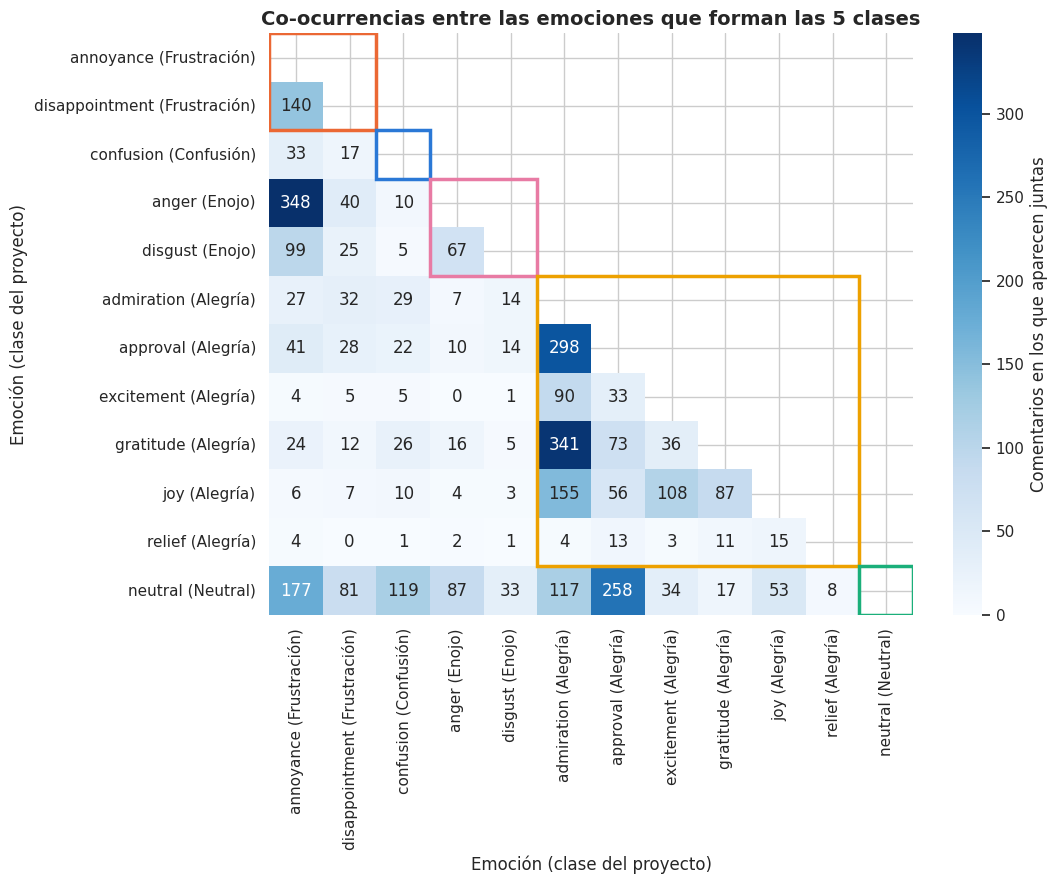

Pares de interés para la agrupación:
  annoyance + disappointment: 140 comentarios
  anger + disgust: 67 comentarios
  anger + annoyance: 348 comentarios
  annoyance + disgust: 99 comentarios
  admiration + gratitude: 341 comentarios
  excitement + joy: 108 comentarios


In [94]:
emociones_usadas = sorted(MAPEO_CLASES, key=lambda e: (ORDEN_CLASES.index(MAPEO_CLASES[e]), e))
matriz_coocurrencia = pd.DataFrame(0, index=emociones_usadas, columns=emociones_usadas)
for (a, b), n in conteo_pares.items():
    if a in MAPEO_CLASES and b in MAPEO_CLASES:
        matriz_coocurrencia.loc[a, b] += n
        matriz_coocurrencia.loc[b, a] += n

etiquetas_ejes = [f"{e} ({NOMBRES_CLASES[MAPEO_CLASES[e]]})" for e in emociones_usadas]
mascara = np.triu(np.ones_like(matriz_coocurrencia, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz_coocurrencia, mask=mascara, annot=True, fmt="d", cmap="Blues",
            xticklabels=etiquetas_ejes, yticklabels=etiquetas_ejes,
            cbar_kws={"label": "Comentarios en los que aparecen juntas"}, ax=ax)

# Recuadros que delimitan los pares de emociones de una misma clase
inicio = 0
for clase in ORDEN_CLASES:
    tamano = sum(MAPEO_CLASES[e] == clase for e in emociones_usadas)
    ax.add_patch(plt.Rectangle((inicio, inicio), tamano, tamano, fill=False,
                               edgecolor=PALETA_CLASES[clase], linewidth=2.5))
    inicio += tamano

ax.set_title("Co-ocurrencias entre las emociones que forman las 5 clases")
ax.set_xlabel("Emoción (clase del proyecto)")
ax.set_ylabel("Emoción (clase del proyecto)")
plt.tight_layout()
plt.show()

print("Pares de interés para la agrupación:")
for a, b in [("annoyance", "disappointment"), ("anger", "disgust"), ("anger", "annoyance"),
             ("annoyance", "disgust"), ("admiration", "gratitude"), ("excitement", "joy")]:
    par = tuple(sorted((a, b)))
    print(f"  {a} + {b}: {conteo_pares.get(par, 0):,} comentarios")

**Interpretación.** [COMPLETAR tras ejecutar: indicar qué pares dominan el top 15 (en GoEmotions suelen aparecer muchos pares con `neutral` y entre emociones positivas como `admiration` y `gratitude`). Comentar si `annoyance` y `disappointment` aparecen juntas ([COMPLETAR] comentarios), lo que respalda agruparlas en frustración, y cuántas veces aparecen `anger` y `annoyance` juntas ([COMPLETAR] comentarios), lo que indica que la frontera entre enojo y frustración es difusa. Lo mismo para `anger` y `disgust` ([COMPLETAR]), que forman la clase enojo.]

**Cifras clave de 2.3**

- Total de apariciones de emociones: [COMPLETAR] en [COMPLETAR] comentarios.
- Comentarios con una sola etiqueta: [COMPLETAR] ([COMPLETAR] %).
- Comentarios multietiqueta: [COMPLETAR].

### 2.4 Filtrado y agrupación en las 5 clases del proyecto

#### 2.4.1 Filtrado de comentarios con una única etiqueta

Se conservan solo los comentarios que tienen **una única etiqueta**. Hay dos razones:

1. **Evitar ejemplos ambiguos.** Un comentario anotado a la vez con, por ejemplo, `annoyance` y `joy` no tiene una emoción dominante clara, y usarlo como ejemplo de una sola clase introduciría ruido en el entrenamiento.
2. **Convertir el problema en clasificación multiclase.** El clasificador del tutor debe asignar una emoción a cada mensaje, así que cada ejemplo de entrenamiento debe tener exactamente una etiqueta.

Como se vio en 2.3.2, la gran mayoría de los comentarios son de etiqueta única, de modo que el filtro conserva la mayor parte de los datos.

In [95]:
df_una_etiqueta = df_etiquetado[df_etiquetado["n_etiquetas"] == 1].copy()
df_una_etiqueta["emocion_original"] = df_una_etiqueta["emociones"].str[0]

print(f"Filas antes del filtro: {len(df_etiquetado):,}")
print(f"Filas con una única etiqueta: {len(df_una_etiqueta):,} "
      f"({len(df_una_etiqueta) / len(df_etiquetado):.1%})")

Filas antes del filtro: 54,263
Filas con una única etiqueta: 45,446 (83.8%)


#### 2.4.2 Agrupación de las emociones en las 5 clases

Las emociones originales se agrupan en las cinco clases del proyecto según la siguiente tabla:

| Clase del proyecto | Emociones originales de GoEmotions |
|---|---|
| frustracion | annoyance, disappointment |
| confusion | confusion |
| enojo | anger, disgust |
| alegria | joy, gratitude, admiration, approval, relief, excitement |
| neutral | neutral |

Las filas cuya emoción no aparece en la tabla se descartan.

In [96]:
df_5clases = df_una_etiqueta.copy()
df_5clases["clase"] = df_5clases["emocion_original"].map(MAPEO_CLASES)

df_descartado = df_5clases[df_5clases["clase"].isna()]
df_5clases = df_5clases.dropna(subset=["clase"]).reset_index(drop=True)

print(f"Filas descartadas por no estar en la tabla: {len(df_descartado):,}")
print(f"Filas tras agrupar en 5 clases: {len(df_5clases):,}")
print("\nEmociones descartadas (comentarios de una sola etiqueta):")
display(df_descartado["emocion_original"].value_counts().rename_axis("emocion").to_frame("comentarios"))

Filas descartadas por no estar en la tabla: 13,868
Filas tras agrupar en 5 clases: 31,578

Emociones descartadas (comentarios de una sola etiqueta):


,comentarios
emocion,
amusement,2046
disapproval,1809
love,1760
curiosity,1729
optimism,1087
sadness,1003
surprise,902
caring,831
realization,749


**Justificación de los descartes.** Se conservan solo las emociones que corresponden a los estados emocionales que el tutor necesita reconocer. Las demás se descartan porque no aportan a ninguna de las cinco clases o porque introducirían ruido. Los casos más discutibles son:

- **`curiosity`**: en un contexto educativo la curiosidad indica interés y podría parecer relevante. Sin embargo, en el texto se expresa casi siempre con preguntas, igual que la confusión, y el modelo tendría muchas dificultades para distinguir "pregunto porque me interesa" de "pregunto porque no entiendo". Se excluye para no introducir ruido en la clase confusión.
- **`sadness`, `fear` y `nervousness`**: aunque la ansiedad o el desánimo pueden darse al estudiar, en Reddit estas emociones se refieren sobre todo a temas personales (duelo, enfermedades, miedos), no a dificultades de aprendizaje. Incluirlas haría que las clases aprendieran vocabulario de un dominio muy distinto al del tutor.
- **Otras emociones** como `amusement`, `love`, `caring`, `optimism`, `surprise` o `disapproval` no corresponden de forma directa a ninguna de las cinco clases, o lo hacen de forma ambigua (por ejemplo, `disapproval` puede expresar desacuerdo sin frustración ni enojo).

In [97]:
resumen_filtrado = pd.DataFrame({
    "paso": [
        "Total original (todos los splits)",
        "Con una única etiqueta",
        "Tras agrupar en 5 clases",
    ],
    "filas": [len(df_crudo), len(df_una_etiqueta), len(df_5clases)],
})
resumen_filtrado["% del total original"] = (resumen_filtrado["filas"] / len(df_crudo) * 100).round(2)
resumen_filtrado

,paso,filas,% del total original
0,Total original (todos los splits),54263,100.00
1,Con una única etiqueta,45446,83.75
2,Tras agrupar en 5 clases,31578,58.19


#### 2.4.3 Composición interna de cada clase

Se revisa cuántos ejemplos aporta cada emoción original a su clase. Si una clase depende casi por completo de una sola emoción, el modelo aprenderá en realidad esa emoción y no el concepto más amplio de la clase.

,clase,emocion_original,comentarios,% dentro de la clase
0,frustracion,annoyance,1809,67.1
1,frustracion,disappointment,888,32.9
2,confusion,confusion,1057,100.0
3,enojo,anger,1265,66.6
4,enojo,disgust,635,33.4
5,alegria,admiration,3384,34.2
6,alegria,gratitude,2378,24.0
7,alegria,approval,2367,23.9
8,alegria,joy,1052,10.6
9,alegria,excitement,619,6.3


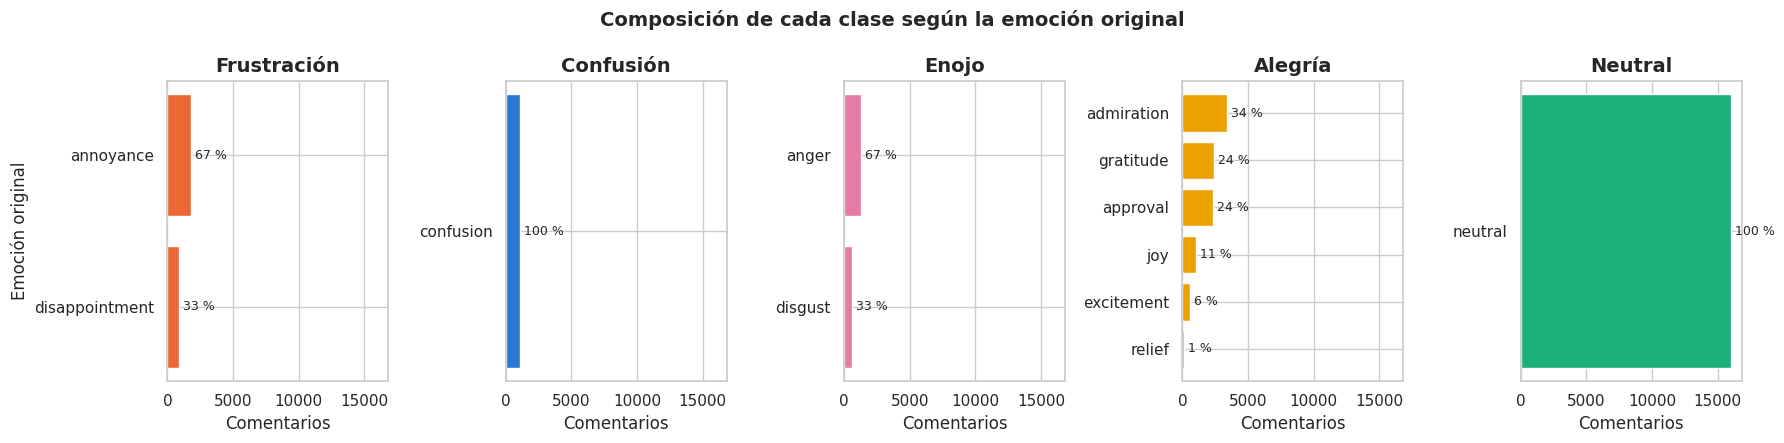

In [98]:
composicion = (
    df_5clases.groupby(["clase", "emocion_original"]).size()
    .rename("comentarios").reset_index()
)
composicion["% dentro de la clase"] = (
    composicion["comentarios"] / composicion.groupby("clase")["comentarios"].transform("sum") * 100
).round(1)
composicion["clase"] = pd.Categorical(composicion["clase"], categories=ORDEN_CLASES, ordered=True)
composicion = composicion.sort_values(["clase", "comentarios"], ascending=[True, False]).reset_index(drop=True)
display(composicion)

fig, ejes = plt.subplots(1, len(ORDEN_CLASES), figsize=(18, 4.5), sharex=True)
for ax, clase in zip(ejes, ORDEN_CLASES):
    datos = composicion[composicion["clase"] == clase].sort_values("comentarios")
    ax.barh(datos["emocion_original"], datos["comentarios"], color=PALETA_CLASES[clase])
    for i, (valor, pct) in enumerate(zip(datos["comentarios"], datos["% dentro de la clase"])):
        ax.text(valor, i, f" {pct:.0f} %", va="center", fontsize=9)
    ax.set_title(NOMBRES_CLASES[clase])
    ax.set_xlabel("Comentarios")
ejes[0].set_ylabel("Emoción original")
fig.suptitle("Composición de cada clase según la emoción original", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: indicar qué emoción domina cada clase. Por ejemplo, en alegría comentar el peso de `admiration` y `gratitude` frente a `relief`, que aporta muy pocos ejemplos; en frustración, la proporción entre `annoyance` y `disappointment`; en enojo, la proporción entre `anger` y `disgust`. Señalar si alguna clase depende casi por completo de una sola emoción ([COMPLETAR] %), lo que se tendrá en cuenta al submuestrear en 2.13.]

**Cifras clave de 2.4**

- Total original: [COMPLETAR] filas → con una única etiqueta: [COMPLETAR] → tras agrupar en 5 clases: [COMPLETAR].
- Filas descartadas por emoción fuera de la tabla: [COMPLETAR].

---

## Parte B: datasets sintéticos (GPT y Gemini)

### 2.5 Carga y verificación de los datasets sintéticos

**Origen de los datos.** GoEmotions aporta muchos ejemplos etiquetados por personas, pero son comentarios de Reddit sobre temas de todo tipo, no mensajes de estudiantes a un tutor. No existen datasets públicos de mensajes de estudiantes en español etiquetados con estas cinco emociones, así que se generaron mensajes de **contexto educativo** con dos modelos de lenguaje:

| Fuente | Modelo | Mensajes pedidos por clase | Total |
|---|---|---|---|
| `gpt` | ChatGPT | 200 | 1 000 |
| `gemini` | Gemini | 100 | 500 |

Usar dos generadores reduce la dependencia del estilo de uno solo y permite, más adelante, entrenar con uno y evaluar con el otro para comprobar si el modelo aprende la emoción o el estilo del generador.

**Prompt usado para generar los datos.**

- ChatGPT: [PEGAR AQUÍ EL PROMPT USADO]
- Gemini: [PEGAR AQUÍ EL PROMPT USADO]

**Codificación.** Los archivos se leen como UTF-8 para que las tildes, las eñes y los signos `¿` y `¡` se lean correctamente. Se usa la variante `utf-8-sig`, que es UTF-8 pero descarta la marca BOM que algunos programas (por ejemplo, Excel) escriben al inicio del archivo; con `utf-8` simple, el nombre de la primera columna se leería como `﻿texto` en lugar de `texto`.

**Verificaciones.** Para cada archivo se muestra su estructura y se comprueba que tenga exactamente las columnas `texto` y `sentimiento`, que las etiquetas sean solo las cinco del proyecto y que no haya valores nulos ni textos vacíos. Aunque los archivos ya usan las etiquetas correctas, como medida defensiva las etiquetas se normalizan igualmente (sin espacios, en minúsculas y sin tildes), y se informa si alguna fila tenía una etiqueta fuera del conjunto esperado.

In [99]:
COLUMNAS_ESPERADAS = {"texto", "sentimiento"}
PATRON_TILDES = r"[áéíóúüñÁÉÍÓÚÜÑ¿¡]"
PATRON_MOJIBAKE = "Ã|Â|�"  # restos típicos de leer UTF-8 con otra codificación


def quitar_tildes(texto):
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))


def normalizar_etiqueta(etiqueta):
    # Medida defensiva: quitar espacios, pasar a minúsculas y quitar tildes
    return quitar_tildes(str(etiqueta).strip().lower())


def verificar_sintetico(df, nombre):
    """Muestra la estructura de un CSV sintético, verifica su formato y
    devuelve una copia con las etiquetas normalizadas."""
    print(f"Dimensiones de {nombre}: {df.shape}")
    print(f"Columnas: {list(df.columns)}")
    print("\nTipos de datos:")
    print(df.dtypes.to_string())
    display(df.head())

    # 1) Columnas
    assert set(df.columns) == COLUMNAS_ESPERADAS, f"Columnas inesperadas en {nombre}: {list(df.columns)}"
    print("Columnas correctas: existen exactamente 'texto' y 'sentimiento'.")

    # 2) Codificación: deben aparecer tildes y eñes, y ningún carácter mal decodificado
    textos = df["texto"].fillna("").astype(str)
    con_tildes = textos.str.contains(PATRON_TILDES)
    print(f"\nMensajes con tildes, eñes o signos ¿ ¡: {con_tildes.sum():,}")
    print(f"Mensajes con caracteres mal decodificados (Ã, Â, �): {textos.str.contains(PATRON_MOJIBAKE).sum():,}")
    if con_tildes.any():
        print(f"Ejemplo de lectura: {textos[con_tildes].iloc[0]}")

    # 3) Etiquetas
    print("\nValores únicos de 'sentimiento' tal como vienen en el archivo:")
    display(df["sentimiento"].value_counts(dropna=False).rename_axis("sentimiento").to_frame("mensajes"))
    df_normalizado = df.copy()
    df_normalizado["sentimiento"] = df_normalizado["sentimiento"].apply(normalizar_etiqueta)
    n_modificadas = (df_normalizado["sentimiento"] != df["sentimiento"]).sum()
    fuera_de_conjunto = ~df_normalizado["sentimiento"].isin(ORDEN_CLASES)
    print(f"Etiquetas modificadas por la normalización: {n_modificadas:,}")
    print(f"Etiquetas fuera del conjunto esperado tras normalizar: {fuera_de_conjunto.sum():,}")
    if fuera_de_conjunto.any():
        display(df[fuera_de_conjunto])

    # 4) Nulos y textos vacíos
    print("\nValores nulos por columna:")
    print(df.isna().sum().to_string())
    print(f"Textos vacíos o formados solo por espacios: {(textos.str.strip() == '').sum():,}")
    return df_normalizado

#### 2.5.1 Dataset generado con GPT

In [100]:
df_gpt_crudo = pd.read_csv(RUTA_CSV_GPT, encoding="utf-8-sig")
df_gpt = verificar_sintetico(df_gpt_crudo, "GPT")

Dimensiones de GPT: (1000, 2)
Columnas: ['texto', 'sentimiento']

Tipos de datos:
texto          object
sentimiento    object


,texto,sentimiento
0,No entiendo nada de la clase de matemáticas.,frustracion
1,No entiendo nada de el tema de álgebra.,frustracion
2,No entiendo nada de la explicación de hoy.,frustracion
3,No entiendo nada de el ejercicio de física.,frustracion
4,No entiendo nada de la práctica de programación.,frustracion


Columnas correctas: existen exactamente 'texto' y 'sentimiento'.

Mensajes con tildes, eñes o signos ¿ ¡: 956
Mensajes con caracteres mal decodificados (Ã, Â, �): 0
Ejemplo de lectura: No entiendo nada de la clase de matemáticas.

Valores únicos de 'sentimiento' tal como vienen en el archivo:


,mensajes
sentimiento,
frustracion,200
confusion,200
enojo,200
alegria,200
neutral,200


Etiquetas modificadas por la normalización: 0
Etiquetas fuera del conjunto esperado tras normalizar: 0

Valores nulos por columna:
texto          0
sentimiento    0
Textos vacíos o formados solo por espacios: 0


#### 2.5.2 Dataset generado con Gemini

In [101]:
df_gemini_crudo = pd.read_csv(RUTA_CSV_GEMINI, encoding="utf-8-sig")
df_gemini = verificar_sintetico(df_gemini_crudo, "Gemini")

Dimensiones de Gemini: (500, 2)
Columnas: ['texto', 'sentimiento']

Tipos de datos:
texto          object
sentimiento    object


,texto,sentimiento
0,Estoy furioso con la calificación que me pusieron en el cuestionario.,enojo
1,Hoy vimos la introducción a este tema y dejaron lectura.,neutral
2,"¡Qué emoción, subí muchísimo mi promedio en programación!",alegria
3,¡Es injusto que pongan este ejercicio tan larga para mañana!,enojo
4,No entiendo nada de derivadas.,frustracion


Columnas correctas: existen exactamente 'texto' y 'sentimiento'.

Mensajes con tildes, eñes o signos ¿ ¡: 415
Mensajes con caracteres mal decodificados (Ã, Â, �): 0
Ejemplo de lectura: Estoy furioso con la calificación que me pusieron en el cuestionario.

Valores únicos de 'sentimiento' tal como vienen en el archivo:


,mensajes
sentimiento,
enojo,100
neutral,100
alegria,100
frustracion,100
confusion,100


Etiquetas modificadas por la normalización: 0
Etiquetas fuera del conjunto esperado tras normalizar: 0

Valores nulos por columna:
texto          0
sentimiento    0
Textos vacíos o formados solo por espacios: 0


**Interpretación.** [COMPLETAR tras ejecutar: confirmar que ambos archivos tienen exactamente las columnas `texto` y `sentimiento`, que las tildes y eñes se leen bien (ningún carácter mal decodificado), que las etiquetas son solo las cinco del proyecto (ninguna fila modificada ni fuera del conjunto) y que no hay nulos ni textos vacíos.]

**Diferencia de tamaño entre las fuentes.** El CSV de Gemini tiene **aproximadamente la mitad de registros** que el de GPT ([COMPLETAR] frente a [COMPLETAR]), y ambos son muy pequeños frente a GoEmotions. Por eso, al comparar las fuentes en el resto de la sección se usan sobre todo **proporciones** (porcentajes dentro de cada fuente, densidades en lugar de conteos, métricas calculadas sobre muestras del mismo tamaño) y no solo conteos absolutos, que harían parecer que Gemini "tiene menos" de todo solo por ser más pequeño.

**Cifras clave de 2.5**

- GPT: [COMPLETAR] filas ([COMPLETAR] por clase). Gemini: [COMPLETAR] filas ([COMPLETAR] por clase).
- Etiquetas fuera del conjunto esperado: GPT = [COMPLETAR], Gemini = [COMPLETAR]. Nulos o vacíos: GPT = [COMPLETAR], Gemini = [COMPLETAR].

### 2.6 Unificación de las tres fuentes

Las tres fuentes se llevan a un **esquema común** y se concatenan en un único DataFrame (`df_unificado`):

| Columna | GoEmotions | GPT / Gemini |
|---|---|---|
| `texto` | `text_es` | `texto` |
| `clase` | clase agrupada en 2.4 | `sentimiento` normalizado |
| `emocion_original` | emoción de GoEmotions (`annoyance`, `joy`…) | igual a `clase` |
| `fuente` | `goemotions` | `gpt` o `gemini` |

Además se conserva una columna auxiliar, `texto_ingles`, con el comentario original de Reddit (vacía en los sintéticos). Solo se usa en la revisión de la traducción (2.12) y no forma parte del dataset final.

In [102]:
def contar_por_fuente(df):
    """Número de filas de cada fuente, siempre en el mismo orden."""
    return df["fuente"].value_counts().reindex(ORDEN_FUENTES, fill_value=0)


# GoEmotions en 5 clases llevado al esquema común
df_goemotions_esquema = pd.DataFrame({
    "texto": df_5clases["text_es"],
    "clase": df_5clases["clase"],
    "emocion_original": df_5clases["emocion_original"],
    "fuente": "goemotions",
    "texto_ingles": df_5clases["text"],
})


def sintetico_a_esquema(df, fuente):
    validas = df["sentimiento"].isin(ORDEN_CLASES)
    if (~validas).any():
        print(f"{fuente}: se descartan {(~validas).sum():,} filas con una etiqueta fuera del conjunto esperado")
    df = df[validas]
    return pd.DataFrame({
        "texto": df["texto"].fillna("").astype(str),
        "clase": df["sentimiento"],
        "emocion_original": df["sentimiento"],
        "fuente": fuente,
        "texto_ingles": np.nan,
    })


df_sinteticos = pd.concat(
    [sintetico_a_esquema(df_gpt, "gpt"), sintetico_a_esquema(df_gemini, "gemini")],
    ignore_index=True,
)
df_unificado = pd.concat([df_goemotions_esquema, df_sinteticos], ignore_index=True)

print(f"Dimensiones de df_unificado: {df_unificado.shape}")
print(f"Columnas: {list(df_unificado.columns)}")

print("\nMuestra aleatoria de 3 filas por fuente:")
muestra = df_unificado.groupby("fuente", group_keys=False).sample(n=3, random_state=SEMILLA)
muestra["fuente"] = pd.Categorical(muestra["fuente"], categories=ORDEN_FUENTES, ordered=True)
display(muestra.sort_values("fuente")[["fuente", "texto", "clase", "emocion_original"]].reset_index(drop=True))

Dimensiones de df_unificado: (33078, 5)
Columnas: ['texto', 'clase', 'emocion_original', 'fuente', 'texto_ingles']

Muestra aleatoria de 3 filas por fuente:


,fuente,texto,clase,emocion_original
0,goemotions,Debajo de Springfield Illinois morador check-in. Gracias por compartir el sub ILGuns!,alegria,gratitude
1,goemotions,¡Y terminó esa etapa de la carrera sin ser eliminada! Fue un poco impresionante.,alegria,admiration
2,goemotions,Es curioso cómo lo hace.,alegria,joy
3,gpt,Hoy tenemos la clase de matemáticas según el horario.,neutral,neutral
4,gpt,El curso tiene una unidad dedicada a la tarea de química.,neutral,neutral
5,gpt,¡Me fue excelente en la evaluación de la explicación de hoy!,alegria,alegria
6,gemini,Me siento muy torpe intentando entender programación.,frustracion,frustracion
7,gemini,No me queda clara la diferencia entre la variable dependiente y el predicado.,confusion,confusion
8,gemini,¡Me felicitaron por mi desempeño en el proyecto!,alegria,alegria


In [103]:
filas_por_fuente = contar_por_fuente(df_unificado).rename("filas").to_frame()
filas_por_fuente["% del total"] = (filas_por_fuente["filas"] / len(df_unificado) * 100).round(2)
filas_por_fuente.loc["Total"] = [len(df_unificado), 100.0]
filas_por_fuente["filas"] = filas_por_fuente["filas"].astype(int)
filas_por_fuente.rename_axis("fuente")

,filas,% del total
fuente,,
goemotions,31578,95.47
gpt,1000,3.02
gemini,500,1.51
Total,33078,100.00


**Cifras clave de 2.6**

- `df_unificado`: [COMPLETAR] filas = GoEmotions [COMPLETAR] ([COMPLETAR] %) + GPT [COMPLETAR] ([COMPLETAR] %) + Gemini [COMPLETAR] ([COMPLETAR] %).
- Los datos sintéticos representan solo el [COMPLETAR] % del dataset unificado antes de la limpieza y el balanceo.

---

## Parte C: análisis del dataset unificado

### 2.7 Limpieza y duplicados

Se elimina el ruido evidente y, sobre todo, los textos repetidos o casi repetidos. Se trabaja sobre una copia (`df_limpio`), de modo que `df_unificado` se conserva intacto, y cada paso registra cuántas filas elimina **de cada fuente**.

**Por qué es importante eliminar duplicados y casi duplicados.** Los modelos se evaluarán con *repeated k-fold cross-validation*. Si dos mensajes idénticos o casi idénticos quedan uno en el conjunto de entrenamiento y otro en el de prueba de un mismo fold, el modelo "reconoce" en la prueba un texto que ya vio al entrenar. La métrica obtenida mide entonces memoria y no generalización, y queda inflada: es un caso de ***data leakage***. Este riesgo es mayor en los datos sintéticos, porque los modelos generadores tienden a repetir estructuras de frase.

**Importante:** los textos se representarán más adelante con embeddings de un modelo Sentence-BERT preentrenado. Estos modelos se entrenaron con texto natural, así que en el texto que se usará para modelar **no** se eliminan stopwords, no se aplica *stemming* ni se pasa a minúsculas: el encoder necesita el texto tal como lo escribiría una persona. Las normalizaciones que aparecen en esta sección (por ejemplo, para detectar casi duplicados) se aplican sobre copias auxiliares y solo sirven para comparar textos.

In [104]:
df_limpio = df_unificado.copy()
registro_limpieza = []


def registrar_paso(paso, df_antes, df_despues):
    """Guarda y muestra cuántas filas de cada fuente eliminó un paso de limpieza."""
    eliminadas = contar_por_fuente(df_antes) - contar_por_fuente(df_despues)
    registro_limpieza.append({"paso": paso, **eliminadas.to_dict(), "total": int(eliminadas.sum())})
    detalle = ", ".join(f"{fuente} = {n:,}" for fuente, n in eliminadas.items())
    print(f"{paso}: {int(eliminadas.sum()):,} filas eliminadas ({detalle})")

#### 2.7.1 Duplicados exactos y conflictos de etiquetas

Se buscan textos idénticos dentro de cada fuente y **entre fuentes** (en especial entre GPT y Gemini, que podrían haber generado los mismos mensajes). En la tabla, "dentro de" cuenta las copias sobrantes de un texto en la misma fuente y "entre" cuenta los textos distintos que aparecen en las dos fuentes comparadas.

Hay dos casos que se tratan de forma distinta:

- **Duplicados con la misma clase**: no aportan información nueva y provocarían *data leakage*. Se conserva una sola copia (la primera, de modo que, si un texto aparece en dos fuentes, se mantiene en el orden GoEmotions → GPT → Gemini).
- **Duplicados con clases distintas (conflicto de etiquetas)**: el mismo texto tiene dos clases diferentes. No es posible saber cuál es la correcta, así que se eliminan todas sus copias.

In [105]:
textos_por_fuente = {fuente: set(df_limpio.loc[df_limpio["fuente"] == fuente, "texto"]) for fuente in ORDEN_FUENTES}

filas = [
    {"comparación": f"dentro de {fuente}",
     "duplicados": int(df_limpio.loc[df_limpio["fuente"] == fuente, "texto"].duplicated().sum())}
    for fuente in ORDEN_FUENTES
]
filas += [
    {"comparación": f"entre {a} y {b}", "duplicados": len(textos_por_fuente[a] & textos_por_fuente[b])}
    for a, b in itertools.combinations(ORDEN_FUENTES, 2)
]
print("Duplicados exactos:")
display(pd.DataFrame(filas))

clases_por_texto = df_limpio.groupby("texto")["clase"].nunique()
textos_en_conflicto = clases_por_texto[clases_por_texto > 1].index
print(f"Textos distintos con conflicto de clases: {len(textos_en_conflicto):,}")
if len(textos_en_conflicto) > 0:
    print("Ejemplos de conflictos de etiquetas:")
    display(
        df_limpio[df_limpio["texto"].isin(textos_en_conflicto)]
        .sort_values("texto")[["texto", "clase", "emocion_original", "fuente"]]
        .head(10)
    )

Duplicados exactos:


,comparación,duplicados
0,dentro de goemotions,355
1,dentro de gpt,0
2,dentro de gemini,0
3,entre goemotions y gpt,0
4,entre goemotions y gemini,0
5,entre gpt y gemini,0


Textos distintos con conflicto de clases: 37
Ejemplos de conflictos de etiquetas:


,texto,clase,emocion_original,fuente
17698,Bien dicho.,alegria,gratitude,goemotions
25497,Bien dicho.,neutral,neutral,goemotions
17581,"Buena historia, hermano.",alegria,admiration,goemotions
23269,"Buena historia, hermano.",alegria,admiration,goemotions
1181,"Buena historia, hermano.",alegria,admiration,goemotions
6048,"Buena historia, hermano.",neutral,neutral,goemotions
25671,Cierto.,alegria,approval,goemotions
6802,Cierto.,neutral,neutral,goemotions
8219,De nada.,neutral,neutral,goemotions
25775,De nada.,alegria,gratitude,goemotions


In [106]:
# 1) Eliminar todas las copias de los textos con conflicto de clases
df_antes = df_limpio
df_limpio = df_limpio[~df_limpio["texto"].isin(textos_en_conflicto)]
registrar_paso("Conflicto de etiquetas (texto exacto)", df_antes, df_limpio)

# 2) Eliminar los duplicados restantes (misma clase), conservando la primera aparición
df_antes = df_limpio
df_limpio = df_limpio.drop_duplicates(subset="texto", keep="first")
registrar_paso("Duplicado exacto", df_antes, df_limpio)

Conflicto de etiquetas (texto exacto): 110 filas eliminadas (goemotions = 110, gpt = 0, gemini = 0)
Duplicado exacto: 282 filas eliminadas (goemotions = 282, gpt = 0, gemini = 0)


#### 2.7.2 Casi duplicados

Dos textos pueden ser prácticamente iguales sin ser idénticos: cambian una mayúscula, una tilde, un signo de puntuación o una sola palabra. Para el encoder son casi el mismo ejemplo, así que provocan el mismo *data leakage* que un duplicado exacto. Se detectan en dos pasos:

1. **Texto normalizado.** Solo para esta comparación, cada texto se pasa a minúsculas, se le quitan las tildes y la puntuación y se colapsan los espacios (las variantes de los marcadores de Reddit, como `[NAME]` y `[NOMBRE]`, se unifican antes; ver 2.7.5). Los textos que coinciden en esta versión se tratan como duplicados: si tienen la misma clase se conserva uno, y si tienen clases distintas se eliminan todos.
2. **Similitud coseno sobre TF-IDF de n-gramas de caracteres.** Cada texto normalizado se representa con los n-gramas de 3 a 5 caracteres, y se buscan los pares con **similitud coseno ≥ 0,9**. Los n-gramas de caracteres detectan textos que comparten casi todas sus palabras aunque cambie alguna (por ejemplo, "no entiendo nada de la clase de matemáticas" y "no entiendo nada de la clase de física"). El umbral es alto a propósito, para eliminar solo textos que son en esencia el mismo mensaje. De cada grupo de textos casi iguales se conserva el primero y se eliminan los demás.

In [107]:
REEMPLAZOS_MARCADORES = {
    r"\[(?:NAME|NAM|NOMBRE)\]": "[NOMBRE]",
    r"\[(?:RELIGION|RELIGIÓN)\]": "[RELIGIÓN]",
}


def normalizar_para_comparar(texto):
    # Normalización usada SOLO para comparar textos (no para el modelo)
    for patron, reemplazo in REEMPLAZOS_MARCADORES.items():
        texto = re.sub(patron, reemplazo, texto)
    texto = quitar_tildes(texto.lower())
    texto = re.sub(r"[^\w\s]", " ", texto)
    return " ".join(texto.split())


texto_comparacion = df_limpio["texto"].apply(normalizar_para_comparar)
repetidos = texto_comparacion.duplicated(keep=False)
print(f"Filas que comparten el texto normalizado con otra fila: {repetidos.sum():,}")
print("Por fuente:")
display(contar_por_fuente(df_limpio[repetidos]).rename("filas").to_frame())

if repetidos.any():
    print("Ejemplos:")
    display(
        df_limpio.assign(texto_normalizado=texto_comparacion)[repetidos]
        .sort_values("texto_normalizado")[["texto", "texto_normalizado", "clase", "fuente"]]
        .head(10)
    )

# Conflictos: mismo texto normalizado con clases distintas -> se eliminan todas las copias
clases_por_normalizado = df_limpio.groupby(texto_comparacion)["clase"].nunique()
normalizados_en_conflicto = clases_por_normalizado[clases_por_normalizado > 1].index

df_antes = df_limpio
df_limpio = df_limpio[~texto_comparacion.isin(normalizados_en_conflicto)]
registrar_paso("Conflicto de etiquetas (texto normalizado)", df_antes, df_limpio)

df_antes = df_limpio
df_limpio = df_limpio[~texto_comparacion.loc[df_limpio.index].duplicated(keep="first")]
registrar_paso("Duplicado tras normalizar el texto", df_antes, df_limpio)

Filas que comparten el texto normalizado con otra fila: 444
Por fuente:


,filas
fuente,
goemotions,444
gpt,0
gemini,0


Ejemplos:


,texto,texto_normalizado,clase,fuente
5322,¿¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!!!!!!!!!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,neutral,goemotions
20923,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,alegria,goemotions
3635,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,neutral,goemotions
1100,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!!!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,enojo,goemotions
20436,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,neutral,goemotions
18886,:((,,neutral,goemotions
28836,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,neutral,goemotions
16233,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,neutral,goemotions
7907,:^(,,neutral,goemotions
3346,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,,enojo,goemotions


Conflicto de etiquetas (texto normalizado): 100 filas eliminadas (goemotions = 100, gpt = 0, gemini = 0)
Duplicado tras normalizar el texto: 206 filas eliminadas (goemotions = 206, gpt = 0, gemini = 0)


In [108]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

UMBRAL_SIMILITUD = 0.9

textos_comparacion = df_limpio["texto"].apply(normalizar_para_comparar).to_numpy()
vectorizador_caracteres = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), dtype=np.float32)
X_caracteres = vectorizador_caracteres.fit_transform(textos_comparacion)

# Vecinos con distancia coseno <= 1 - umbral, es decir, similitud >= umbral.
# La búsqueda por fuerza bruta se calcula por bloques, así que no requiere la matriz completa en memoria.
buscador = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1).fit(X_caracteres)
vecinos = buscador.radius_neighbors(X_caracteres, radius=1 - UMBRAL_SIMILITUD, return_distance=False)

# Recorrido en orden: un texto se elimina si es casi igual a otro anterior que se conserva
conservado = np.zeros(len(df_limpio), dtype=bool)
posiciones_a_eliminar = []
pares_similares = []
for i, vecinos_i in enumerate(vecinos):
    anteriores = [j for j in vecinos_i if j < i]
    pares_similares.extend((j, i) for j in anteriores)
    if any(conservado[j] for j in anteriores):
        posiciones_a_eliminar.append(i)
    else:
        conservado[i] = True

textos = df_limpio["texto"].to_numpy()
fuentes = df_limpio["fuente"].to_numpy()
clases = df_limpio["clase"].to_numpy()
df_pares = pd.DataFrame(
    [{
        "texto_1": textos[j], "texto_2": textos[i],
        "fuente_1": fuentes[j], "fuente_2": fuentes[i],
        "clase_1": clases[j], "clase_2": clases[i],
        "similitud": float(X_caracteres[j].multiply(X_caracteres[i]).sum()),
    } for j, i in pares_similares],
    columns=["texto_1", "texto_2", "fuente_1", "fuente_2", "clase_1", "clase_2", "similitud"],
)

print(f"Pares con similitud >= {UMBRAL_SIMILITUD}: {len(df_pares):,}")
print(f"Pares con clases distintas: {(df_pares['clase_1'] != df_pares['clase_2']).sum():,}")
print("\nPares por combinación de fuentes:")
display(df_pares.groupby(["fuente_1", "fuente_2"]).size().rename("pares").to_frame())

Pares con similitud >= 0.9: 586
Pares con clases distintas: 206

Pares por combinación de fuentes:


,,pares
fuente_1,fuente_2,
gemini,gemini,3
goemotions,goemotions,583


In [109]:
print("Ejemplos de pares casi duplicados (hasta 4 por combinación de fuentes):")
for (fuente_1, fuente_2), grupo in df_pares.groupby(["fuente_1", "fuente_2"]):
    print(f"\n=== {fuente_1} / {fuente_2} ===")
    display(
        grupo.sample(min(4, len(grupo)), random_state=SEMILLA)
        [["texto_1", "texto_2", "clase_1", "clase_2", "similitud"]].round(3)
        .reset_index(drop=True)
    )

if (df_pares["clase_1"] != df_pares["clase_2"]).any():
    print("Ejemplos de pares casi iguales con clases distintas:")
    display(
        df_pares[df_pares["clase_1"] != df_pares["clase_2"]].head(8)
        [["texto_1", "clase_1", "texto_2", "clase_2", "similitud"]].round(3)
    )

Ejemplos de pares casi duplicados (hasta 4 por combinación de fuentes):

=== gemini / gemini ===


,texto_1,texto_2,clase_1,clase_2,similitud
0,Hoy vimos la introducción a este tema y dejaron lectura.,Hoy vimos la introducción a la lectura y dejaron lectura.,neutral,neutral,0.903
1,No me queda clara la diferencia entre la primera ley y el segundo método.,No me queda clara la diferencia entre el primer método y la segunda ley.,confusion,confusion,0.917
2,El profesor dijo que el examen de este tema será el próximo martes.,El profesor dijo que el examen de esta unidad será el próximo martes.,neutral,neutral,0.901



=== goemotions / goemotions ===


,texto_1,texto_2,clase_1,clase_2,similitud
0,¡Es increíble!,¡Increíble!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,alegria,alegria,0.989
1,*Hey acabo de notar..* ¡es tu **5o Cakeday** [NAME]! ^(hug),*Hey acabo de notar..* ¡es tu **2o Cakeday** [NAME]! ^(hug),alegria,neutral,0.902
2,Esto es tan cierto.,Esto es cierto...,alegria,alegria,0.928
3,¡Dios mío!,"¡Oh, Dios mío! ¡Oh, Dios mío! ¡Oh, Dios mío! ¡Oh, Dios mío!",alegria,neutral,0.914


Ejemplos de pares casi iguales con clases distintas:


,texto_1,clase_1,texto_2,clase_2,similitud
7,¡Ese es mi plan!,alegria,Ese es el plan.,neutral,0.941
13,¿Qué diablos fue eso?,enojo,¿Qué diablos es eso?,frustracion,0.936
17,Yo también pensé eso.,alegria,"Sí, yo también lo pensé :)",neutral,0.915
19,¡Fuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuu!,neutral,¡Uuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuu [NAME] golpear [NAME] con esa pregunta! ¡No puedo esperar a ver eso!,alegria,0.999
23,No es más que un rasguño.,frustracion,Es sólo un rasguño.,neutral,0.903
24,¿De verdad?,neutral,Es verdad.,alegria,0.968
25,¿Verdad?¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,neutral,Es verdad.,alegria,0.982
26,Mi nombre es [NAME],neutral,[NAME] es [NAME].,alegria,0.966


In [110]:
df_antes = df_limpio
df_limpio = df_limpio.drop(index=df_limpio.index[posiciones_a_eliminar])
registrar_paso(f"Casi duplicado (similitud TF-IDF >= {UMBRAL_SIMILITUD})", df_antes, df_limpio)

perdida_por_fuente = pd.DataFrame({
    "antes": contar_por_fuente(df_antes),
    "después": contar_por_fuente(df_limpio),
})
perdida_por_fuente["% eliminado"] = (
    (perdida_por_fuente["antes"] - perdida_por_fuente["después"]) / perdida_por_fuente["antes"] * 100
).round(2)
perdida_por_fuente

Casi duplicado (similitud TF-IDF >= 0.9): 340 filas eliminadas (goemotions = 337, gpt = 0, gemini = 3)


,antes,después,% eliminado
fuente,,,
goemotions,30880,30543,1.09
gpt,1000,1000,0.00
gemini,500,497,0.60


**Interpretación.** [COMPLETAR tras ejecutar: indicar cuántos pares casi duplicados se encontraron en cada fuente y qué porcentaje de cada fuente se eliminó; casi todos están en GoEmotions.]

Llama la atención que **GPT no pierde ningún mensaje** en este paso, a pesar de que, como se verá en la subsección siguiente, se generó con plantillas: la misma frase en la que solo cambia la materia o el tema. Este filtro compara el texto completo, y en mensajes tan cortos la parte que cambia pesa demasiado en el vector TF-IDF como para superar el umbral de 0,9. Por eso se añade un paso específico para detectar plantillas (2.7.3), que complementa a este y no lo sustituye: el filtro de similitud sigue siendo válido para los casi duplicados de GoEmotions.

#### 2.7.3 Plantillas de los generadores

**Qué es una plantilla.** Al revisar los resultados de la limpieza y del análisis de vocabulario se encontró que los generadores no produjeron mensajes independientes: usaron **frases fijas en las que solo cambia la materia o el tema**. Por ejemplo:

- GPT (frustración): "No entiendo nada de **la clase de matemáticas**." / "No entiendo nada de **el tema de álgebra**." / "No entiendo nada de **el ejercicio de física**."
- Gemini (alegría): "¡Pasé **química**, todavía no me lo creo!" / "¡Pasé **física**, todavía no me lo creo!"

**Evidencia en la propia notebook.** En la tabla de muletillas (2.10.4), todos los inicios de 2 palabras más frecuentes de GPT tenían exactamente un 5,0 % (10 de 200 mensajes por clase): cada frase aparecía con 10 temas distintos. En 2.11, la proporción de mensajes cuyo inicio de 3 palabras se repite era de 0,998 en GPT y 0,875 en Gemini, frente a 0,027 en GoEmotions.

**Por qué no lo detectó 2.7.2.** La similitud coseno sobre TF-IDF compara el texto completo. En mensajes cortos, la parte variable (el tema) es casi la mitad del texto y, además, es la que más pesa en TF-IDF, porque cada tema aparece en pocos mensajes. Por eso las variantes de una misma plantilla tienen similitudes de entre 0,2 y 0,6, muy por debajo del umbral de 0,9.

**Por qué hay que eliminarlas.** En el *repeated k-fold*, variantes de una misma plantilla quedarían repartidas entre entrenamiento y prueba de un mismo fold. El modelo reconocería la frase fija y acertaría la clase sin necesidad de entender la emoción, de modo que el F1 saldría inflado (*data leakage*).

**Cómo se detectan.** Se **enmascara la parte variable**: la materia o el tema se reemplazan por el marcador `{tema}`. Si al hacerlo dos mensajes quedan idénticos, comparten plantilla. Por ejemplo, los tres mensajes de GPT anteriores quedan como "no entiendo nada de {tema}". De cada plantilla se conserva un solo mensaje.

Este paso se aplica **solo a `gpt` y `gemini`**. GoEmotions no se toca: sus textos son comentarios reales escritos por personas distintas.

##### Paso 1: corrección gramatical de los sintéticos

Al rellenar las plantillas, los generadores produjeron contracciones incorrectas como "de el tema" o "a el capítulo". Se corrigen en el texto que se usará para modelar (`texto`): "de el" → "del" y "a el" → "al", respetando la mayúscula inicial ("De el" → "Del"). Los pronombres con tilde ("de él", "a él") no se tocan, porque el patrón solo coincide con "el" sin tilde.

Se corrige por dos razones: es un error del generador, no la forma en que escribiría un estudiante, y "de el" podría funcionar como una marca de "texto sintético" que el modelo aprendiera a asociar con la fuente en lugar de con la emoción.

In [111]:
FUENTES_SINTETICAS = ["gpt", "gemini"]
PATRON_DE_EL = r"\b([Dd])e el\b"
PATRON_A_EL = r"\b([Aa]) el\b"


def corregir_contracciones(texto):
    # "de el" -> "del" y "a el" -> "al"; "de él" y "a él" (pronombres, con tilde) no coinciden con el patrón
    texto = re.sub(PATRON_DE_EL, lambda m: m.group(1) + "el", texto)
    return re.sub(PATRON_A_EL, lambda m: m.group(1) + "l", texto)


es_sintetico = df_limpio["fuente"].isin(FUENTES_SINTETICAS)
texto_corregido = df_limpio["texto"].copy()
texto_corregido[es_sintetico] = df_limpio.loc[es_sintetico, "texto"].apply(corregir_contracciones)
corregidos = texto_corregido != df_limpio["texto"]

print("Mensajes corregidos por fuente:")
display(pd.DataFrame({
    "mensajes": contar_por_fuente(df_limpio),
    "corregidos": contar_por_fuente(df_limpio[corregidos]),
}).loc[FUENTES_SINTETICAS])

print("Ejemplos de corrección:")
display(pd.DataFrame({
    "fuente": df_limpio.loc[corregidos, "fuente"],
    "antes": df_limpio.loc[corregidos, "texto"],
    "después": texto_corregido[corregidos],
}).sample(min(8, int(corregidos.sum())), random_state=SEMILLA).reset_index(drop=True))

df_limpio = df_limpio.copy()
df_limpio["texto"] = texto_corregido

Mensajes corregidos por fuente:


,mensajes,corregidos
fuente,,
gpt,1000,132
gemini,497,40


Ejemplos de corrección:


,fuente,antes,después
0,gpt,¡Estoy emocionado por presentar mi proyecto de el tema de álgebra!,¡Estoy emocionado por presentar mi proyecto del tema de álgebra!
1,gemini,¡Me harta que cambien las reglas de el taller a última hora!,¡Me harta que cambien las reglas del taller a última hora!
2,gemini,El profesor dijo que el examen de el capítulo será el próximo martes.,El profesor dijo que el examen del capítulo será el próximo martes.
3,gpt,¡Me fue excelente en la evaluación de el tema de álgebra!,¡Me fue excelente en la evaluación del tema de álgebra!
4,gemini,¡Me encanta cuando por fin le agarro el truco a el capítulo!,¡Me encanta cuando por fin le agarro el truco al capítulo!
5,gemini,Leí las instrucciones de el cuestionario pero no entiendo qué piden.,Leí las instrucciones del cuestionario pero no entiendo qué piden.
6,gpt,En el aula revisamos algunos conceptos de el ejercicio de física.,En el aula revisamos algunos conceptos del ejercicio de física.
7,gemini,Subí el archivo de el taller a la plataforma hace un rato.,Subí el archivo del taller a la plataforma hace un rato.


##### Paso 2: lista de rellenos (materias y temas)

Para enmascarar la parte variable hace falta saber qué palabras la forman. Se usan dos listas, ambas sin tildes porque se aplican sobre el texto normalizado de `normalizar_para_comparar`:

- **Materias**, que aparecen solas ("¡Pasé química…") o detrás de un sustantivo ("la clase de matemáticas").
- **Sustantivos académicos**, que forman frases nominales de tema con la estructura *artículo o demostrativo* + (*ordinal*) + *sustantivo* + opcionalmente "de" + *materia*, "hoy" u otra frase de tema. Por ejemplo: "la clase de matemáticas", "la explicación de hoy", "el ejercicio de la clase de física", "este módulo", "el primer método".

**La lista se construye revisando los datos.** Se parte de una lista inicial con las materias y sustantivos que aparecen en los ejemplos ya vistos y se ejecuta una exploración: se agrupan los mensajes sintéticos que comparten las **4 primeras palabras** y se muestran los grupos que, tras enmascarar, siguen teniendo más de una clave. En esos grupos, las palabras que cambian entre mensajes son rellenos que faltan en la lista. Se amplía la lista con ellas y se repite la exploración hasta que no queden rellenos evidentes.

**Precaución con el sobre-enmascaramiento.** Solo se enmascara el *objeto académico* del que habla el mensaje. No se incluyen palabras de uso general que forman parte del mensaje emocional ("nada", "todo", "nunca", "otra vez"), y "hoy" solo se enmascara dentro de "de hoy" (por ejemplo, "la explicación de hoy"), no cuando aparece solo ("Hoy toca entregar…").

In [112]:
# Lista inicial: rellenos observados en los ejemplos de la notebook
MATERIAS_INICIALES = [
    "matematicas", "algebra", "calculo", "fisica", "quimica", "estadistica",
    "programacion", "historia", "ciencias", "ingles", "biologia", "literatura",
]
SUSTANTIVOS_INICIALES = [
    "clase", "tema", "ejercicio", "practica", "problema", "tarea", "proyecto", "lectura",
    "explicacion", "examen", "unidad", "capitulo", "ensayo", "evaluacion", "material",
    "modulo", "materia", "leccion", "cuestionario", "taller",
]

# Lista final, ampliada con los rellenos que reveló la exploración de las celdas siguientes
MATERIAS = MATERIAS_INICIALES + ["contabilidad", "derivadas"]
SUSTANTIVOS_ACADEMICOS = SUSTANTIVOS_INICIALES + [
    "prueba", "algoritmo", "concepto", "formula", "teoria",
    # Términos que Gemini intercambia en "No me queda clara la diferencia entre X y Y"
    "hipotesis", "sujeto", "predicado", "conclusion", "metodo", "ley",
    "variable dependiente", "variable independiente", "dependiente", "independiente",
]
ORDINALES = ["primer", "primera", "segundo", "segunda"]  # "el primer método", "la segunda ley"
DETERMINANTES = ["el", "la", "los", "las", "este", "esta", "estos", "estas", "ese", "esa"]


def construir_clave_plantilla(materias, sustantivos, ordinales=()):
    """Devuelve una función que calcula la clave de plantilla de un texto con las listas dadas."""
    def alternativa(palabras):
        # Las expresiones más largas primero, para que "variable dependiente" gane a "variable"
        return "|".join(re.escape(p) for p in sorted(palabras, key=len, reverse=True))

    materia = alternativa(materias)
    nucleo = rf"(?:{alternativa(DETERMINANTES)})\s+"
    if ordinales:
        nucleo += rf"(?:(?:{alternativa(ordinales)})\s+)?"
    nucleo += rf"(?:{alternativa(sustantivos)})(?:es|s)?"
    complemento = rf"(?:\s+de\s+(?:{materia}|hoy|{nucleo}(?:\s+de\s+(?:{materia}|hoy))?))?"
    patron_frase = re.compile(rf"\b{nucleo}{complemento}\b")
    patron_materia = re.compile(rf"\b(?:{materia})\b")

    def clave(texto):
        texto = normalizar_para_comparar(texto)
        # Se deshacen las contracciones para que "del tema" y "de la clase" tengan la misma forma
        texto = re.sub(r"\bdel\b", "de el", texto)
        texto = re.sub(r"\bal\b", "a el", texto)
        texto = patron_frase.sub("{tema}", texto)    # primero las frases nominales completas...
        texto = patron_materia.sub("{tema}", texto)  # ...después las materias sueltas
        return re.sub(r"\{tema\}(?:\s+\{tema\})+", "{tema}", texto)

    return clave


def explorar_rellenos(funcion_clave, max_grupos=12):
    """Muestra los grupos de mensajes sintéticos con las mismas 4 primeras palabras que, tras
    enmascarar, siguen teniendo claves distintas, y las palabras que cambian dentro de ellos."""
    sinteticos = df_limpio[df_limpio["fuente"].isin(FUENTES_SINTETICAS)]
    df_exploracion = pd.DataFrame({
        "fuente": sinteticos["fuente"],
        "inicio": sinteticos["texto"].apply(lambda t: " ".join(normalizar_para_comparar(t).split()[:4])),
        "clave": sinteticos["texto"].apply(funcion_clave),
    })
    claves_por_grupo = df_exploracion.groupby(["fuente", "inicio"])["clave"].unique()
    sin_unificar = claves_por_grupo[claves_por_grupo.apply(len) > 1]
    print(f"Grupos con las mismas 4 primeras palabras que siguen teniendo más de una clave: {len(sin_unificar)}")

    palabras_variables = Counter()
    for claves in sin_unificar:
        conjuntos = [set(c.split()) - {"{tema}"} for c in claves]
        comunes = set.intersection(*conjuntos)
        palabras_variables.update(p for conjunto in conjuntos for p in conjunto - comunes)

    for (fuente, inicio), claves in sin_unificar.head(max_grupos).items():
        print(f"\n[{fuente}] \"{inicio} …\" ({len(claves)} claves distintas)")
        for c in sorted(claves)[:5]:
            print(f"    {c}")
    if palabras_variables:
        print("\nPalabras más frecuentes en las posiciones que cambian dentro de un mismo grupo:")
        display(pd.Series(palabras_variables).nlargest(25).rename_axis("palabra").to_frame("apariciones"))
    return sin_unificar


clave_plantilla = construir_clave_plantilla(MATERIAS, SUSTANTIVOS_ACADEMICOS, ORDINALES)

**Exploración con la lista inicial.** Primero se ejecuta la exploración con la lista inicial, para ver qué rellenos faltan:

In [113]:
_ = explorar_rellenos(construir_clave_plantilla(MATERIAS_INICIALES, SUSTANTIVOS_INICIALES))

Grupos con las mismas 4 primeras palabras que siguen teniendo más de una clave: 47

[gemini] "alguien me puede explicar …" (2 claves distintas)
    alguien me puede explicar que hay que hacer exactamente en la prueba
    alguien me puede explicar que hay que hacer exactamente en {tema}

[gemini] "el profesor dijo que …" (5 claves distintas)
    el profesor dijo que {tema} de derivadas sera el proximo martes
    el profesor dijo que {tema} de el algoritmo sera el proximo martes
    el profesor dijo que {tema} de la formula sera el proximo martes
    el profesor dijo que {tema} de la teoria sera el proximo martes
    el profesor dijo que {tema} sera el proximo martes

[gemini] "entiendo las palabras por …" (6 claves distintas)
    entiendo las palabras por separado pero no capto la idea general de derivadas
    entiendo las palabras por separado pero no capto la idea general de el algoritmo
    entiendo las palabras por separado pero no capto la idea general de este concepto
    entiendo

,apariciones
palabra,
la,38
el,20
teoria,17
formula,16
prueba,16
este,15
concepto,15
algoritmo,15
derivadas,14


Todos los grupos sin unificar provienen de Gemini, que usa rellenos más variados que GPT. Las palabras que cambian dentro de esos grupos son los rellenos que se añadieron a la lista final:

- **Materias:** `contabilidad` y `derivadas` (por ejemplo, "Odio contabilidad…", "No entiendo nada de derivadas").
- **Sustantivos académicos:** `prueba`, `algoritmo`, `concepto`, `fórmula` y `teoría` (por ejemplo, "Por fin entendí la fórmula…", "Tengo una duda con respecto a cómo se aplica el algoritmo").
- **Términos de una plantilla de confusión de Gemini:** "No me queda clara la diferencia entre *X* y *Y*", donde *X* e *Y* toman valores como "la hipótesis", "el sujeto", "el primer método", "la segunda ley" o "la variable dependiente". Por eso se añaden esos sustantivos y los ordinales `primer`, `primera`, `segundo` y `segunda`.

**Exploración con la lista final.** Se repite la exploración con la lista ampliada:

In [114]:
grupos_sin_unificar = explorar_rellenos(clave_plantilla)

Grupos con las mismas 4 primeras palabras que siguen teniendo más de una clave: 0


[COMPLETAR tras ejecutar: confirmar que con la lista final no quedan grupos sin unificar, o que los que quedan son mensajes realmente distintos que solo comparten el comienzo.]

##### Paso 3: clave de plantilla

La función `clave_plantilla` aplica la normalización de comparación de 2.7.2 (minúsculas, sin tildes ni puntuación), reemplaza primero las frases nominales de tema y después las materias sueltas por `{tema}` (así "la clase de matemáticas" queda como un solo `{tema}` y no como "la clase de {tema}") y colapsa los marcadores consecutivos. El resultado se guarda en una columna auxiliar, `plantilla`, que solo se usa en este análisis y no forma parte del dataset final (en GoEmotions queda vacía).

In [115]:
df_limpio["plantilla"] = None  # columna auxiliar (vacía en GoEmotions)
es_sintetico = df_limpio["fuente"].isin(FUENTES_SINTETICAS)
df_limpio.loc[es_sintetico, "plantilla"] = df_limpio.loc[es_sintetico, "texto"].apply(clave_plantilla)

print("Ejemplos del texto y su clave de plantilla (10 por fuente):")
for fuente in FUENTES_SINTETICAS:
    print(f"\n=== {NOMBRES_FUENTES[fuente]} ===")
    display(df_limpio[df_limpio["fuente"] == fuente].sample(10, random_state=SEMILLA)
            [["texto", "plantilla", "clase"]].reset_index(drop=True))

Ejemplos del texto y su clave de plantilla (10 por fuente):

=== GPT ===


,texto,plantilla,clase
0,¡Basta de complicar el tema de álgebra con instrucciones confusas!,basta de complicar {tema} con instrucciones confusas,enojo
1,¡Qué satisfacción terminar la lectura de historia y saber que lo hice bien!,que satisfaccion terminar {tema} y saber que lo hice bien,alegria
2,¡Esta vez sí pude explicar la clase de matemáticas sin ayuda!,esta vez si pude explicar {tema} sin ayuda,alegria
3,¡No puedo creer que resolví correctamente todo la clase de matemáticas!,no puedo creer que resolvi correctamente todo {tema},alegria
4,¡Qué pérdida de tiempo tener que hacer el tema de álgebra de esta manera!,que perdida de tiempo tener que hacer {tema} de esta manera,enojo
5,¡Hoy sí disfruté aprender sobre el proyecto de ciencias!,hoy si disfrute aprender sobre {tema},alegria
6,¡Estoy feliz porque aprobé el problema de estadística!,estoy feliz porque aprobe {tema},alegria
7,¡No sirve de nada estudiar el ejercicio de física si después preguntan otra cosa!,no sirve de nada estudiar {tema} si despues preguntan otra cosa,enojo
8,La evaluación de la evaluación de inglés está programada para el lunes.,{tema} esta programada para el lunes,neutral
9,"No avanzo nada con el problema de estadística, por más tiempo que le dedique.",no avanzo nada con {tema} por mas tiempo que le dedique,frustracion



=== Gemini ===


,texto,plantilla,clase
0,¿Qué significa exactamente ese término dentro de estadística?,que significa exactamente ese termino dentro de {tema},confusion
1,¡Me encanta cuando por fin le agarro el truco a la teoría!,me encanta cuando por fin le agarro el truco a {tema},alegria
2,"¡Pasé esta materia, todavía no me lo creo!",pase {tema} todavia no me lo creo,alegria
3,"Vengo a clases porque toca, no porque me interese este módulo.",vengo a clases porque toca no porque me interese {tema},neutral
4,Leí las instrucciones de la prueba pero no entiendo qué piden.,lei las instrucciones de {tema} pero no entiendo que piden,confusion
5,Hoy toca entregar esta práctica antes de las doce.,hoy toca entregar {tema} antes de las doce,neutral
6,"Siento que por más que estudio derivadas, no se me queda nada.",siento que por mas que estudio {tema} no se me queda nada,frustracion
7,Estoy un poco perdido con las fechas y los requisitos del taller.,estoy un poco perdido con las fechas y los requisitos de {tema},confusion
8,No me queda clara la diferencia entre la variable dependiente y el segundo método.,no me queda clara la diferencia entre {tema} y {tema},confusion
9,"Hice el taller tal como decía la rúbrica, sin complicarme.",hice {tema} tal como decia la rubrica sin complicarme,neutral


##### Paso 4: análisis de las plantillas

Antes de eliminar nada se cuantifica el problema: cuántas plantillas distintas hay, cuántas variantes tiene cada una, si hay plantillas compartidas entre GPT y Gemini y si alguna plantilla aparece con clases distintas.

In [116]:
df_sinteticos_plantilla = df_limpio[df_limpio["fuente"].isin(FUENTES_SINTETICAS)].copy()


def resumir_plantillas(grupo):
    tamanos = grupo["plantilla"].value_counts()
    return pd.Series({
        "mensajes": len(grupo),
        "plantillas distintas": len(tamanos),
        "mensajes por plantilla (media)": round(tamanos.mean(), 2),
        "mensajes por plantilla (máximo)": tamanos.max(),
        "% que comparte plantilla": round(grupo["plantilla"].map(tamanos).gt(1).mean() * 100, 1),
    })


print("Plantillas por fuente:")
display(df_sinteticos_plantilla.groupby("fuente")[["plantilla"]].apply(resumir_plantillas)
        .reindex(FUENTES_SINTETICAS))

print("Plantillas por clase y fuente:")
tabla_plantillas_clase = (
    df_sinteticos_plantilla.groupby(["clase", "fuente"])[["plantilla"]].apply(resumir_plantillas)
    .reindex(pd.MultiIndex.from_product([ORDEN_CLASES, FUENTES_SINTETICAS], names=["clase", "fuente"]))
)
display(tabla_plantillas_clase)

Plantillas por fuente:


,mensajes,plantillas distintas,mensajes por plantilla (media),mensajes por plantilla (máximo),% que comparte plantilla
fuente,,,,,
gpt,1000.0,100.0,10.00,10.0,100.0
gemini,497.0,100.0,4.97,11.0,93.0


Plantillas por clase y fuente:


mensajes  plantillas distintas  \
clase       fuente                                   
frustracion gpt        200.0                  20.0   
            gemini     100.0                  20.0   
confusion   gpt        200.0                  20.0   
            gemini      99.0                  20.0   
enojo       gpt        200.0                  20.0   
            gemini     100.0                  20.0   
alegria     gpt        200.0                  20.0   
            gemini     100.0                  20.0   
neutral     gpt        200.0                  20.0   
            gemini      98.0                  20.0   

                    mensajes por plantilla (media)  \
clase       fuente                                   
frustracion gpt                              10.00   
            gemini                            5.00   
confusion   gpt                              10.00   
            gemini                            4.95   
enojo       gpt                              10.00   
            gemini                            5.00   
alegria     gpt                              10.00   
            gemini                            5.00   
neutral     gpt                              10.00   
            gemini                            4.90   

                    mensajes por plantilla (máximo)  % que comparte plantilla  
clase       fuente                                                             
frustracion gpt                                10.0                     100.0  
            gemini                              8.0                      95.0  
confusion   gpt                                10.0                     100.0  
            gemini                             11.0                      89.9  
enojo       gpt                                10.0                     100.0  
            gemini                             10.0                      92.0  
alegria     gpt                                10.0                     100.0  
            gemini                              8.0                      95.0  
neutral     gpt                                10.0                     100.0  
            gemini                              9.0                      92.9

In [117]:
for fuente in FUENTES_SINTETICAS:
    print(f"\n=== {NOMBRES_FUENTES[fuente]}: las 10 plantillas más repetidas ===")
    datos_fuente = df_sinteticos_plantilla[df_sinteticos_plantilla["fuente"] == fuente]
    display(
        datos_fuente.groupby("plantilla").agg(
            clase=("clase", lambda s: ", ".join(sorted(s.unique()))),
            variantes=("texto", "size"),
            ejemplo_1=("texto", "first"),
            ejemplo_2=("texto", lambda s: s.iloc[1] if len(s) > 1 else ""),
        )
        .sort_values("variantes", ascending=False).head(10).reset_index()
    )


=== GPT: las 10 plantillas más repetidas ===


,plantilla,clase,variantes,ejemplo_1,ejemplo_2
0,anote {tema} en mi cuaderno,neutral,10,Anoté los ejercicios de la clase de matemáticas en mi cuaderno.,Anoté los ejercicios del tema de álgebra en mi cuaderno.
1,basta de complicar {tema} con instrucciones confusas,enojo,10,¡Basta de complicar la clase de matemáticas con instrucciones confusas!,¡Basta de complicar el tema de álgebra con instrucciones confusas!
2,cada practica me sale mejor y hoy lo note en {tema},alegria,10,¡Cada práctica me sale mejor y hoy lo noté en la clase de matemáticas!,¡Cada práctica me sale mejor y hoy lo noté en el tema de álgebra!
3,cada vez que intento estudiar {tema} termino sintiendome incapaz,frustracion,10,"Cada vez que intento estudiar la clase de matemáticas, termino sintiéndome incapaz.","Cada vez que intento estudiar el tema de álgebra, termino sintiéndome incapaz."
4,creo que me falta un paso para comprender {tema},confusion,10,Creo que me falta un paso para comprender la clase de matemáticas.,Creo que me falta un paso para comprender el tema de álgebra.
5,cual es la relacion entre {tema} y {tema},confusion,10,¿Cuál es la relación entre este concepto y la clase de matemáticas?,¿Cuál es la relación entre este concepto y el tema de álgebra?
6,despues de practicar tanto finalmente domine {tema},alegria,10,"¡Después de practicar tanto, finalmente dominé la clase de matemáticas!","¡Después de practicar tanto, finalmente dominé el tema de álgebra!"
7,durante esta semana vamos a estudiar {tema},neutral,10,Durante esta semana vamos a estudiar la clase de matemáticas.,Durante esta semana vamos a estudiar el tema de álgebra.
8,el contenido de {tema} esta en {tema},neutral,10,El contenido de la clase de matemáticas está en el segundo capítulo.,El contenido del tema de álgebra está en el segundo capítulo.
9,el curso tiene una unidad dedicada a {tema},neutral,10,El curso tiene una unidad dedicada a la clase de matemáticas.,El curso tiene una unidad dedicada al tema de álgebra.



=== Gemini: las 10 plantillas más repetidas ===


,plantilla,clase,variantes,ejemplo_1,ejemplo_2
0,no me queda clara la diferencia entre {tema} y {tema},confusion,11,No me queda clara la diferencia entre el sujeto y la conclusión.,No me queda clara la diferencia entre la variable dependiente y el predicado.
1,alguien me puede explicar que hay que hacer exactamente en {tema},confusion,10,¿Alguien me puede explicar qué hay que hacer exactamente en el examen?,¿Alguien me puede explicar qué hay que hacer exactamente en esta práctica?
2,odio {tema} es una perdida total de tiempo,enojo,10,"Odio química, es una pérdida total de tiempo.","Odio cálculo, es una pérdida total de tiempo."
3,siento que me falta una pieza clave para entender {tema},confusion,10,Siento que me falta una pieza clave para entender derivadas.,Siento que me falta una pieza clave para entender esta unidad.
4,estoy un poco perdido con las fechas y los requisitos de {tema},confusion,9,Estoy un poco perdido con las fechas y los requisitos del cuestionario.,Estoy un poco perdido con las fechas y los requisitos del taller.
5,que significa exactamente ese termino dentro de {tema},confusion,9,¿Qué significa exactamente ese término dentro de matemáticas?,¿Qué significa exactamente ese término dentro de cálculo?
6,vengo a clases porque toca no porque me interese {tema},neutral,9,"Vengo a clases porque toca, no porque me interese este tema.","Vengo a clases porque toca, no porque me interese este módulo."
7,no tiene ningun sentido perder el tiempo memorizando {tema},enojo,9,No tiene ningún sentido perder el tiempo memorizando este tema.,No tiene ningún sentido perder el tiempo memorizando este concepto.
8,me harta que cambien las reglas de {tema} a ultima hora,enojo,9,¡Me harta que cambien las reglas del taller a última hora!,¡Me harta que cambien las reglas de este ejercicio a última hora!
9,hoy toca entregar {tema} antes de las doce,neutral,9,Hoy toca entregar el ensayo antes de las doce.,Hoy toca entregar el taller antes de las doce.


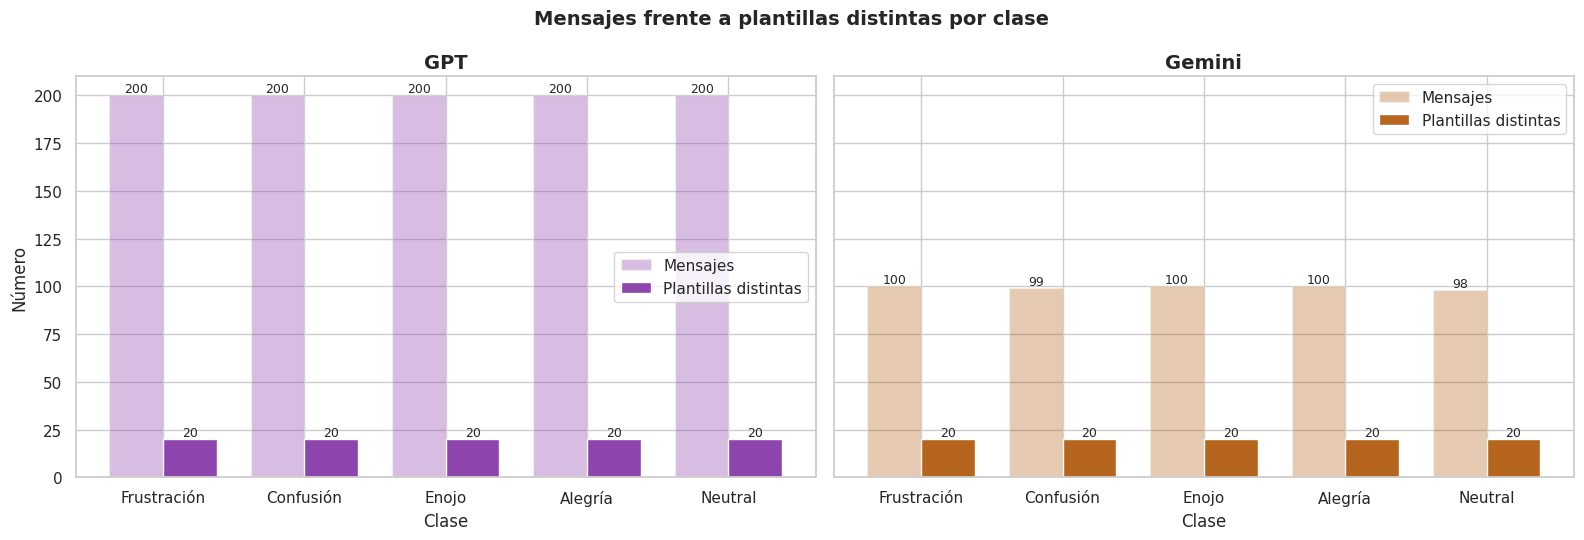

In [118]:
fig, ejes = plt.subplots(1, len(FUENTES_SINTETICAS), figsize=(16, 5.5), sharey=True)
posiciones = np.arange(len(ORDEN_CLASES))
ancho = 0.38
for ax, fuente in zip(ejes, FUENTES_SINTETICAS):
    datos = tabla_plantillas_clase.xs(fuente, level="fuente")
    barras_mensajes = ax.bar(posiciones - ancho / 2, datos["mensajes"], width=ancho,
                             color=PALETA_FUENTES[fuente], alpha=0.35, label="Mensajes")
    barras_plantillas = ax.bar(posiciones + ancho / 2, datos["plantillas distintas"], width=ancho,
                               color=PALETA_FUENTES[fuente], label="Plantillas distintas")
    for barras in (barras_mensajes, barras_plantillas):
        for barra in barras:
            ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), f"{int(barra.get_height())}",
                    ha="center", va="bottom", fontsize=9)
    ax.set_xticks(posiciones)
    ax.set_xticklabels([NOMBRES_CLASES[c] for c in ORDEN_CLASES])
    ax.set_title(NOMBRES_FUENTES[fuente])
    ax.set_xlabel("Clase")
    ax.legend()
ejes[0].set_ylabel("Número")
fig.suptitle("Mensajes frente a plantillas distintas por clase", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Plantillas compartidas y conflictos de etiqueta.** Se buscan las claves que aparecen en GPT y en Gemini a la vez, y las claves que aparecen con más de una clase (la misma estructura etiquetada, por ejemplo, como frustración en unos mensajes y como confusión en otros).

In [119]:
fuentes_por_plantilla = df_sinteticos_plantilla.groupby("plantilla")["fuente"].nunique()
plantillas_compartidas = fuentes_por_plantilla[fuentes_por_plantilla > 1].index
print(f"Plantillas que aparecen en GPT y en Gemini: {len(plantillas_compartidas)}")
if len(plantillas_compartidas) > 0:
    display(df_sinteticos_plantilla[df_sinteticos_plantilla["plantilla"].isin(plantillas_compartidas)]
            .sort_values(["plantilla", "fuente"])[["plantilla", "fuente", "clase", "texto"]]
            .reset_index(drop=True))

clases_por_plantilla = df_sinteticos_plantilla.groupby("plantilla")["clase"].nunique()
plantillas_en_conflicto = clases_por_plantilla[clases_por_plantilla > 1].index
print(f"\nPlantillas con más de una clase (conflicto de etiqueta): {len(plantillas_en_conflicto)}")
if len(plantillas_en_conflicto) > 0:
    display(df_sinteticos_plantilla[df_sinteticos_plantilla["plantilla"].isin(plantillas_en_conflicto)]
            .sort_values(["plantilla", "clase"])[["plantilla", "clase", "fuente", "texto"]]
            .reset_index(drop=True))

Plantillas que aparecen en GPT y en Gemini: 1


,plantilla,fuente,clase,texto
0,no entiendo nada de {tema},gemini,frustracion,No entiendo nada de derivadas.
1,no entiendo nada de {tema},gemini,frustracion,No entiendo nada del algoritmo.
2,no entiendo nada de {tema},gemini,frustracion,No entiendo nada de la lectura.
3,no entiendo nada de {tema},gemini,frustracion,No entiendo nada del capítulo.
4,no entiendo nada de {tema},gemini,frustracion,No entiendo nada de este módulo.
5,no entiendo nada de {tema},gpt,frustracion,No entiendo nada de la clase de matemáticas.
6,no entiendo nada de {tema},gpt,frustracion,No entiendo nada del tema de álgebra.
7,no entiendo nada de {tema},gpt,frustracion,No entiendo nada de la explicación de hoy.
8,no entiendo nada de {tema},gpt,frustracion,No entiendo nada del ejercicio de física.
9,no entiendo nada de {tema},gpt,frustracion,No entiendo nada de la práctica de programación.



Plantillas con más de una clase (conflicto de etiqueta): 0


**Revisión manual de falsos positivos.** Se muestran 15 grupos de plantilla elegidos al azar, con todas sus variantes, para comprobar que los mensajes agrupados son realmente la misma frase con distinto tema y no mensajes distintos que coinciden por casualidad tras enmascarar.

In [120]:
tamano_plantilla = df_sinteticos_plantilla["plantilla"].value_counts()
plantillas_con_variantes = pd.Series(tamano_plantilla[tamano_plantilla > 1].index)
for plantilla in plantillas_con_variantes.sample(min(15, len(plantillas_con_variantes)), random_state=SEMILLA):
    grupo = df_sinteticos_plantilla[df_sinteticos_plantilla["plantilla"] == plantilla]
    print(f"\n«{plantilla}» — {len(grupo)} variantes | clase: {', '.join(grupo['clase'].unique())} "
          f"| fuente: {', '.join(grupo['fuente'].unique())}")
    for texto in grupo["texto"]:
        print(f"    {texto}")


«siento que mi cerebro no da para entender {tema}» — 7 variantes | clase: frustracion | fuente: gemini
    Siento que mi cerebro no da para entender la fórmula.
    Siento que mi cerebro no da para entender esta unidad.
    Siento que mi cerebro no da para entender este concepto.
    Siento que mi cerebro no da para entender este tema.
    Siento que mi cerebro no da para entender derivadas.
    Siento que mi cerebro no da para entender este módulo.
    Siento que mi cerebro no da para entender la teoría.

«me bloqueo cada vez que intento empezar {tema}» — 8 variantes | clase: frustracion | fuente: gemini
    Me bloqueo cada vez que intento empezar el ensayo.
    Me bloqueo cada vez que intento empezar la tarea.
    Me bloqueo cada vez que intento empezar este problema.
    Me bloqueo cada vez que intento empezar el cuestionario.
    Me bloqueo cada vez que intento empezar esta práctica.
    Me bloqueo cada vez que intento empezar el taller.
    Me bloqueo cada vez que intento empezar

[COMPLETAR tras revisar: confirmar que todos los grupos mostrados son la misma frase con distinto tema. Si algún grupo junta mensajes distintos, ajustar la lista de rellenos del paso 2.]

##### Paso 5: eliminación

1. **Conflictos:** se eliminan **todas** las variantes de las plantillas que aparecen con más de una clase, con la misma lógica que en 2.7.1: no se puede saber qué etiqueta es la correcta.
2. **Variantes:** de cada plantilla restante se conserva **un solo mensaje**, elegido al azar con la semilla fija. No se conserva siempre el primero para no favorecer a una misma materia (en GPT, el primer mensaje de cada plantilla es siempre el de "la clase de matemáticas").
3. Si una plantilla aparece en GPT y en Gemini con la misma clase, se conserva **un único mensaje para el conjunto de ambas fuentes**, porque es la misma frase; por eso la selección se hace agrupando solo por la plantilla, sin separar por fuente.

In [121]:
# 1) Conflictos de etiqueta: se eliminan todas las variantes
df_antes = df_limpio
df_limpio = df_limpio[~df_limpio["plantilla"].isin(plantillas_en_conflicto)]
registrar_paso("Conflicto de etiquetas (plantilla)", df_antes, df_limpio)

# 2) y 3) Un mensaje por plantilla, elegido al azar, contando GPT y Gemini juntos
es_sintetico = df_limpio["fuente"].isin(FUENTES_SINTETICAS)
sinteticos_conservados = (
    df_limpio[es_sintetico]
    .groupby("plantilla", group_keys=False)
    .sample(n=1, random_state=SEMILLA)
)
df_antes = df_limpio
df_limpio = pd.concat([df_limpio[~es_sintetico], sinteticos_conservados]).sort_index()
registrar_paso("Variante de plantilla", df_antes, df_limpio)

# Mensajes antes y después por clase y fuente
sinteticos_finales = df_limpio[df_limpio["fuente"].isin(FUENTES_SINTETICAS)]
antes = pd.crosstab(df_sinteticos_plantilla["clase"], df_sinteticos_plantilla["fuente"]).reindex(
    index=ORDEN_CLASES, columns=FUENTES_SINTETICAS, fill_value=0)
despues = pd.crosstab(sinteticos_finales["clase"], sinteticos_finales["fuente"]).reindex(
    index=ORDEN_CLASES, columns=FUENTES_SINTETICAS, fill_value=0)
tabla_eliminacion = pd.concat(
    {"antes": antes, "después": despues, "% eliminado": ((antes - despues) / antes * 100).round(1)}, axis=1)
tabla_eliminacion.loc["Total"] = [
    *antes.sum(), *despues.sum(), *((antes.sum() - despues.sum()) / antes.sum() * 100).round(1)]
tabla_eliminacion

Conflicto de etiquetas (plantilla): 0 filas eliminadas (goemotions = 0, gpt = 0, gemini = 0)
Variante de plantilla: 1,298 filas eliminadas (goemotions = 0, gpt = 900, gemini = 398)


antes        después        % eliminado       
fuente          gpt gemini     gpt gemini         gpt gemini
clase                                                       
frustracion   200.0  100.0    20.0   19.0        90.0   81.0
confusion     200.0   99.0    20.0   20.0        90.0   79.8
enojo         200.0  100.0    20.0   20.0        90.0   80.0
alegria       200.0  100.0    20.0   20.0        90.0   80.0
neutral       200.0   98.0    20.0   20.0        90.0   79.6
Total        1000.0  497.0   100.0   99.0        90.0   80.1

**Materias en los mensajes conservados.** Se comprueba que la selección aleatoria no dejó una materia sobrerrepresentada, contando cuántos mensajes mencionan cada materia antes y después de eliminar las variantes.

antes        después       
fuente                    gpt gemini     gpt gemini
matematicas               100     13      11      4
algebra                   100      0      14      0
calculo                     0     15       0      3
fisica                    100     16      11      3
quimica                   100     10      11      0
estadistica               100      8       5      1
programacion              100     11       9      2
historia                  100     12      11      1
ciencias                  100      0      11      0
ingles                    100     11      11      2
biologia                    0      0       0      0
literatura                  0      0       0      0
contabilidad                0     11       0      1
derivadas                   0     15       0      2
(sin materia explícita)   100    375       6     80

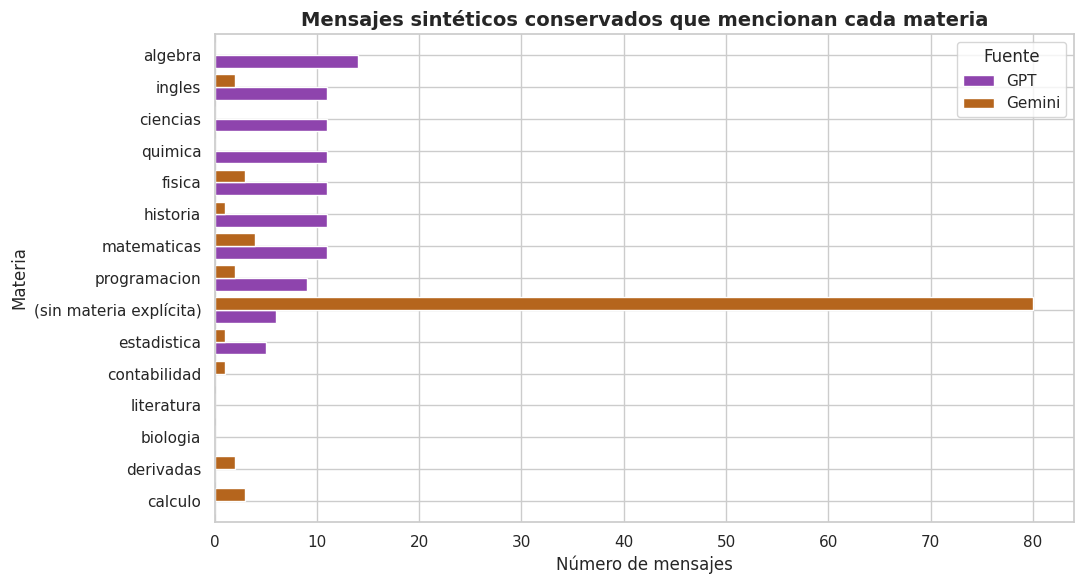

In [122]:
def contar_materias(df):
    texto_comparacion = df["texto"].apply(normalizar_para_comparar)
    menciones = pd.DataFrame({m: texto_comparacion.str.contains(rf"\b{m}\b") for m in MATERIAS})
    menciones["(sin materia explícita)"] = ~menciones.any(axis=1)
    return menciones.groupby(df["fuente"]).sum().T.reindex(columns=FUENTES_SINTETICAS, fill_value=0)


tabla_materias = pd.concat(
    {"antes": contar_materias(df_sinteticos_plantilla), "después": contar_materias(sinteticos_finales)}, axis=1)
display(tabla_materias)

materias_despues = contar_materias(sinteticos_finales)
fig, ax = plt.subplots(figsize=(11, 6))
materias_despues.sort_values("gpt").plot.barh(
    ax=ax, color=[PALETA_FUENTES[f] for f in FUENTES_SINTETICAS], width=0.8)
ax.set_title("Mensajes sintéticos conservados que mencionan cada materia")
ax.set_xlabel("Número de mensajes")
ax.set_ylabel("Materia")
ax.legend([NOMBRES_FUENTES[f] for f in FUENTES_SINTETICAS], title="Fuente")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar, con las cifras de las tablas anteriores:]

- **Mensajes efectivos.** GPT parecía aportar 200 mensajes por clase, pero en realidad tenía [COMPLETAR] plantillas (20 por clase) con [COMPLETAR] variantes cada una: sus 1 000 mensajes equivalían a [COMPLETAR] mensajes distintos. Gemini tenía [COMPLETAR] plantillas para sus [COMPLETAR] mensajes ([COMPLETAR] por clase), de las cuales [COMPLETAR] eran mensajes únicos. Tras este paso, los sintéticos pasan de [COMPLETAR] a [COMPLETAR] mensajes.
- **Fuente más repetitiva.** GPT es la más repetitiva: el [COMPLETAR] % de sus mensajes compartía plantilla, frente al [COMPLETAR] % de Gemini. Gemini combina plantillas con algunos mensajes únicos y rellenos más variados (materias, tipos de evaluación, conceptos).
- **Conflictos de etiqueta.** [COMPLETAR: indicar si hubo plantillas con clases distintas.] La plantilla compartida "no entiendo nada de {tema}" aparece en GPT y en Gemini etiquetada como **frustración**, aunque "no entiendo" es la expresión típica de la confusión. No es un conflicto dentro de los datos, pero muestra que la frontera entre frustración y confusión depende del criterio del generador, y anticipa confusiones entre ambas clases en la matriz de confusión.
- **Resultado.** Tras este paso, los sintéticos que quedan son **mensajes realmente distintos**, y ya no hay riesgo de que variantes de una misma frase queden en folds distintos de la validación cruzada. [COMPLETAR: comentar si la distribución de materias quedó equilibrada.]
- **Lección metodológica.** Un filtro de similitud sobre el texto completo, como el de 2.7.2, no detecta las plantillas generadas por LLMs: en mensajes cortos la parte variable domina la comparación. Para detectarlas hay que analizar la **estructura** de los mensajes (inicios repetidos, enmascaramiento de la parte variable). Es un hallazgo del proyecto que se recoge en las conclusiones.

#### 2.7.4 Textos muy cortos

Se eliminan los textos vacíos y los que tienen **menos de 3 palabras**. Con una o dos palabras ("Gracias", "Lol", "[NAME] jaja") casi nunca hay contexto suficiente para reconocer una emoción con seguridad, y en un dataset traducido automáticamente estos fragmentos suelen ser los peor traducidos, porque son interjecciones, abreviaturas o jerga. Además, los mensajes que un estudiante escribe a un tutor para expresar confusión o frustración suelen ser frases completas. El umbral de 3 palabras es deliberadamente bajo para eliminar solo los casos claramente insuficientes.

Se comprueba además si la regla afecta de forma desigual a alguna fuente: como los mensajes sintéticos se pidieron como frases completas, se espera que casi todos los textos eliminados provengan de Reddit.

In [123]:
UMBRAL_PALABRAS = 3

n_palabras = df_limpio["texto"].str.split().str.len()
mascara_cortos = n_palabras < UMBRAL_PALABRAS

tabla_cortos = pd.DataFrame({
    "textos": contar_por_fuente(df_limpio),
    f"con menos de {UMBRAL_PALABRAS} palabras": contar_por_fuente(df_limpio[mascara_cortos]),
})
tabla_cortos["% de la fuente"] = (tabla_cortos.iloc[:, 1] / tabla_cortos["textos"] * 100).round(2)
print(f"Textos vacíos: {(n_palabras == 0).sum():,}")
display(tabla_cortos)

print("Textos cortos por clase y fuente:")
display(pd.crosstab(df_limpio.loc[mascara_cortos, "clase"], df_limpio.loc[mascara_cortos, "fuente"])
        .reindex(index=ORDEN_CLASES, columns=ORDEN_FUENTES, fill_value=0))

for fuente in ORDEN_FUENTES:
    cortos_fuente = df_limpio[mascara_cortos & (df_limpio["fuente"] == fuente)]
    print(f"\nEjemplos de textos cortos en {NOMBRES_FUENTES[fuente]}:")
    if cortos_fuente.empty:
        print("  (ninguno)")
    else:
        display(cortos_fuente.sample(min(8, len(cortos_fuente)), random_state=SEMILLA)[["texto", "clase"]])

df_antes = df_limpio
df_limpio = df_limpio[~mascara_cortos]
registrar_paso(f"Texto con menos de {UMBRAL_PALABRAS} palabras", df_antes, df_limpio)

Textos vacíos: 0


,textos,con menos de 3 palabras,% de la fuente
fuente,,,
goemotions,30543,763,2.5
gpt,100,0,0.0
gemini,99,0,0.0


Textos cortos por clase y fuente:


fuente,goemotions,gpt,gemini
clase,,,
frustracion,28,0,0
confusion,12,0,0
enojo,65,0,0
alegria,214,0,0
neutral,444,0,0



Ejemplos de textos cortos en GoEmotions (Reddit):


,texto,clase
14145,XD,neutral
10062,Pareces divertido.,alegria
31192,Súper justo.,alegria
7119,Eres asqueroso.,enojo
13247,CUANDO ERA,neutral
24069,Estados Unidos,neutral
31374,¿BAT OLA?,neutral
4996,"¡Dulces, felicidades!",alegria



Ejemplos de textos cortos en GPT:
  (ninguno)

Ejemplos de textos cortos en Gemini:
  (ninguno)
Texto con menos de 3 palabras: 763 filas eliminadas (goemotions = 763, gpt = 0, gemini = 0)


#### 2.7.5 Marcadores de Reddit y URLs

El dataset original anonimiza los nombres de personas y de religiones con marcadores entre corchetes, como `[NAME]` o `[RELIGION]`. Al traducir, el sistema a veces los dejó en inglés y a veces los tradujo (por ejemplo, `[NOMBRE]` o `[RELIGIÓN]`), así que se cuentan todas sus variantes. También se buscan URLs. Ambos se cuentan por fuente: se espera que solo aparezcan en GoEmotions.

In [124]:
PATRON_MARCADOR = r"\[[^\[\]\s]{2,20}\]"
PATRON_URL = r"https?://\S+|www\.\S+"

marcadores = df_limpio["texto"].str.findall(PATRON_MARCADOR).explode().dropna()
print("Marcadores entre corchetes encontrados:")
display(marcadores.value_counts().rename_axis("marcador").to_frame("apariciones").head(20))

print("Textos con marcadores o URLs por fuente:")
display(pd.DataFrame({
    "textos con marcador": contar_por_fuente(df_limpio[df_limpio["texto"].str.contains(PATRON_MARCADOR)]),
    "textos con URL": contar_por_fuente(df_limpio[df_limpio["texto"].str.contains(PATRON_URL)]),
}))

Marcadores entre corchetes encontrados:


,apariciones
marcador,
[NAME],5060
[NOMBRE],461
[RELIGION],47
[RELIGIÓN],26
[NAM],3
[goshdarn],1
[get_user_id],1
[{respuesta}],1
[...],1


Textos con marcadores o URLs por fuente:


,textos con marcador,textos con URL
fuente,,
goemotions,4308,0
gpt,0,0
gemini,0,0


**Decisión.** Los marcadores **se conservan, pero se normalizan** a una única forma en español:

- `[NAME]`, `[NAM]` y `[NOMBRE]` → `[NOMBRE]`
- `[RELIGION]` y `[RELIGIÓN]` → `[RELIGIÓN]`

Se conservan porque forman parte de la estructura de la frase (por ejemplo, "Gracias, [NOMBRE]"), y eliminarlos dejaría oraciones incompletas que el encoder interpretaría peor. Se normalizan porque tener dos o tres variantes del mismo marcador hace que textos equivalentes produzcan embeddings distintos solo por un detalle de la traducción. Se elige la forma en español porque el resto del texto está en español. Los demás textos entre corchetes que aparecen pocas veces (por ejemplo, `[risas]`) son palabras normales del comentario y no se modifican.

Las URLs, si aparecen, se reemplazan por el marcador `[URL]`, porque su contenido (direcciones concretas) no aporta información emocional.

Fuera de esto, el texto no se modifica (no se pasa a minúsculas ni se quitan stopwords), por la razón explicada al inicio de 2.7.

In [125]:
df_limpio = df_limpio.copy()
for patron, reemplazo in REEMPLAZOS_MARCADORES.items():
    df_limpio["texto"] = df_limpio["texto"].str.replace(patron, reemplazo, regex=True)
df_limpio["texto"] = df_limpio["texto"].str.replace(PATRON_URL, "[URL]", regex=True)

marcadores_despues = df_limpio["texto"].str.findall(PATRON_MARCADOR).explode().dropna()
print("Marcadores más frecuentes después de normalizar:")
display(marcadores_despues.value_counts().rename_axis("marcador").to_frame("apariciones").head(5))

# Comprobación de seguridad: la normalización no debe haber creado nuevos duplicados exactos
clases_por_texto = df_limpio.groupby("texto")["clase"].nunique()
df_antes = df_limpio
df_limpio = df_limpio[~df_limpio["texto"].isin(clases_por_texto[clases_por_texto > 1].index)]
df_limpio = df_limpio.drop_duplicates(subset="texto", keep="first").reset_index(drop=True)
registrar_paso("Duplicado creado al normalizar marcadores", df_antes, df_limpio)

Marcadores más frecuentes después de normalizar:


,apariciones
marcador,
[NOMBRE],5524
[RELIGIÓN],73
[goshdarn],1
[get_user_id],1
[{respuesta}],1


Duplicado creado al normalizar marcadores: 0 filas eliminadas (goemotions = 0, gpt = 0, gemini = 0)


#### 2.7.6 Resumen de la limpieza por fuente

In [126]:
filas_inicio = contar_por_fuente(df_unificado)
filas_fin = contar_por_fuente(df_limpio)

resumen_limpieza = pd.concat([
    pd.DataFrame([{**filas_inicio.to_dict(), "total": int(filas_inicio.sum())}], index=["Filas al inicio de la limpieza"]),
    pd.DataFrame(registro_limpieza).set_index("paso")[ORDEN_FUENTES + ["total"]],
    pd.DataFrame([{**filas_fin.to_dict(), "total": int(filas_fin.sum())}], index=["Filas tras la limpieza"]),
])
porcentaje_eliminado = (filas_inicio - filas_fin) / filas_inicio * 100
resumen_limpieza.loc["% eliminado"] = [
    *porcentaje_eliminado.round(2), round((filas_inicio.sum() - filas_fin.sum()) / filas_inicio.sum() * 100, 2)
]
resumen_limpieza.rename_axis("paso")

,goemotions,gpt,gemini,total
paso,,,,
Filas al inicio de la limpieza,31578.00,1000.0,500.0,33078.00
Conflicto de etiquetas (texto exacto),110.00,0.0,0.0,110.00
Duplicado exacto,282.00,0.0,0.0,282.00
Conflicto de etiquetas (texto normalizado),100.00,0.0,0.0,100.00
Duplicado tras normalizar el texto,206.00,0.0,0.0,206.00
Casi duplicado (similitud TF-IDF >= 0.9),337.00,0.0,3.0,340.00
Conflicto de etiquetas (plantilla),0.00,0.0,0.0,0.00
Variante de plantilla,0.00,900.0,398.0,1298.00
Texto con menos de 3 palabras,763.00,0.0,0.0,763.00


**Cifras clave de 2.7**

- Filas al inicio: GoEmotions = [COMPLETAR], GPT = [COMPLETAR], Gemini = [COMPLETAR] → tras la limpieza: GoEmotions = [COMPLETAR], GPT = [COMPLETAR], Gemini = [COMPLETAR].
- Porcentaje eliminado por fuente: GoEmotions = [COMPLETAR] %, GPT = [COMPLETAR] %, Gemini = [COMPLETAR] %.
- Duplicados exactos entre fuentes: [COMPLETAR]. Casi duplicados eliminados: [COMPLETAR] (de ellos, [COMPLETAR] en GPT).
- Plantillas (2.7.3): GPT pasa de [COMPLETAR] mensajes a [COMPLETAR] (una por plantilla) y Gemini de [COMPLETAR] a [COMPLETAR]. Conflictos de etiqueta por plantilla: [COMPLETAR].
- Textos con menos de 3 palabras: [COMPLETAR] (casi todos de GoEmotions). Textos con marcadores: [COMPLETAR]. Textos con URL: [COMPLETAR].

### 2.8 Distribución de clases por fuente

Se cuantifica el desbalance entre las cinco clases y la contribución de cada fuente a cada clase. Esto condiciona la métrica de evaluación, la estrategia de balanceo y el riesgo de que el modelo aprenda el estilo de un generador en lugar de la emoción.

In [127]:
tabla_clase_fuente = pd.crosstab(df_limpio["clase"], df_limpio["fuente"], margins=True, margins_name="Total")
tabla_clase_fuente = tabla_clase_fuente.reindex(index=ORDEN_CLASES + ["Total"], columns=ORDEN_FUENTES + ["Total"],
                                                fill_value=0)
tabla_clase_fuente

fuente,goemotions,gpt,gemini,Total
clase,,,,
frustracion,2640,20,19,2679
confusion,1030,20,20,1070
enojo,1769,20,20,1809
alegria,9071,20,20,9111
neutral,15270,20,20,15310
Total,29780,100,99,29979


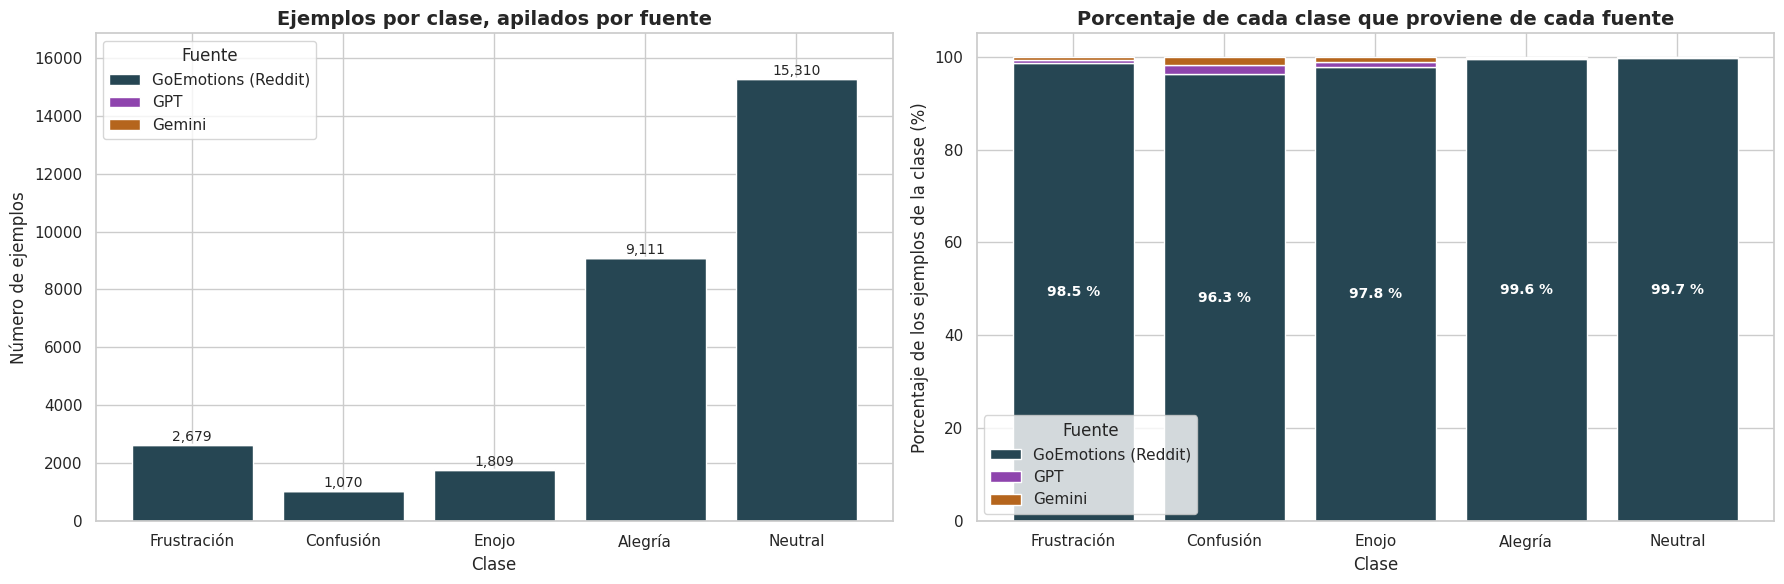

Porcentaje de los ejemplos de cada clase que proviene de cada fuente:


fuente,goemotions,gpt,gemini,sintéticos (GPT + Gemini)
clase,,,,
frustracion,98.54,0.75,0.71,1.46
confusion,96.26,1.87,1.87,3.74
enojo,97.79,1.11,1.11,2.22
alegria,99.56,0.22,0.22,0.44
neutral,99.74,0.13,0.13,0.26


In [128]:
def barras_apiladas_por_fuente(df, ax, titulo, porcentaje=False):
    """Barras por clase apiladas por fuente (conteos o porcentaje dentro de cada clase)."""
    tabla = pd.crosstab(df["clase"], df["fuente"]).reindex(index=ORDEN_CLASES, columns=ORDEN_FUENTES, fill_value=0)
    if porcentaje:
        tabla = tabla.div(tabla.sum(axis=1), axis=0) * 100
    nombres = [NOMBRES_CLASES[c] for c in ORDEN_CLASES]
    base = np.zeros(len(tabla))
    for fuente in ORDEN_FUENTES:
        valores = tabla[fuente].to_numpy(dtype=float)
        ax.bar(nombres, valores, bottom=base, color=PALETA_FUENTES[fuente], label=NOMBRES_FUENTES[fuente])
        if porcentaje:
            for x, (valor, inicio) in enumerate(zip(valores, base)):
                if valor >= 4:
                    ax.text(x, inicio + valor / 2, f"{valor:.1f} %", ha="center", va="center",
                            color="white", fontsize=10, fontweight="bold")
        base += valores
    if not porcentaje:
        for x, total in enumerate(base):
            ax.text(x, total, f"{int(total):,}", ha="center", va="bottom", fontsize=10)
        ax.set_ylim(0, base.max() * 1.1)
    ax.set_title(titulo)
    ax.set_xlabel("Clase")
    ax.set_ylabel("Porcentaje de los ejemplos de la clase (%)" if porcentaje else "Número de ejemplos")
    ax.legend(title="Fuente")
    return tabla


fig, ejes = plt.subplots(1, 2, figsize=(18, 6))
barras_apiladas_por_fuente(df_limpio, ejes[0], "Ejemplos por clase, apilados por fuente")
tabla_porcentaje_fuente = barras_apiladas_por_fuente(
    df_limpio, ejes[1], "Porcentaje de cada clase que proviene de cada fuente", porcentaje=True)
plt.tight_layout()
plt.show()

tabla_porcentaje_fuente = tabla_porcentaje_fuente.round(2)
tabla_porcentaje_fuente["sintéticos (GPT + Gemini)"] = tabla_porcentaje_fuente["gpt"] + tabla_porcentaje_fuente["gemini"]
print("Porcentaje de los ejemplos de cada clase que proviene de cada fuente:")
display(tabla_porcentaje_fuente.rename_axis("clase"))

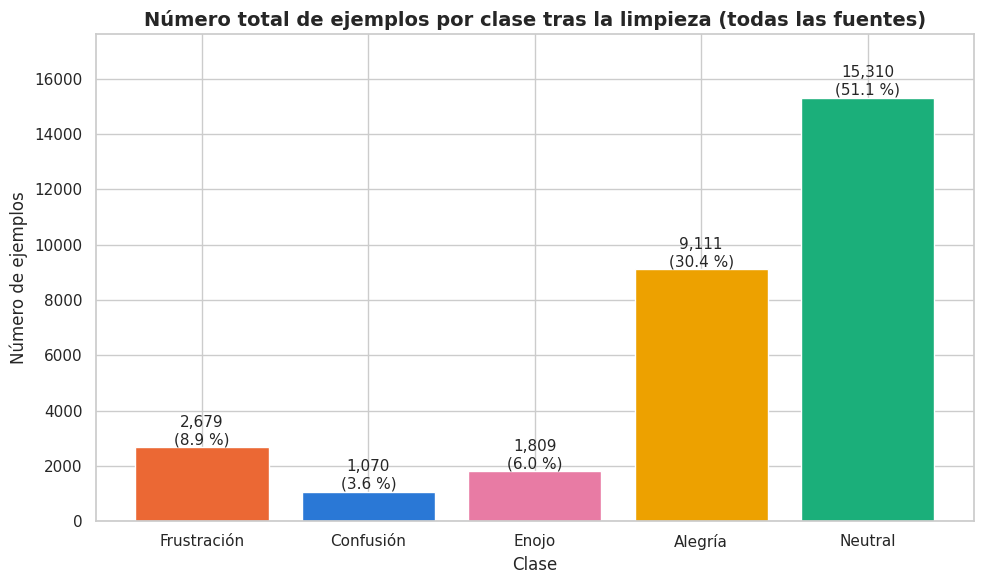

Clase mayoritaria: neutral (15,310 ejemplos)
Clase minoritaria: confusion (1,070 ejemplos)
Ratio de desbalance (mayoritaria / minoritaria): 14.3
Exactitud de un clasificador que siempre predice 'neutral': 51.1%


In [129]:
conteo_clases = df_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
porcentaje_clases = conteo_clases / conteo_clases.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar([NOMBRES_CLASES[c] for c in ORDEN_CLASES], conteo_clases.values,
                color=[PALETA_CLASES[c] for c in ORDEN_CLASES])
for barra, n, pct in zip(barras, conteo_clases.values, porcentaje_clases.values):
    ax.annotate(f"{n:,}\n({pct:.1f} %)", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=11)
ax.set_title("Número total de ejemplos por clase tras la limpieza (todas las fuentes)")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de ejemplos")
ax.set_ylim(0, conteo_clases.max() * 1.15)
plt.tight_layout()
plt.show()

ratio_desbalance = conteo_clases.max() / conteo_clases.min()
print(f"Clase mayoritaria: {conteo_clases.idxmax()} ({conteo_clases.max():,} ejemplos)")
print(f"Clase minoritaria: {conteo_clases.idxmin()} ({conteo_clases.min():,} ejemplos)")
print(f"Ratio de desbalance (mayoritaria / minoritaria): {ratio_desbalance:.1f}")
print(f"Exactitud de un clasificador que siempre predice '{conteo_clases.idxmax()}': "
      f"{conteo_clases.max() / conteo_clases.sum():.1%}")

**Interpretación.** [COMPLETAR tras ejecutar: la clase mayoritaria es `[COMPLETAR]` con [COMPLETAR] ejemplos ([COMPLETAR] %) y la minoritaria es `[COMPLETAR]` con [COMPLETAR] ejemplos ([COMPLETAR] %), lo que da un ratio de desbalance de [COMPLETAR]. Casi todo el desbalance viene de GoEmotions: los sintéticos están balanceados (tras eliminar las variantes de plantilla en 2.7.3 quedan unos 20 mensajes por clase y fuente), pero son tan pocos que apenas se ven en el gráfico de conteos.]

Este análisis tiene tres consecuencias para el resto del proyecto:

- **La exactitud (*accuracy*) no es una métrica adecuada.** Un clasificador que prediga siempre la clase mayoritaria obtendría una exactitud de [COMPLETAR] % sin haber aprendido nada, y fallaría precisamente en las clases minoritarias, que son las más importantes para el tutor (frustración, confusión, enojo). Por eso la métrica principal será el **F1-macro**, que calcula el F1 de cada clase por separado y los promedia sin ponderar, de modo que todas las clases pesan lo mismo sin importar cuántos ejemplos tengan.
- **Se necesita una estrategia de balanceo**, que se define en la subsección 2.13.
- **Dependencia de los datos sintéticos.** Las clases en las que una mayor proporción de los ejemplos proviene de GPT y Gemini son [COMPLETAR: por ejemplo, confusión, con un [COMPLETAR] % de ejemplos sintéticos]. Son las que más riesgo tienen de que el modelo aprenda el **estilo del generador** (sus frases típicas) en lugar de la emoción. Esta proporción aumentará tras el balanceo de 2.13, porque se submuestrea GoEmotions y los sintéticos se conservan completos.

**Cifras clave de 2.8**

- Ejemplos por clase tras la limpieza: frustración = [COMPLETAR], confusión = [COMPLETAR], enojo = [COMPLETAR], alegría = [COMPLETAR], neutral = [COMPLETAR].
- Ratio de desbalance: [COMPLETAR]. Porcentaje de ejemplos sintéticos por clase: de [COMPLETAR] % (`[COMPLETAR]`) a [COMPLETAR] % (`[COMPLETAR]`).

### 2.9 Longitud de los textos por clase y fuente

Se caracteriza la longitud de los textos por tres motivos:

1. Comprobar si la longitud por sí sola ya distingue las clases o las fuentes. Si así fuera, el modelo podría aprender un atajo (por ejemplo, "los textos largos son sintéticos y por tanto de una clase concreta") en lugar del contenido.
2. Detectar diferencias de estilo entre los datos reales y los sintéticos.
3. Verificar que los textos caben en el límite de entrada del encoder.

Se calcula el número de palabras y de caracteres de cada texto en una copia (`df_longitud`). El coeficiente de variación (desviación estándar / media) permite comparar la homogeneidad de las longitudes entre fuentes aunque sus medias sean distintas.

In [130]:
df_longitud = df_limpio[["texto", "clase", "fuente"]].copy()
df_longitud["n_palabras"] = df_longitud["texto"].str.split().str.len()
df_longitud["n_caracteres"] = df_longitud["texto"].str.len()


def percentil(q):
    funcion = lambda serie: serie.quantile(q)
    funcion.__name__ = f"p{int(q * 100)}"
    return funcion


AGREGACIONES = ["mean", "median", "std", "min", "max", percentil(0.25), percentil(0.75), percentil(0.95)]
NOMBRES_ESTADISTICOS = {"mean": "media", "median": "mediana", "std": "desv_est", "min": "mínimo", "max": "máximo"}

estadisticos_fuente = (
    df_longitud.groupby("fuente")[["n_palabras", "n_caracteres"]].agg(AGREGACIONES)
    .reindex(ORDEN_FUENTES).round(1)
    .rename(columns=NOMBRES_ESTADISTICOS, level=1)
)
estadisticos_fuente.columns = estadisticos_fuente.columns.set_names(["medida", "estadístico"])
print("Estadísticos de longitud por fuente:")
display(estadisticos_fuente)

coef_variacion = (
    df_longitud.groupby("fuente")["n_palabras"].std() / df_longitud.groupby("fuente")["n_palabras"].mean()
).reindex(ORDEN_FUENTES).round(2)
print("Coeficiente de variación del número de palabras por fuente:")
display(coef_variacion.rename("coef_variacion").to_frame())

print("Número de palabras por clase y fuente:")
display(
    df_longitud.groupby(["clase", "fuente"])["n_palabras"].agg(AGREGACIONES)
    .reindex(pd.MultiIndex.from_product([ORDEN_CLASES, ORDEN_FUENTES], names=["clase", "fuente"]))
    .rename(columns=NOMBRES_ESTADISTICOS).round(1)
)

Estadísticos de longitud por fuente:


medida      n_palabras                                                   \
estadístico      media mediana desv_est mínimo máximo   p25   p75   p95   
fuente                                                                    
goemotions        14.9    13.0     27.4      3    538   8.0  18.0  26.0   
gpt               11.8    12.0      1.7      7     16  11.0  13.0  15.0   
gemini            10.3    10.0      1.5      7     13   9.0  11.0  13.0   

medida      n_caracteres                                                     
estadístico        media mediana desv_est mínimo máximo   p25    p75    p95  
fuente                                                                       
goemotions          80.1    73.0     66.3      5   1168  44.0  106.0  151.0  
gpt                 69.0    69.5      8.8     45     87  63.0   75.0   83.0  
gemini              58.2    58.0      8.4     34     79  52.0   63.0   71.2

Coeficiente de variación del número de palabras por fuente:


,coef_variacion
fuente,
goemotions,1.84
gpt,0.14
gemini,0.15


Número de palabras por clase y fuente:


media  mediana  desv_est  mínimo  máximo   p25   p75  \
clase       fuente                                                             
frustracion goemotions   15.2     14.0      18.6       3     533   9.0  20.0   
            gpt          11.6     12.0       1.7       7      14  10.8  13.0   
            gemini       10.0     10.0       1.6       7      13   9.0  11.0   
confusion   goemotions   17.3     15.0      29.7       3     529  10.0  20.0   
            gpt          12.8     12.0       1.5      11      16  12.0  14.0   
            gemini       11.0     11.0       1.6       8      13   9.8  12.0   
enojo       goemotions   13.7     12.0      19.4       3     527   7.0  18.0   
            gpt          12.8     13.0       1.6      10      16  12.0  14.0   
            gemini       10.2     10.0       1.3       8      12   9.0  11.0   
alegria     goemotions   15.4     12.0      36.4       3     538   7.0  18.0   
            gpt          11.3     11.0       1.7       8      14  10.8  13.0   
            gemini        9.6      9.0       1.4       7      12   9.0  11.0   
neutral     goemotions   14.5     13.0      22.6       3     535   7.0  19.0   
            gpt          10.8     11.0       1.0       9      12  10.0  11.2   
            gemini       10.6     10.0       1.5       8      13  10.0  12.0   

                         p95  
clase       fuente            
frustracion goemotions  26.0  
            gpt         14.0  
            gemini      12.1  
confusion   goemotions  26.0  
            gpt         15.0  
            gemini      13.0  
enojo       goemotions  26.0  
            gpt         15.0  
            gemini      12.0  
alegria     goemotions  25.0  
            gpt         14.0  
            gemini      12.0  
neutral     goemotions  26.0  
            gpt         12.0  
            gemini      13.0

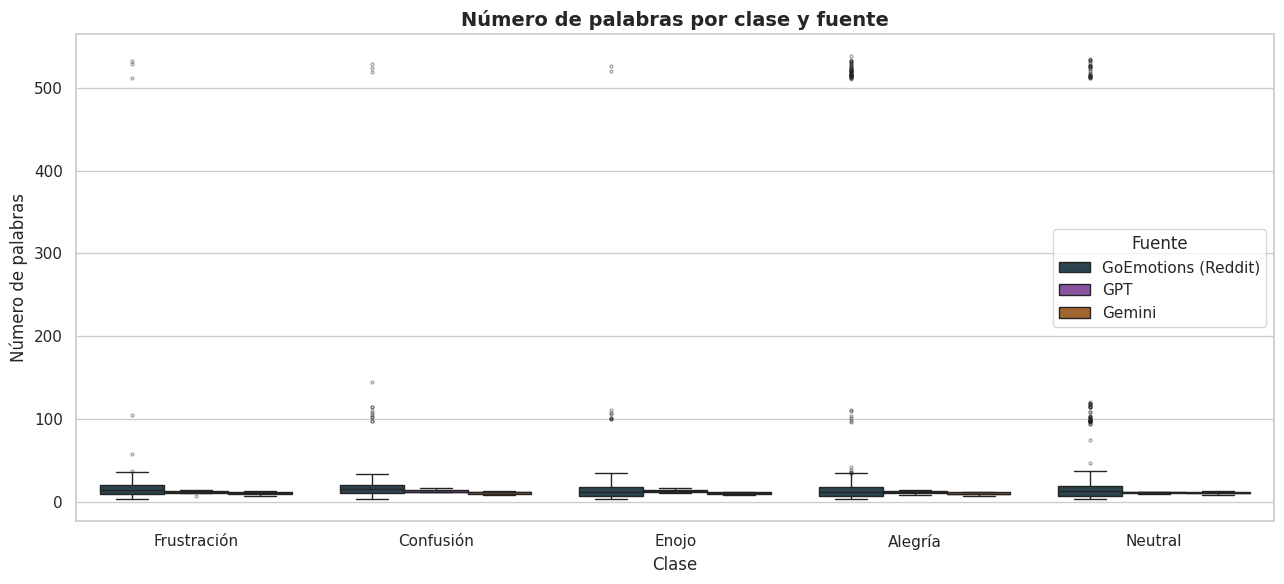

In [131]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=df_longitud, x="clase", y="n_palabras", hue="fuente",
            order=ORDEN_CLASES, hue_order=ORDEN_FUENTES, palette=PALETA_FUENTES,
            flierprops={"markersize": 2, "alpha": 0.4}, ax=ax)
ax.set_xticks(range(len(ORDEN_CLASES)))
ax.set_xticklabels([NOMBRES_CLASES[c] for c in ORDEN_CLASES])
manejadores, _ = ax.get_legend_handles_labels()
ax.legend(manejadores, [NOMBRES_FUENTES[f] for f in ORDEN_FUENTES], title="Fuente")
ax.set_title("Número de palabras por clase y fuente")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de palabras")
plt.tight_layout()
plt.show()

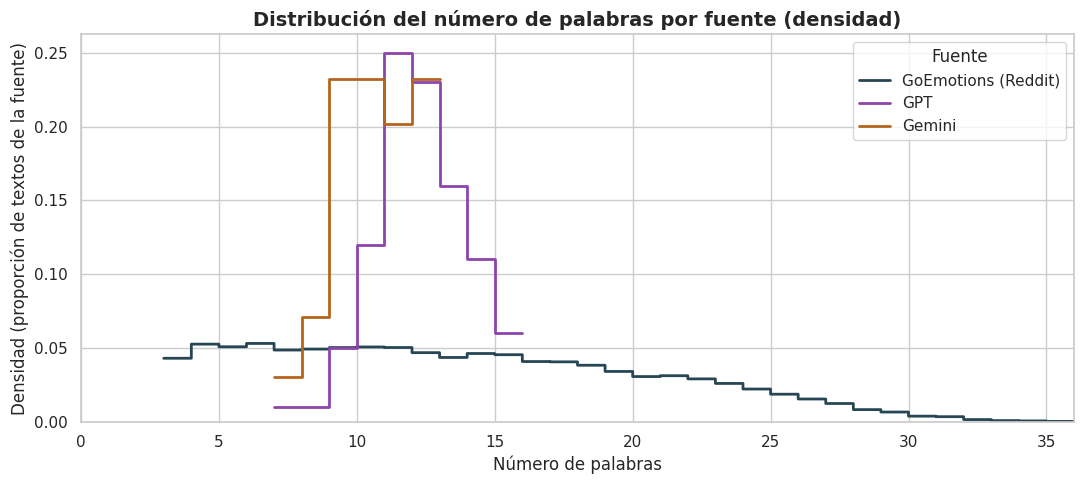

In [132]:
fig, ax = plt.subplots(figsize=(11, 5))
for fuente in ORDEN_FUENTES:
    datos = df_longitud.loc[df_longitud["fuente"] == fuente, "n_palabras"]
    sns.histplot(datos, binwidth=1, stat="density", element="step", fill=False, linewidth=2,
                 color=PALETA_FUENTES[fuente], label=NOMBRES_FUENTES[fuente], ax=ax)
ax.set_xlim(0, df_longitud["n_palabras"].quantile(0.99) + 5)
ax.set_title("Distribución del número de palabras por fuente (densidad)")
ax.set_xlabel("Número de palabras")
ax.set_ylabel("Densidad (proporción de textos de la fuente)")
ax.legend(title="Fuente")
plt.tight_layout()
plt.show()

In [133]:
LIMITE_TOKENS = 128
p95_palabras = df_longitud["n_palabras"].quantile(0.95)

print(f"Percentil 95 del número de palabras (todas las fuentes): {p95_palabras:.0f}")
print("Percentil 95 por fuente:")
print(df_longitud.groupby("fuente")["n_palabras"].quantile(0.95).reindex(ORDEN_FUENTES).to_string())
print(f"\nMáximo número de palabras: {df_longitud['n_palabras'].max()}")
print(f"Incluso suponiendo 2 tokens por palabra, el percentil 95 equivale a unos {2 * p95_palabras:.0f} tokens "
      f"(límite habitual del encoder: {LIMITE_TOKENS} tokens).")
print(f"Textos con más de {LIMITE_TOKENS // 2} palabras (posible truncación): "
      f"{(df_longitud['n_palabras'] > LIMITE_TOKENS // 2).sum():,}")

Percentil 95 del número de palabras (todas las fuentes): 26
Percentil 95 por fuente:
fuente
goemotions    26.0
gpt           15.0
gemini        13.0

Máximo número de palabras: 538
Incluso suponiendo 2 tokens por palabra, el percentil 95 equivale a unos 52 tokens (límite habitual del encoder: 128 tokens).
Textos con más de 64 palabras (posible truncación): 141


**Interpretación.** [COMPLETAR tras ejecutar:

- **Homogeneidad.** Comparar el coeficiente de variación y el rango intercuartílico de cada fuente: si los textos sintéticos tienen longitudes mucho más homogéneas que los de Reddit (cajas estrechas, densidad concentrada en pocos valores), es otra señal de un estilo artificial y repetitivo. Indicar en qué rango se concentran GPT ([COMPLETAR] palabras) y Gemini ([COMPLETAR] palabras).
- **Diferencias entre fuentes.** Indicar si la mediana de los sintéticos ([COMPLETAR]) es mayor o menor que la de Reddit ([COMPLETAR]). Si la longitud separa bien las fuentes, el modelo podría usarla como pista de la fuente; esto se revisará en el t-SNE coloreado por fuente.
- **Diferencias entre clases.** Comentar si alguna clase es notablemente más larga o más corta (por ejemplo, si `neutral` o `alegria` tienen textos más cortos que `frustracion`). Si las distribuciones se solapan mucho, la longitud por sí sola no distingue las clases y el modelo tendrá que basarse en el contenido.]

**Truncación.** Los modelos Sentence-BERT suelen truncar la entrada a 128 tokens. El número exacto de tokens depende del tokenizador del encoder que se elija, pero en español una palabra suele dividirse en uno o dos tokens. Con un percentil 95 de [COMPLETAR] palabras (unos [COMPLETAR] tokens en el peor caso), la gran mayoría de los textos cabe completa en el límite y la truncación no será un problema; solo [COMPLETAR] textos superan las 64 palabras.

**Cifras clave de 2.9**

- Mediana de palabras: GoEmotions = [COMPLETAR], GPT = [COMPLETAR], Gemini = [COMPLETAR]. Percentil 95 global: [COMPLETAR] palabras. Máximo: [COMPLETAR] palabras.
- Coeficiente de variación: GoEmotions = [COMPLETAR], GPT = [COMPLETAR], Gemini = [COMPLETAR].

### 2.10 Vocabulario por clase y fuente

Se analiza qué palabras caracterizan a cada clase, para comprobar que el contenido es coherente con la etiqueta, detectar vocabulario de dominios ajenos al educativo y encontrar **muletillas** de los generadores: frases que se repiten en muchos mensajes sintéticos.

**Normalización solo para el análisis.** Para contar palabras de forma significativa, aquí (y solo aquí, no para el modelo) se aplica una normalización mínima: paso a minúsculas, eliminación de la puntuación y de los números, eliminación de los marcadores (`[NOMBRE]`, `[RELIGIÓN]`, `[URL]`) y eliminación de las *stopwords* en español de la lista de spaCy. Sin esto, las palabras más frecuentes de todas las clases serían "de", "que" o "la", que no dicen nada sobre la emoción. El texto que se usará para el modelo (`texto`) no se modifica.

In [134]:
from spacy.lang.es.stop_words import STOP_WORDS

STOPWORDS_ES = {palabra.lower() for palabra in STOP_WORDS}


def normalizar_para_analisis(texto):
    # Normalización mínima, solo para el análisis de vocabulario
    texto = re.sub(PATRON_MARCADOR, " ", texto)      # quitar marcadores como [NOMBRE]
    texto = texto.lower()
    texto = re.sub(r"[^\w\s]|\d|_", " ", texto)      # quitar puntuación, números y guiones bajos
    return [palabra for palabra in texto.split() if palabra not in STOPWORDS_ES and len(palabra) > 1]


df_vocabulario = df_limpio[["texto", "clase", "fuente"]].copy()
df_vocabulario["tokens"] = df_vocabulario["texto"].apply(normalizar_para_analisis)
df_vocabulario["texto_normalizado"] = df_vocabulario["tokens"].str.join(" ")

print(f"Stopwords en español (spaCy): {len(STOPWORDS_ES)}")
df_vocabulario.groupby("fuente", group_keys=False).sample(2, random_state=SEMILLA)[["fuente", "texto", "texto_normalizado"]]

Stopwords en español (spaCy): 521


,fuente,texto,texto_normalizado
29942,gemini,"¡Ya la libré, aprobé el semestre sin irme a final!",libré aprobé semestre irme
29920,gemini,No estoy seguro de si estoy usando el método correcto para el proyecto.,seguro usando método correcto proyecto
20631,goemotions,> y dos veces el domingo Sí voy a usar que cualquier día de la semana a partir de ahora y dos veces el domingo,domingo semana domingo
8387,goemotions,"Ok pero quien va a tomar uno para el equipo y hacer su estilo ""come Xanax y se mueve""",ok tomar equipo estilo come xanax mueve
29799,gpt,Me desespera no poder hacer bien el problema de estadística.,desespera problema estadística
29785,gpt,Estoy bloqueado; no sé ni por dónde empezar con la evaluación de inglés.,bloqueado empezar evaluación inglés


#### 2.10.1 Palabras más frecuentes por clase (dataset unificado)

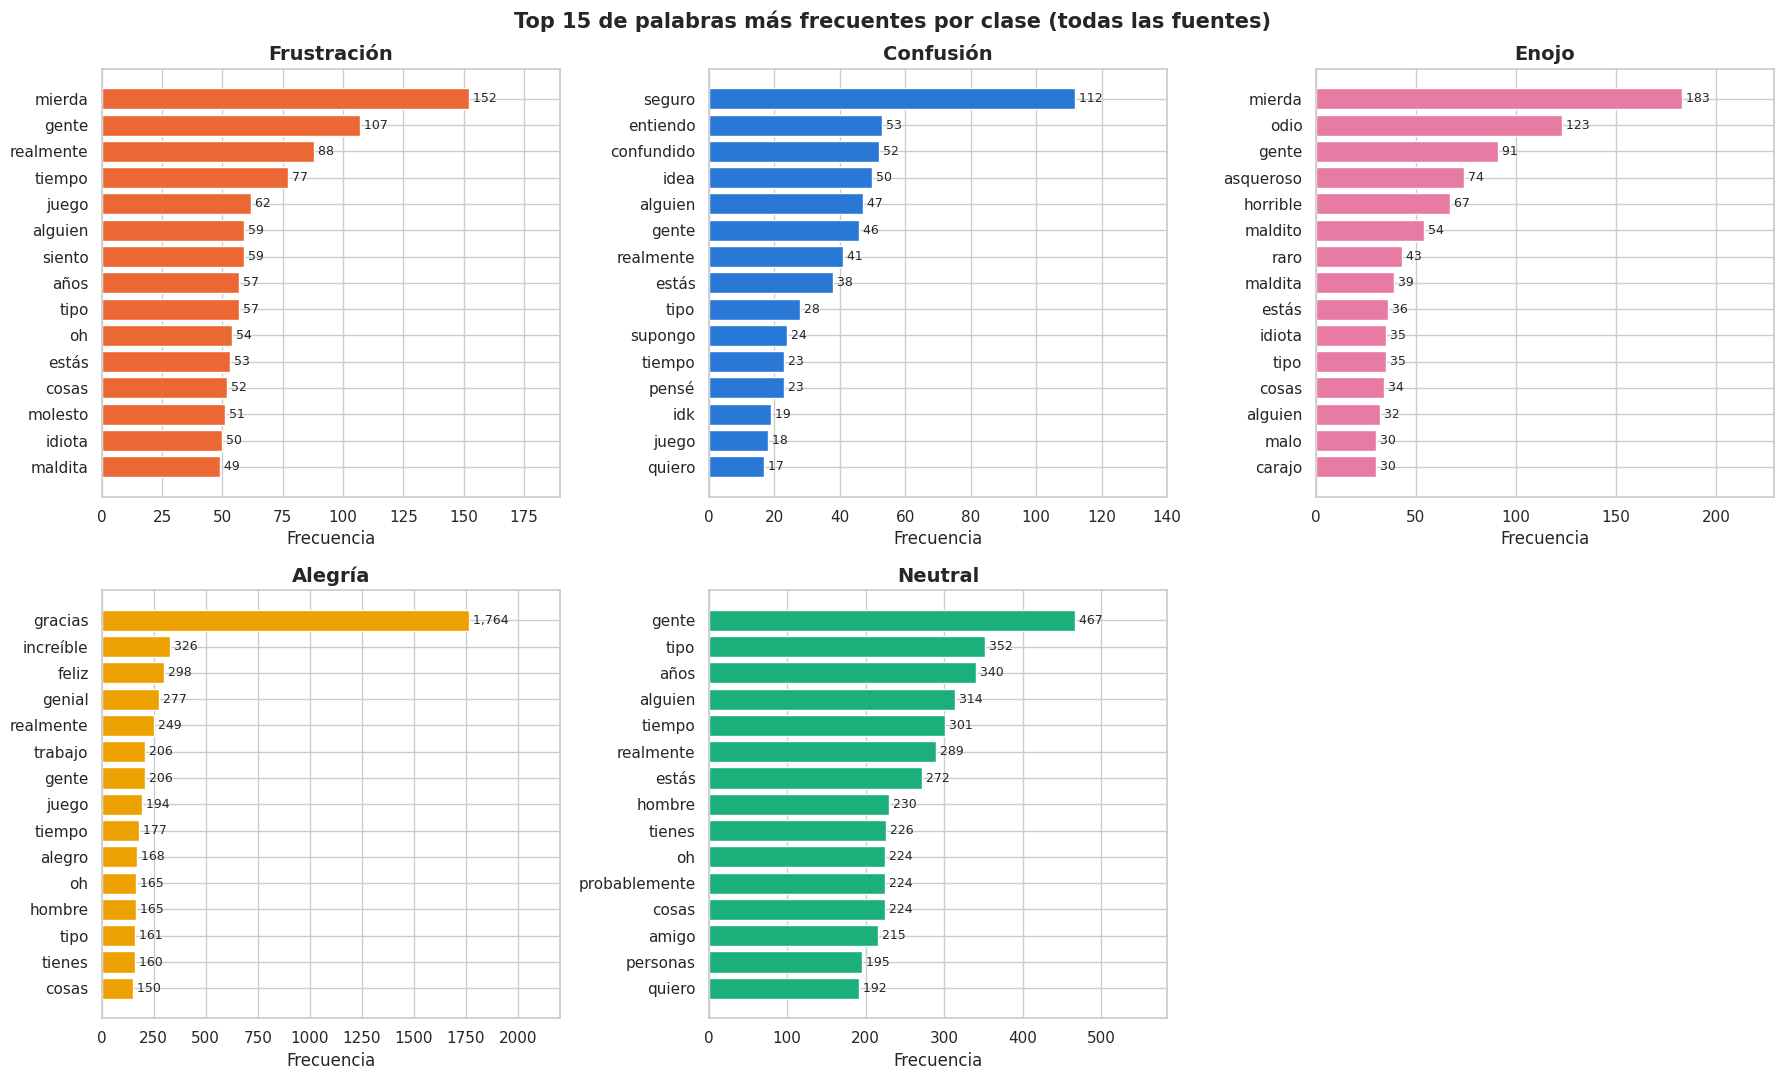

In [135]:
TOP_PALABRAS = 15


def graficar_top_por_clase(top_por_clase, titulo, etiqueta_x, formato="{:,.0f}"):
    fig, ejes = plt.subplots(2, 3, figsize=(18, 11))
    ejes = ejes.flatten()
    for ax, clase in zip(ejes, ORDEN_CLASES):
        datos = top_por_clase[clase].sort_values()
        ax.barh(datos.index, datos.values, color=PALETA_CLASES[clase])
        for i, valor in enumerate(datos.values):
            ax.text(valor, i, " " + formato.format(valor), va="center", fontsize=9)
        ax.set_xlim(0, datos.max() * 1.25)
        ax.set_title(NOMBRES_CLASES[clase])
        ax.set_xlabel(etiqueta_x)
    ejes[-1].axis("off")
    fig.suptitle(titulo, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()


top_frecuencia = {
    clase: pd.Series(Counter(
        palabra for tokens in df_vocabulario.loc[df_vocabulario["clase"] == clase, "tokens"] for palabra in tokens
    )).nlargest(TOP_PALABRAS)
    for clase in ORDEN_CLASES
}
graficar_top_por_clase(top_frecuencia, f"Top {TOP_PALABRAS} de palabras más frecuentes por clase (todas las fuentes)",
                       "Frecuencia")

Como GoEmotions tiene muchos más textos que los sintéticos, la frecuencia del dataset unificado refleja sobre todo el vocabulario de Reddit. Para compararlo con el de GPT y Gemini se usa el TF-IDF promedio (que destaca el vocabulario propio de cada clase) y, a continuación, el desglose por fuente.

#### 2.10.2 Palabras características por clase según TF-IDF promedio

La frecuencia cruda favorece las palabras comunes a todas las clases. El **TF-IDF** reduce el peso de las palabras que aparecen en muchos textos, así que el promedio del TF-IDF de cada palabra dentro de una clase destaca mejor el vocabulario propio de esa clase. Se consideran solo palabras que aparecen en al menos 5 textos, para evitar que palabras rarísimas dominen el ranking.

Tamaño del vocabulario (palabras en al menos 5 textos): 5,272


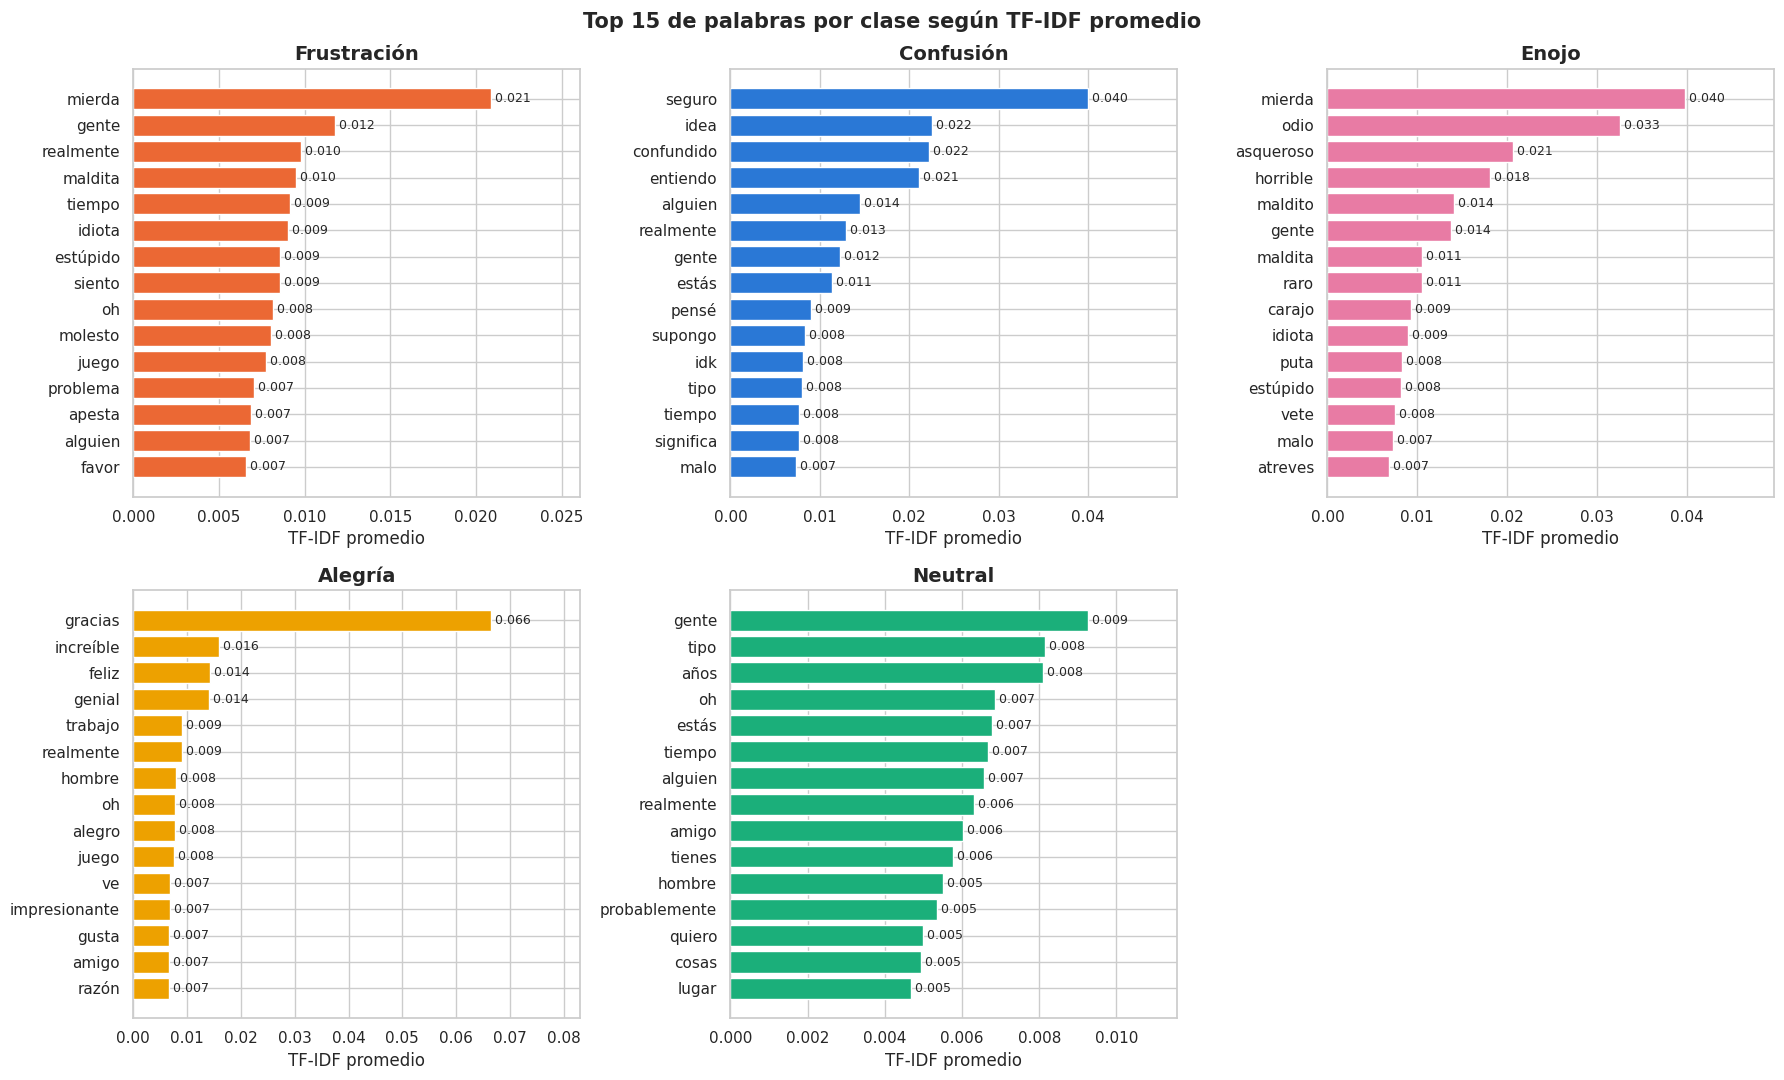

In [136]:
vectorizador_palabras = TfidfVectorizer(min_df=5)
matriz_tfidf = vectorizador_palabras.fit_transform(df_vocabulario["texto_normalizado"])
vocabulario = vectorizador_palabras.get_feature_names_out()

top_tfidf = {}
for clase in ORDEN_CLASES:
    filas_clase = (df_vocabulario["clase"] == clase).to_numpy()
    promedio = np.asarray(matriz_tfidf[filas_clase].mean(axis=0)).ravel()
    top_tfidf[clase] = pd.Series(promedio, index=vocabulario).nlargest(TOP_PALABRAS)

print(f"Tamaño del vocabulario (palabras en al menos 5 textos): {len(vocabulario):,}")
graficar_top_por_clase(top_tfidf, f"Top {TOP_PALABRAS} de palabras por clase según TF-IDF promedio",
                       "TF-IDF promedio", formato="{:.3f}")

#### 2.10.3 Palabras más frecuentes por clase y fuente

Para comparar fuentes de tamaños muy distintos, en lugar de la frecuencia absoluta se muestra el **porcentaje de mensajes de esa clase y fuente que contienen la palabra**. Cada columna corresponde a una fuente y usa su color.

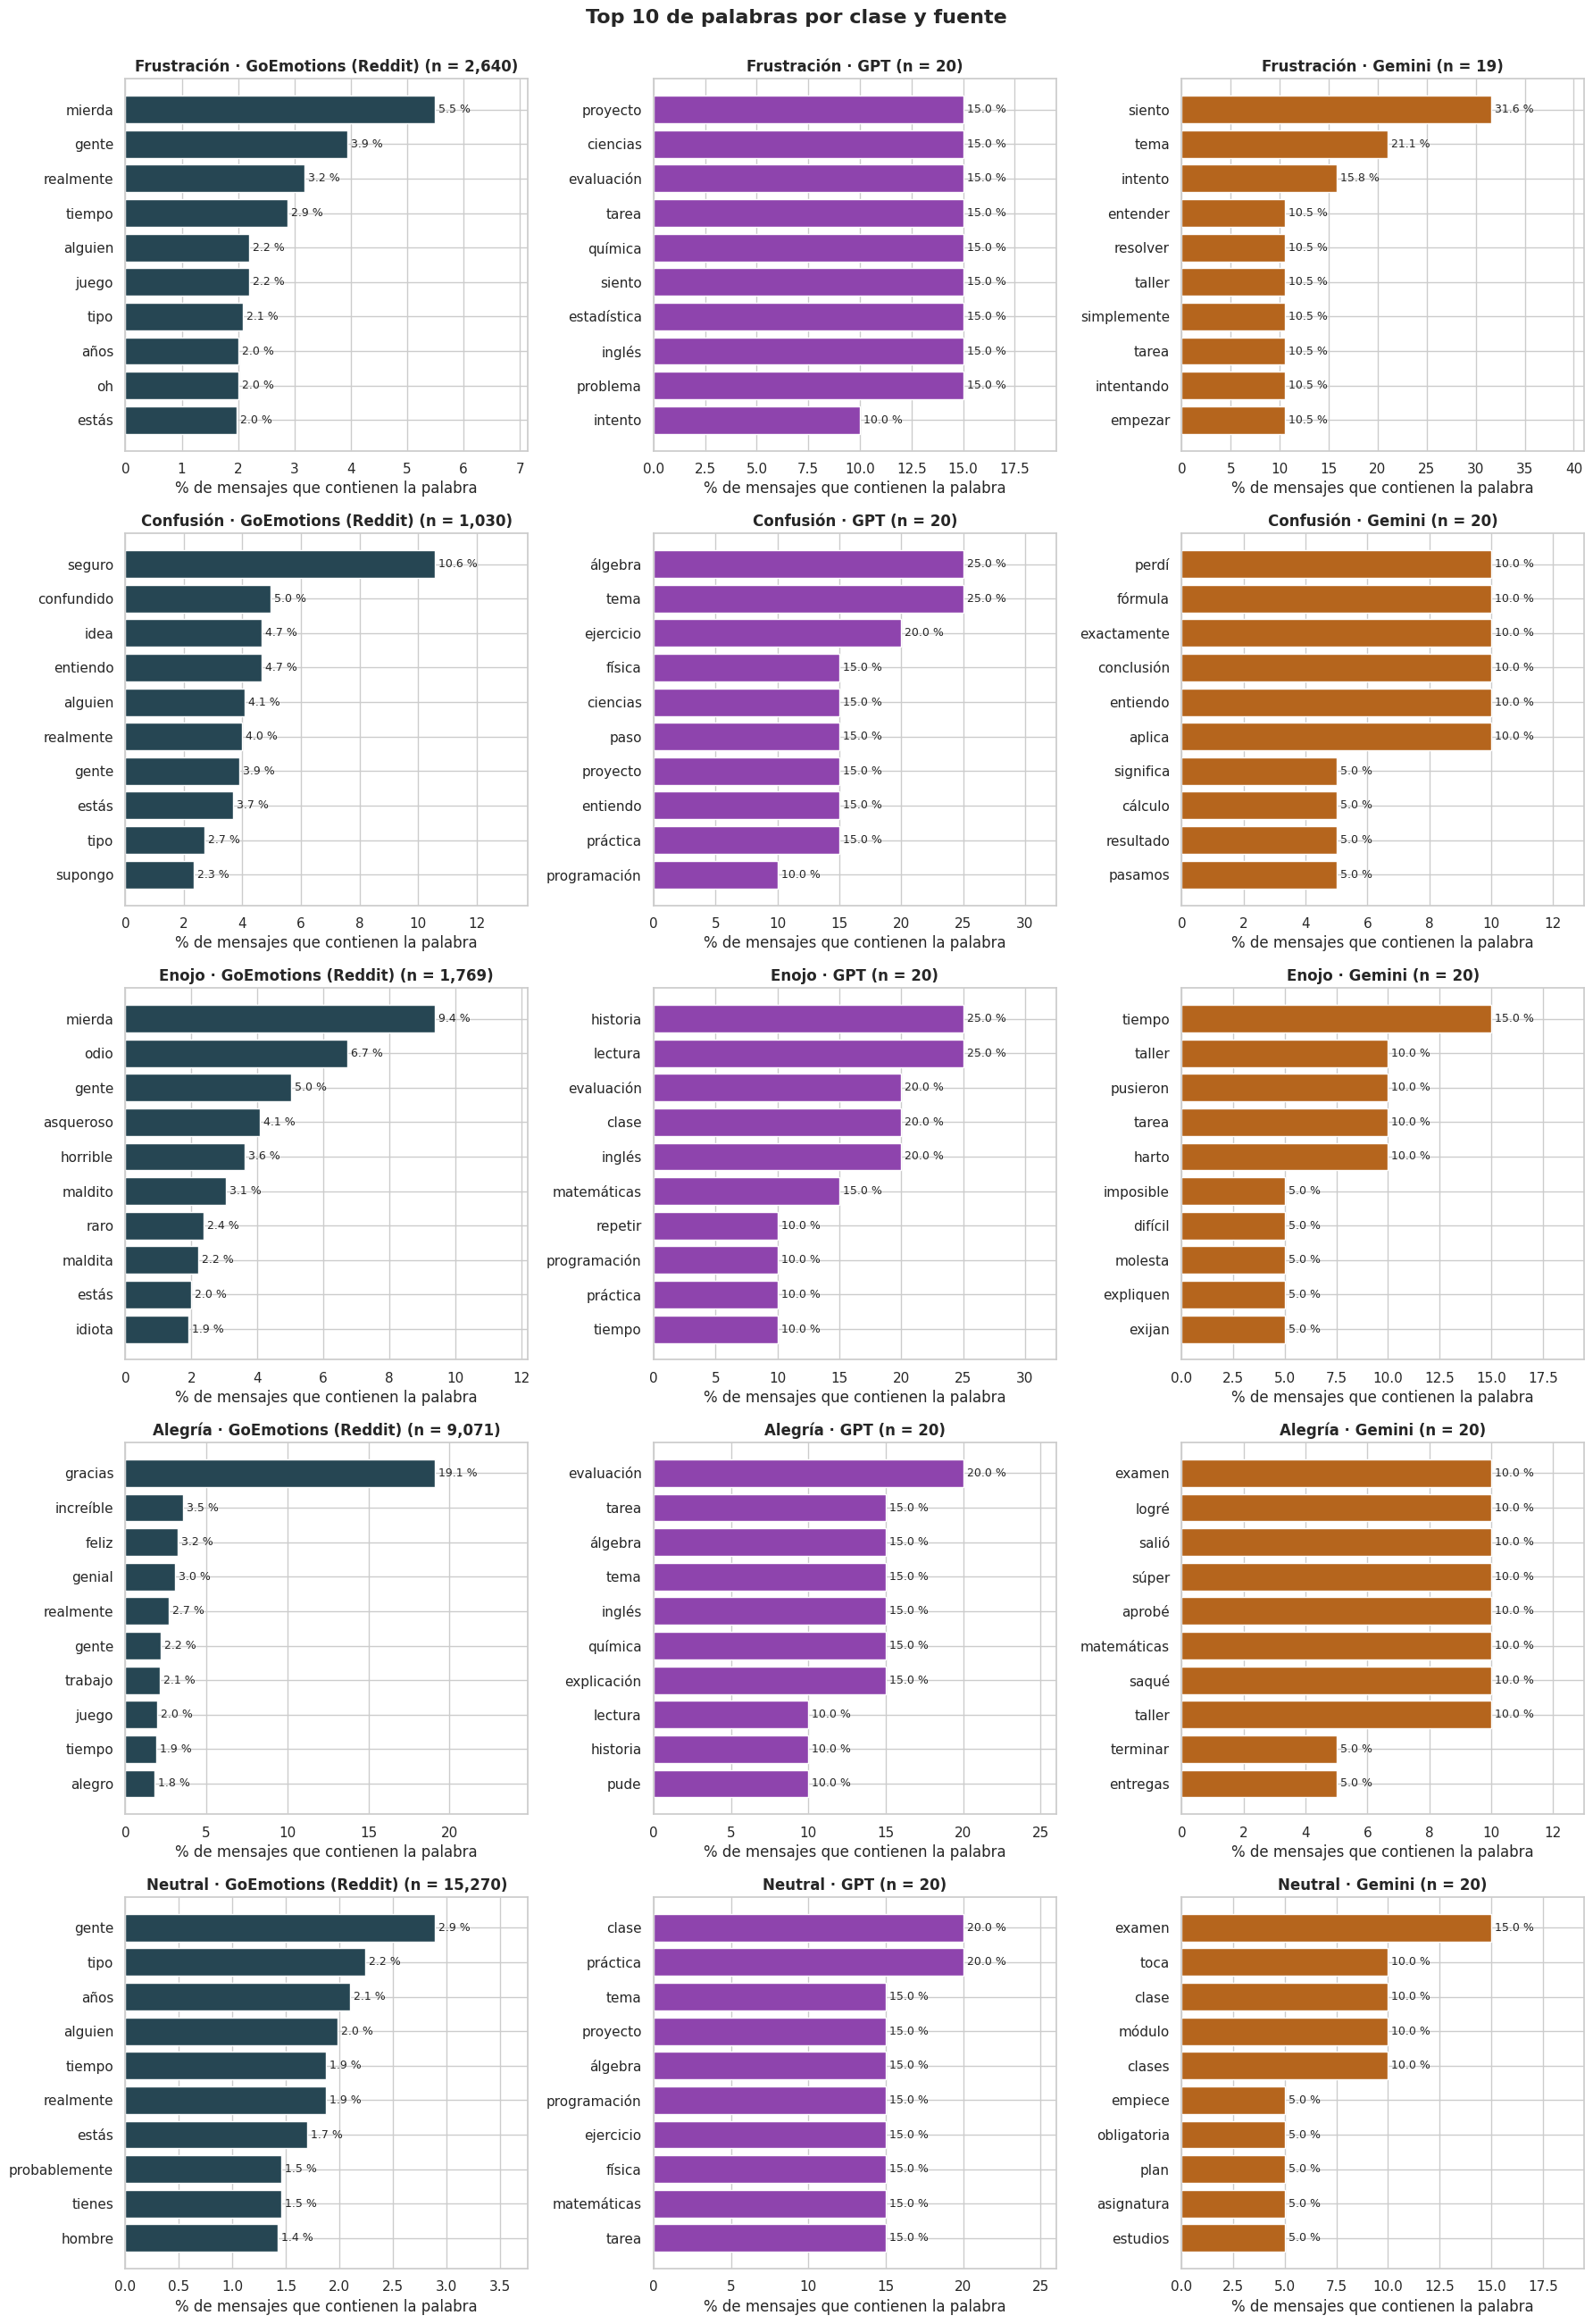

In [137]:
TOP_PALABRAS_FUENTE = 10

fig, ejes = plt.subplots(len(ORDEN_CLASES), len(ORDEN_FUENTES), figsize=(18, 26))
for fila, clase in enumerate(ORDEN_CLASES):
    for columna, fuente in enumerate(ORDEN_FUENTES):
        ax = ejes[fila, columna]
        tokens = df_vocabulario.loc[(df_vocabulario["clase"] == clase) & (df_vocabulario["fuente"] == fuente), "tokens"]
        if tokens.empty:
            ax.axis("off")
            continue
        # Porcentaje de mensajes que contienen cada palabra (cada mensaje cuenta una vez por palabra)
        presencia = pd.Series(Counter(p for lista in tokens for p in set(lista))) / len(tokens) * 100
        datos = presencia.nlargest(TOP_PALABRAS_FUENTE).sort_values()
        ax.barh(datos.index, datos.values, color=PALETA_FUENTES[fuente])
        for i, valor in enumerate(datos.values):
            ax.text(valor, i, f" {valor:.1f} %", va="center", fontsize=9)
        ax.set_xlim(0, datos.max() * 1.3)
        ax.set_title(f"{NOMBRES_CLASES[clase]} · {NOMBRES_FUENTES[fuente]} (n = {len(tokens):,})", fontsize=12)
        ax.set_xlabel("% de mensajes que contienen la palabra")
fig.suptitle(f"Top {TOP_PALABRAS_FUENTE} de palabras por clase y fuente", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Vocabulario exclusivo de cada tipo de fuente.** Para identificar de forma objetiva las palabras que delatan el dominio de Reddit, se listan las palabras más frecuentes de GoEmotions que **no aparecen en ningún mensaje sintético**, y viceversa.

In [138]:
es_goemotions = df_vocabulario["fuente"] == "goemotions"
presencia_goemotions = Counter(p for lista in df_vocabulario.loc[es_goemotions, "tokens"] for p in set(lista))
presencia_sinteticos = Counter(p for lista in df_vocabulario.loc[~es_goemotions, "tokens"] for p in set(lista))
n_goemotions, n_sinteticos = es_goemotions.sum(), (~es_goemotions).sum()

solo_goemotions = pd.Series({p: n for p, n in presencia_goemotions.items() if p not in presencia_sinteticos}).nlargest(25)
solo_sinteticos = pd.Series({p: n for p, n in presencia_sinteticos.items() if p not in presencia_goemotions}).nlargest(25)

display(pd.DataFrame({
    "solo en GoEmotions": solo_goemotions.index,
    "% de mensajes de GoEmotions": (solo_goemotions.values / n_goemotions * 100).round(2),
    "solo en sintéticos": list(solo_sinteticos.index) + [""] * (25 - len(solo_sinteticos)),
    "% de mensajes sintéticos": list((solo_sinteticos.values / n_sinteticos * 100).round(2)) + [np.nan] * (25 - len(solo_sinteticos)),
}))

,solo en GoEmotions,% de mensajes de GoEmotions,solo en sintéticos,% de mensajes sintéticos
0,gracias,5.94,aprobé,1.51
1,gente,2.93,módulo,1.51
2,realmente,2.29,avanzo,1.01
3,tipo,2.07,sencilla,1.01
4,años,1.80,corresponde,1.01
5,mierda,1.77,cansé,1.01
6,estás,1.61,exijan,1.01
7,oh,1.59,superé,1.01
8,hombre,1.54,apuntes,1.01
9,tienes,1.51,cuestionario,1.01


#### 2.10.4 Muletillas de inicio

Los modelos generadores suelen empezar muchos mensajes con la misma frase. Si, por ejemplo, la mayoría de los mensajes de confusión de GPT empiezan con "No entiendo", el clasificador puede aprender que "No entiendo" significa confusión, y fallar con mensajes reales que expresen confusión de otra forma. Para detectarlo se cuentan las **primeras palabras de cada mensaje** (en minúsculas y sin puntuación, pero **con** stopwords, porque "no", "me" o "por" forman parte de las muletillas).

Primero se muestran, para cada clase, las 10 combinaciones más frecuentes de las **dos primeras palabras** en cada fuente, con el porcentaje de mensajes de esa clase y fuente que empiezan así.

In [139]:
def inicio_mensaje(texto, n_palabras):
    palabras = re.sub(r"[^\w\s]", " ", re.sub(PATRON_MARCADOR, " ", texto).lower()).split()
    return " ".join(palabras[:n_palabras]) if len(palabras) >= n_palabras else None


def tabla_inicios(clase, n_palabras, top=10):
    columnas = {}
    for fuente in ORDEN_FUENTES:
        textos = df_limpio.loc[(df_limpio["clase"] == clase) & (df_limpio["fuente"] == fuente), "texto"]
        frecuentes = textos.apply(inicio_mensaje, n_palabras=n_palabras).value_counts().head(top)
        celdas_fuente = [f"{inicio} ({n / len(textos):.1%})" for inicio, n in frecuentes.items()]
        columnas[NOMBRES_FUENTES[fuente]] = celdas_fuente + [""] * (top - len(celdas_fuente))
    return pd.DataFrame(columnas, index=pd.RangeIndex(1, top + 1, name="puesto"))


for clase in ORDEN_CLASES:
    print(f"\n=== {NOMBRES_CLASES[clase]}: inicios de 2 palabras más frecuentes ===")
    display(tabla_inicios(clase, n_palabras=2))


=== Frustración: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,maldita sea (1.2%),siento que (10.0%),siento que (15.8%)
2,eso es (0.9%),no entiendo (5.0%),intento seguir (5.3%)
3,creo que (0.8%),por más (5.0%),me bloqueo (5.3%)
4,por qué (0.8%),llevo un (5.0%),definitivamente cálculo (5.3%)
5,no es (0.6%),me esfuerzo (5.0%),esto es (5.3%)
6,es una (0.6%),estoy bloqueado (5.0%),mi mente (5.3%)
7,así que (0.5%),cada vez (5.0%),llevo horas (5.3%)
8,no me (0.5%),me cuesta (5.0%),no soy (5.3%)
9,esto es (0.4%),ya lo (5.0%),soy pésimo (5.3%)



=== Confusión: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,por qué (4.4%),me perdí (5.0%),por qué (10.0%)
2,no estoy (4.1%),podría explicar (5.0%),qué significa (5.0%)
3,no sé (3.0%),entiendo cada (5.0%),cómo pasamos (5.0%)
4,tal vez (1.8%),no me (5.0%),este tema (5.0%)
5,así que (1.4%),cuál es (5.0%),me suena (5.0%)
6,no entiendo (1.4%),creo que (5.0%),entiendo las (5.0%)
7,no es (1.3%),la explicación (5.0%),no me (5.0%)
8,creo que (1.2%),podría dar (5.0%),siento que (5.0%)
9,no tengo (1.1%),no estoy (5.0%),me confundí (5.0%)



=== Enojo: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,a la (1.6%),estoy harto (5.0%),me molesta (5.0%)
2,eso es (1.5%),qué pérdida (5.0%),es demasiado (5.0%)
3,esto es (1.2%),ya me (5.0%),qué coraje (5.0%)
4,maldita sea (1.0%),no pienso (5.0%),odio matemáticas (5.0%)
5,es un (0.8%),es absurdo (5.0%),el examen (5.0%)
6,por qué (0.8%),me molesta (5.0%),este profesor (5.0%)
7,cómo te (0.8%),otra vez (5.0%),es injusto (5.0%)
8,no me (0.6%),no soporto (5.0%),es ridículo (5.0%)
9,qué carajo (0.6%),esta actividad (5.0%),ya me (5.0%)



=== Alegría: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,gracias por (3.3%),por fin (10.0%),por fin (10.0%)
2,eso es (1.6%),me fue (5.0%),valió totalmente (5.0%)
3,esto es (1.1%),estoy feliz (5.0%),qué felicidad (5.0%)
4,creo que (1.0%),después de (5.0%),saqué diez (5.0%)
5,estoy de (0.9%),qué alegría (5.0%),salió excelente (5.0%)
6,me alegro (0.9%),saqué la (5.0%),qué satisfacción (5.0%)
7,muchas gracias (0.7%),no puedo (5.0%),me felicitaron (5.0%)
8,es un (0.6%),hoy sí (5.0%),hoy todo (5.0%)
9,de acuerdo (0.6%),me salió (5.0%),ya la (5.0%)



=== Neutral: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,creo que (1.1%),hoy tenemos (5.0%),es una (5.0%)
2,eso es (0.7%),la próxima (5.0%),estoy esperando (5.0%)
3,tal vez (0.5%),el profesor (5.0%),esta materia (5.0%)
4,no hay (0.5%),tengo que (5.0%),no me (5.0%)
5,así que (0.5%),en el (5.0%),el profesor (5.0%)
6,parece que (0.5%),la evaluación (5.0%),estoy tomando (5.0%)
7,no es (0.5%),el material (5.0%),es un (5.0%)
8,esto es (0.5%),durante esta (5.0%),hice el (5.0%)
9,por qué (0.4%),anoté los (5.0%),solo busco (5.0%)


Para resumir todas las clases en una sola vista, el siguiente gráfico muestra, para inicios de 2 y de 3 palabras, el **porcentaje de mensajes que empiezan con alguno de los 10 inicios más frecuentes** de su clase y fuente. Un valor alto indica que la fuente usa pocas fórmulas de inicio. Como un grupo con pocos mensajes tiene, por fuerza, menos inicios distintos, este porcentaje favorece a las fuentes pequeñas; la comparación con muestras del mismo tamaño se hace en 2.11.

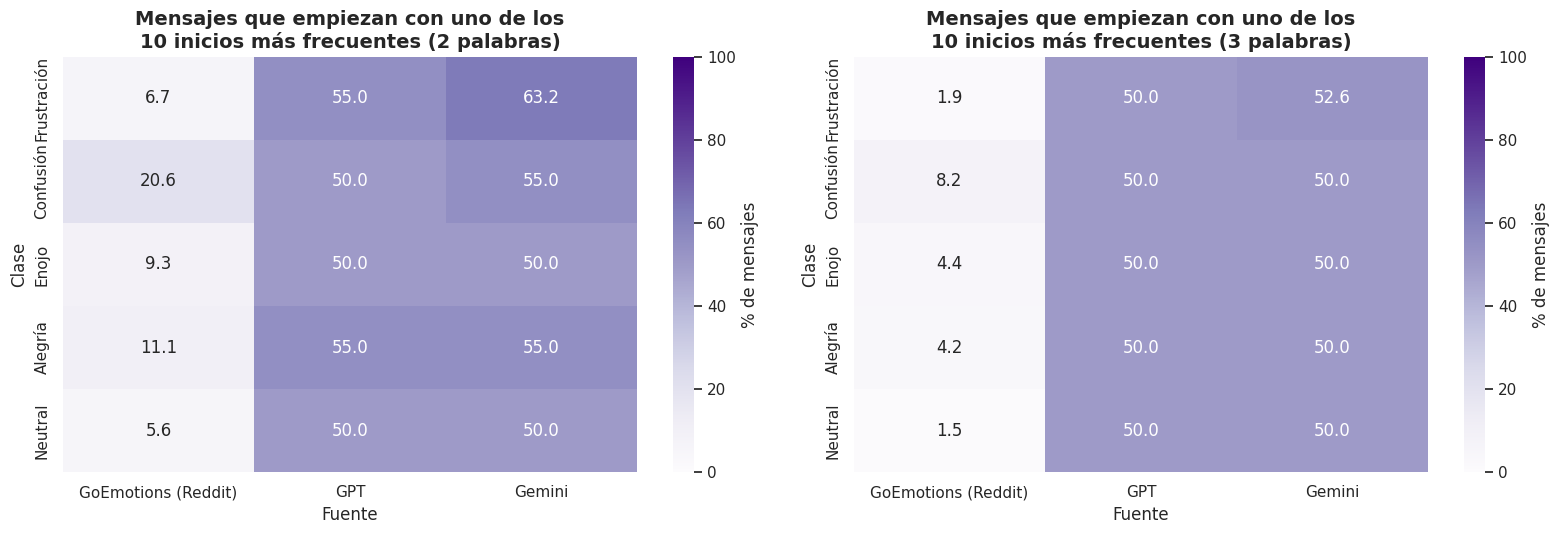

In [140]:
def cobertura_top_inicios(n_palabras, top=10):
    cobertura = pd.DataFrame(index=ORDEN_CLASES, columns=ORDEN_FUENTES, dtype=float)
    for clase in ORDEN_CLASES:
        for fuente in ORDEN_FUENTES:
            textos = df_limpio.loc[(df_limpio["clase"] == clase) & (df_limpio["fuente"] == fuente), "texto"]
            inicios = textos.apply(inicio_mensaje, n_palabras=n_palabras)
            cobertura.loc[clase, fuente] = inicios.value_counts().head(top).sum() / len(textos) * 100
    return cobertura


fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, n_palabras in zip(ejes, [2, 3]):
    cobertura = cobertura_top_inicios(n_palabras)
    sns.heatmap(cobertura, annot=True, fmt=".1f", cmap="Purples", vmin=0, vmax=100,
                xticklabels=[NOMBRES_FUENTES[f] for f in ORDEN_FUENTES],
                yticklabels=[NOMBRES_CLASES[c] for c in ORDEN_CLASES],
                cbar_kws={"label": "% de mensajes"}, ax=ax)
    ax.set_title(f"Mensajes que empiezan con uno de los\n10 inicios más frecuentes ({n_palabras} palabras)")
    ax.set_xlabel("Fuente")
    ax.set_ylabel("Clase")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar:

- **Coherencia del vocabulario.** Comentar si el vocabulario de cada clase tiene sentido: por ejemplo, si "gracias" aparece en alegría, si en confusión aparecen expresiones como "entiendo", "qué" o "seguro", y si en enojo aparecen insultos o groserías.
- **Dominio de Reddit.** Señalar las palabras que delatan un dominio no educativo, según la tabla de vocabulario exclusivo: nombres de equipos, términos de fútbol, política o videojuegos ([COMPLETAR: palabras concretas observadas]). En los sintéticos, en cambio, dominan palabras como [COMPLETAR: "examen", "tarea", "profesor"…]. Esto confirma que GoEmotions no representa el dominio del tutor y justifica combinar las fuentes.
- **Efecto de 2.7.3.** Como cada plantilla aporta ahora un solo mensaje, los porcentajes de esta tabla ya no reflejan las 10 variantes de cada frase de GPT (que antes daban exactamente un 5,0 % a cada inicio), sino cuántas plantillas *distintas* comparten un mismo inicio. Con unos 20 mensajes por clase y fuente, cada mensaje vale un 5 % aproximadamente, así que las diferencias pequeñas no son significativas.
- **Muletillas de los generadores.** Indicar las muletillas más fuertes, con su porcentaje (por ejemplo, "el [COMPLETAR] % de los mensajes de confusión de GPT empiezan con '[COMPLETAR]'"), y si GPT y Gemini comparten muletillas (por ejemplo, "siento que"). Son un **riesgo**: el modelo podría aprender esas frases como atajo para predecir la clase en lugar de la emoción, y luego fallar con mensajes reales escritos de otra forma. El experimento de entrenar con un generador y evaluar con el otro (ver conclusiones) permitirá medir este efecto.]

**Cifras clave de 2.10**

- Tamaño del vocabulario usado en el análisis TF-IDF: [COMPLETAR] palabras.
- Muletilla más frecuente por fuente: GPT = "[COMPLETAR]" ([COMPLETAR] % de su clase), Gemini = "[COMPLETAR]" ([COMPLETAR] %).

### 2.11 Diversidad léxica por fuente

Se mide de forma objetiva qué tan variados son los datos sintéticos frente a los reales con tres métricas:

- **Type-token ratio (TTR):** palabras distintas / palabras totales. Cuanto más alto, más variado es el vocabulario.
- **Distinct-2:** bigramas (pares de palabras consecutivas) distintos / bigramas totales. Mide la variedad de las combinaciones de palabras, no solo del vocabulario; es la métrica habitual para evaluar la diversidad de textos generados.
- **Proporción de inicios repetidos:** proporción de mensajes cuyas primeras 3 palabras coinciden con las de otro mensaje de la muestra. Cuantifica las muletillas de 2.10.4.

**Control del tamaño.** Estas métricas dependen del tamaño de la muestra: cuantos más textos (o palabras) se cuentan, más se repiten las palabras y menor es el TTR. Para comparar de forma justa:

1. De cada fuente se toma una **muestra aleatoria del mismo número de mensajes**, igual al tamaño de la fuente más pequeña. Tras eliminar las variantes de plantilla (2.7.3), GPT y Gemini quedan con unos 100 mensajes cada una, así que ese es el tamaño de la muestra.
2. Como los mensajes de cada fuente tienen longitudes distintas, el TTR y el distinct-2 se calculan sobre el **mismo número de palabras y de bigramas** en las tres fuentes (el mínimo entre ellas).
3. El muestreo se repite 10 veces (con semillas derivadas de la semilla global) y se informa la media y la desviación estándar. En las fuentes cuyo tamaño coincide, o casi, con el de la muestra (GPT y Gemini), la muestra es prácticamente la fuente completa, así que su desviación es cero o casi cero: la variabilidad entre repeticiones solo es informativa para GoEmotions.

Las palabras se cuentan sobre el texto natural en minúsculas, sin quitar stopwords, porque la diversidad incluye también cómo se combinan las palabras funcionales.

In [141]:
METRICAS_DIVERSIDAD = ["type_token_ratio", "distinct_2", "prop_inicios_repetidos"]
NOMBRES_METRICAS = {
    "type_token_ratio": "Type-token ratio",
    "distinct_2": "Distinct-2",
    "prop_inicios_repetidos": "Prop. de inicios repetidos",
}


def tokens_naturales(texto):
    return re.findall(r"\w+", re.sub(PATRON_MARCADOR, " ", texto).lower())


def calcular_diversidad(listas_tokens, n_palabras, n_bigramas):
    palabras = [p for tokens in listas_tokens for p in tokens][:n_palabras]
    bigramas = [b for tokens in listas_tokens for b in zip(tokens, tokens[1:])][:n_bigramas]
    inicios = pd.Series([" ".join(tokens[:3]) for tokens in listas_tokens if len(tokens) >= 3])
    return {
        "type_token_ratio": len(set(palabras)) / len(palabras),
        "distinct_2": len(set(bigramas)) / len(bigramas),
        "prop_inicios_repetidos": inicios.duplicated(keep=False).mean(),
    }


def comparar_diversidad(grupos, n_mensajes, semilla):
    """grupos: dict nombre -> Serie de textos. Devuelve las métricas de cada grupo con el tamaño controlado."""
    listas = {
        nombre: [tokens_naturales(t) for t in textos.sample(n_mensajes, random_state=semilla)]
        for nombre, textos in grupos.items()
    }
    n_palabras = min(sum(len(t) for t in lista) for lista in listas.values())
    n_bigramas = min(sum(max(len(t) - 1, 0) for t in lista) for lista in listas.values())
    return {nombre: calcular_diversidad(lista, n_palabras, n_bigramas) for nombre, lista in listas.items()}


N_REPETICIONES = 10
semillas = np.random.default_rng(SEMILLA).integers(0, 1_000_000, N_REPETICIONES)
n_muestra = int(contar_por_fuente(df_limpio).min())
textos_diversidad = {fuente: df_limpio.loc[df_limpio["fuente"] == fuente, "texto"] for fuente in ORDEN_FUENTES}

resultados = []
for repeticion, semilla in enumerate(semillas):
    for fuente, metricas in comparar_diversidad(textos_diversidad, n_muestra, int(semilla)).items():
        resultados.append({"repetición": repeticion, "fuente": fuente, **metricas})
df_diversidad = pd.DataFrame(resultados)

resumen_diversidad = (
    df_diversidad.groupby("fuente")[METRICAS_DIVERSIDAD].agg(["mean", "std"])
    .reindex(ORDEN_FUENTES).round(3)
    .rename(columns={"mean": "media", "std": "desv_est"}, level=1)
    .rename(columns=NOMBRES_METRICAS, level=0)
)
print(f"Mensajes por muestra: {n_muestra:,} (tamaño de la fuente más pequeña), {N_REPETICIONES} repeticiones")
display(resumen_diversidad)

if n_muestra < 100:
    print(f"Advertencia: la muestra tiene solo {n_muestra} mensajes. Las métricas de GoEmotions se estiman "
          f"con poca precisión; revisar su desviación estándar entre repeticiones en la tabla.")

Mensajes por muestra: 99 (tamaño de la fuente más pequeña), 10 repeticiones


Type-token ratio          Distinct-2           \
                      media desv_est      media desv_est   
fuente                                                     
goemotions            0.514    0.012      0.937    0.013   
gpt                   0.325    0.004      0.669    0.004   
gemini                0.427    0.000      0.885    0.000   

           Prop. de inicios repetidos           
                                media desv_est  
fuente                                          
goemotions                        0.0      0.0  
gpt                               0.0      0.0  
gemini                            0.0      0.0

Advertencia: la muestra tiene solo 99 mensajes. Las métricas de GoEmotions se estiman con poca precisión; revisar su desviación estándar entre repeticiones en la tabla.


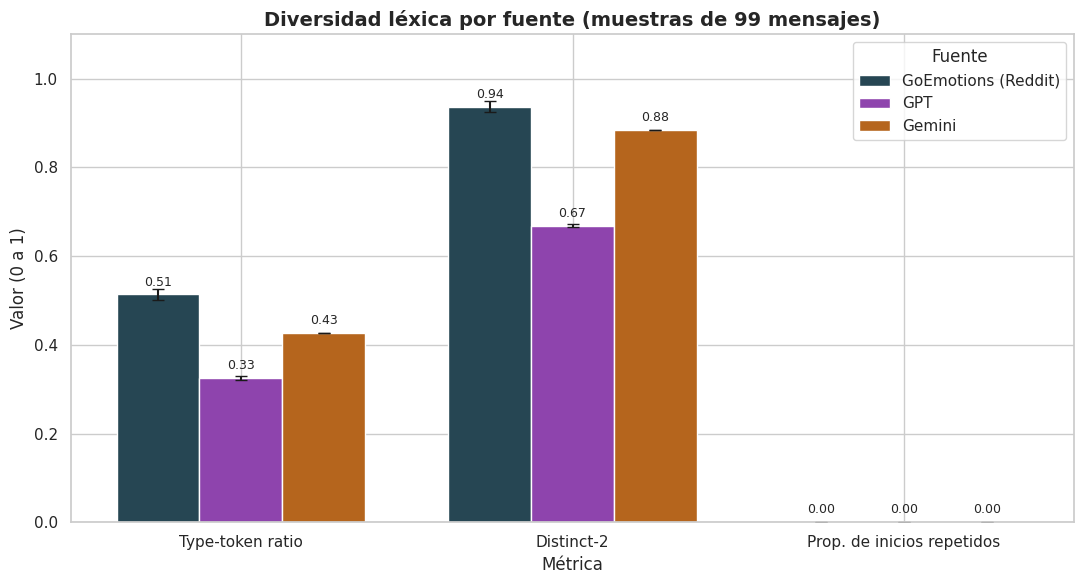

In [142]:
medias = df_diversidad.groupby("fuente")[METRICAS_DIVERSIDAD].mean().reindex(ORDEN_FUENTES)
desviaciones = df_diversidad.groupby("fuente")[METRICAS_DIVERSIDAD].std().reindex(ORDEN_FUENTES)

fig, ax = plt.subplots(figsize=(11, 6))
ancho = 0.25
posiciones = np.arange(len(METRICAS_DIVERSIDAD))
for k, fuente in enumerate(ORDEN_FUENTES):
    barras = ax.bar(posiciones + (k - 1) * ancho, medias.loc[fuente], width=ancho, yerr=desviaciones.loc[fuente],
                    capsize=4, color=PALETA_FUENTES[fuente], label=NOMBRES_FUENTES[fuente])
    for barra, valor in zip(barras, medias.loc[fuente]):
        ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.02, f"{valor:.2f}", ha="center", fontsize=9)
ax.set_xticks(posiciones)
ax.set_xticklabels([NOMBRES_METRICAS[m] for m in METRICAS_DIVERSIDAD])
ax.set_ylim(0, 1.1)
ax.set_title(f"Diversidad léxica por fuente (muestras de {n_muestra:,} mensajes)")
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor (0 a 1)")
ax.legend(title="Fuente")
plt.tight_layout()
plt.show()

**Diversidad por clase y fuente.** Se repite el cálculo dentro de cada clase, con muestras del tamaño del grupo clase × fuente más pequeño, para ver si la falta de diversidad se concentra en alguna clase.

**Advertencia.** Después de eliminar las variantes de plantilla (2.7.3), cada grupo clase × fuente de los sintéticos tiene unos 20 mensajes, de modo que el tamaño de muestra de este análisis (`n_muestra_clase`, que se imprime abajo) queda en torno a 20 o por debajo. Con tan pocos mensajes, cada uno cambia la proporción de inicios repetidos en unos 5 puntos porcentuales, así que **las cifras por clase de este heatmap son solo orientativas**; las conclusiones sobre diversidad se basan en la comparación por fuente de la celda anterior.

Mensajes por muestra en cada grupo clase × fuente: 19
Advertencia: menos de 20 mensajes por grupo; las cifras por clase son solo orientativas.


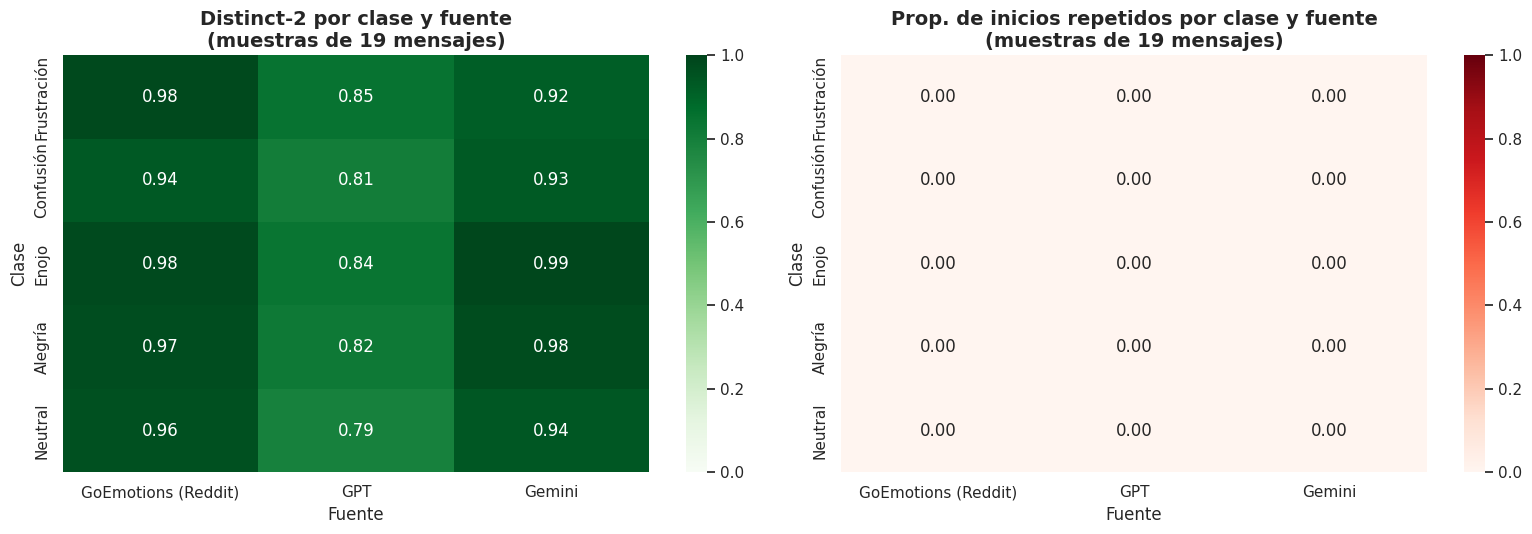

In [143]:
n_muestra_clase = int(df_limpio.groupby(["clase", "fuente"]).size().min())
print(f"Mensajes por muestra en cada grupo clase × fuente: {n_muestra_clase}")
if n_muestra_clase < 20:
    print("Advertencia: menos de 20 mensajes por grupo; las cifras por clase son solo orientativas.")
filas = []
for clase in ORDEN_CLASES:
    grupos = {
        fuente: df_limpio.loc[(df_limpio["clase"] == clase) & (df_limpio["fuente"] == fuente), "texto"]
        for fuente in ORDEN_FUENTES
    }
    for fuente, metricas in comparar_diversidad(grupos, n_muestra_clase, SEMILLA).items():
        filas.append({"clase": clase, "fuente": fuente, **metricas})
df_diversidad_clase = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, metrica, mapa in zip(ejes, ["distinct_2", "prop_inicios_repetidos"], ["Greens", "Reds"]):
    tabla = df_diversidad_clase.pivot(index="clase", columns="fuente", values=metrica).reindex(
        index=ORDEN_CLASES, columns=ORDEN_FUENTES)
    sns.heatmap(tabla, annot=True, fmt=".2f", cmap=mapa, vmin=0, vmax=1,
                xticklabels=[NOMBRES_FUENTES[f] for f in ORDEN_FUENTES],
                yticklabels=[NOMBRES_CLASES[c] for c in ORDEN_CLASES], ax=ax)
    ax.set_title(f"{NOMBRES_METRICAS[metrica]} por clase y fuente\n(muestras de {n_muestra_clase} mensajes)")
    ax.set_xlabel("Fuente")
    ax.set_ylabel("Clase")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: comparar las tres fuentes con las cifras de la tabla. Indicar si los datos sintéticos tienen un TTR y un distinct-2 menores que los de Reddit ([COMPLETAR] y [COMPLETAR] frente a [COMPLETAR]) y una proporción de inicios repetidos mayor ([COMPLETAR] frente a [COMPLETAR]), lo que confirmaría que son menos variados. Comparar GPT y Gemini entre sí: cuál de los dos generadores es más repetitivo y si la diferencia es mayor que la desviación estándar entre repeticiones. Señalar en qué clases se concentra la falta de diversidad. Tras 2.7.3, comprobar si la proporción de inicios repetidos de GPT y Gemini bajó respecto de los valores anteriores a ese paso (0,998 y 0,875, frente a 0,027 en GoEmotions) y comentar la estabilidad de las métricas con la nueva muestra de unos 100 mensajes (desviación estándar entre repeticiones).]

**Cifras clave de 2.11**

- Tamaño de muestra por fuente: [COMPLETAR] mensajes.
- Distinct-2: GoEmotions = [COMPLETAR], GPT = [COMPLETAR], Gemini = [COMPLETAR].
- Proporción de inicios repetidos: GoEmotions = [COMPLETAR], GPT = [COMPLETAR], Gemini = [COMPLETAR].

### 2.12 Revisión cualitativa: ejemplos y calidad

Las métricas anteriores no sustituyen la lectura directa de los datos. En esta subsección se revisan ejemplos concretos de cada fuente para documentar sus limitaciones.

#### 2.12.1 Ejemplos aleatorios por clase y fuente

Se muestran 3 ejemplos aleatorios por clase y por fuente, con el texto completo.

In [144]:
for clase in ORDEN_CLASES:
    print(f"\n=== {NOMBRES_CLASES[clase]} ===")
    ejemplos = (
        df_limpio[df_limpio["clase"] == clase]
        .groupby("fuente", group_keys=False).sample(n=3, random_state=SEMILLA)
    )
    ejemplos["fuente"] = pd.Categorical(ejemplos["fuente"], categories=ORDEN_FUENTES, ordered=True)
    display(ejemplos.sort_values("fuente")[["fuente", "texto", "emocion_original"]].reset_index(drop=True))


=== Frustración ===


,fuente,texto,emocion_original
0,goemotions,Hazlo con éxito y el país del carbón todavía dirá que es una idea estúpida.,annoyance
1,goemotions,Es 2019 amigo relajarse con los roles de género Editar: es 2019 Estoy cansado lo siento,disappointment
2,goemotions,"Sí, necesita sentarse, eso es todo lo que tengo que decir.",annoyance
3,gpt,Me cuesta muchísimo seguir el ritmo de la lectura de historia.,frustracion
4,gpt,"Cada vez que intento estudiar el tema de álgebra, termino sintiéndome incapaz.",frustracion
5,gpt,Llevo un buen rato con la tarea de química y sigo sin avanzar.,frustracion
6,gemini,Intento seguir el ritmo de la clase pero me siento incapaz.,frustracion
7,gemini,Mi mente se quedó completamente en blanco durante la tarea.,frustracion
8,gemini,"Me rindo con este ejercicio, simplemente no me da la cabeza.",frustracion



=== Confusión ===


,fuente,texto,emocion_original
0,goemotions,Pagar a las parejas para tener hijos. No estoy seguro si los incentivos se aplican a las madres solteras.,confusion
1,goemotions,No sé por qué se molestan en ello.,confusion
2,goemotions,¡La izquierda se ha hecho daño en su confusión!,confusion
3,gpt,Quisiera confirmar si interpreté correctamente el ejercicio de la clase de matemáticas.,confusion
4,gpt,No logro distinguir estos dos conceptos cuando vemos el proyecto de ciencias.,confusion
5,gpt,¿Ese resultado se obtiene del paso anterior o de otra regla de la lectura de historia?,confusion
6,gemini,¿Cómo pasamos de ese resultado a la conclusión final?,confusion
7,gemini,"Me perdí en esa última parte, ¿podría repetirlo por favor?",confusion
8,gemini,"Entendí el principio, pero en la mitad de la explicación me perdí.",confusion



=== Enojo ===


,fuente,texto,emocion_original
0,goemotions,"Este cuadro es un excelente ejemplo de que [NOMBRE] son idiotas intolerantes que siempre demonizarán la riqueza, la fama y el entretenimiento.",disgust
1,goemotions,Ese maldito FDR al que Estados Unidos amaba tanto que tuvo que escribir una enmienda a la Constitución para evitar que nadie más fuera elegido que muchas veces,anger
2,goemotions,"Me disculpo por parecer grosero, el comentario final fue innecesario y innecesariamente grosero",anger
3,gpt,¡Esta actividad de la clase de matemáticas está mal planteada!,enojo
4,gpt,¡Estoy furioso por la cantidad de tareas de la práctica de programación!,enojo
5,gpt,¡No soporto que evalúen el proyecto de ciencias sin haberlo explicado correctamente!,enojo
6,gemini,Me molesta demasiado que no expliquen bien y luego exijan tanto.,enojo
7,gemini,"¡No entiendo nada, esto no sirve para absolutamente nada!",enojo
8,gemini,¡Estoy harto de esta plataforma que siempre falla al subir el taller!,enojo



=== Alegría ===


,fuente,texto,emocion_original
0,goemotions,Salud. Nunca he oído hablar de ninguno de ellos. Los niños te harán eso...,excitement
1,goemotions,"¡Mi [NOMBRE], me olvidé por completo de eso! Realmente espero que se haya casado [NOMBRE]... ¡Serían una pareja de casados increíble!",admiration
2,goemotions,"¡No sabía nada de esto, gracias! Sólo me apunté.",gratitude
3,gpt,¡Recibí una felicitación por mi trabajo sobre el ejercicio de física!,alegria
4,gpt,¡Estoy feliz porque aprobé la clase de matemáticas!,alegria
5,gpt,¡Qué alegría ver que todo mi esfuerzo con el tema de álgebra dio resultado!,alegria
6,gemini,¡Qué felicidad terminar todas mis entregas de la semana!,alegria
7,gemini,"¡Pasé física, todavía no me lo creo!",alegria
8,gemini,¡Logré resolver el problema más difícil de la teoría yo solo!,alegria



=== Neutral ===


,fuente,texto,emocion_original
0,goemotions,"Huh, supuse que era más como un tipo molinillo.....",neutral
1,goemotions,No citaron una fuente. Además de los errores de ortografía. Es por eso que no confías en las infografías para las estadísticas.,neutral
2,goemotions,"Creo que los verdaderos incels son los que estaban dispuestos a comprar sus pantalones de yoga, lo más probable es que sus seguidores.",neutral
3,gpt,El profesor dejó una tarea relacionada con la explicación de hoy.,neutral
4,gpt,Hoy corresponde completar la práctica del tema de álgebra.,neutral
5,gpt,En la sesión anterior vimos una introducción a la práctica de programación.,neutral
6,gemini,Es una asignatura obligatoria del plan de estudios.,neutral
7,gemini,Estoy revisando el temario de cálculo para ver qué sigue.,neutral
8,gemini,Subí el archivo de este problema a la plataforma hace un rato.,neutral


#### 2.12.2 GoEmotions: calidad de la traducción automática

La traducción automática falla sobre todo con la jerga, las groserías y las expresiones idiomáticas. Por ejemplo, en la exploración inicial apareció "if he does off himself" ("si se suicida") traducido como "si lo hace fuera de sí mismo", que cambia por completo el sentido. Ese ejemplo tiene la etiqueta `neutral`, así que se busca en `df_crudo`:

In [145]:
df_crudo[df_crudo["text"].str.contains("does off himself", case=False, regex=False)][["text", "text_es", "labels"]]

,text,text_es,labels
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead","Ahora, si lo hace fuera de sí mismo, todo el mundo pensará que está teniendo una risa jodiendo con la gente en lugar de realmente muerto",[27]


Para encontrar más casos de forma sistemática se usan dos indicadores sobre los textos de GoEmotions que quedaron tras la limpieza, comparando la traducción (`texto`) con el original en inglés (`texto_ingles`):

- **Proporción de palabras que quedaron en inglés**: palabras de la traducción que aparecen idénticas en el texto original (sin contar marcadores, números ni palabras de menos de 4 letras, que pueden coincidir por casualidad en ambos idiomas). Una proporción alta indica que el traductor no supo traducir el texto, algo típico con jerga.
- **Proporción de letras en mayúsculas**: los textos escritos en mayúsculas (gritos) suelen traducirse peor.

In [146]:
def proporcion_sin_traducir(fila):
    palabras_es = re.findall(r"[^\W\d_]{4,}", re.sub(PATRON_MARCADOR, " ", fila["texto"]).lower())
    palabras_en = set(re.findall(r"[^\W\d_]{4,}", fila["texto_ingles"].lower()))
    if not palabras_es:
        return 0.0
    return sum(palabra in palabras_en for palabra in palabras_es) / len(palabras_es)


def proporcion_mayusculas(texto):
    letras = [c for c in re.sub(PATRON_MARCADOR, " ", texto) if c.isalpha()]
    return sum(c.isupper() for c in letras) / len(letras) if letras else 0.0


df_traduccion = df_limpio.loc[df_limpio["fuente"] == "goemotions",
                              ["texto_ingles", "texto", "clase", "emocion_original"]].copy()
df_traduccion["prop_sin_traducir"] = df_traduccion.apply(proporcion_sin_traducir, axis=1)
df_traduccion["prop_mayusculas"] = df_traduccion["texto"].apply(proporcion_mayusculas)

print(f"Textos con al menos un 30 % de palabras sin traducir: {(df_traduccion['prop_sin_traducir'] >= 0.3).sum():,} "
      f"de {len(df_traduccion):,}")
print("\nTextos con mayor proporción de palabras sin traducir:")
display(df_traduccion.sort_values("prop_sin_traducir", ascending=False)
        .head(8)[["texto_ingles", "texto", "emocion_original", "prop_sin_traducir"]].round(2))

mayusculas = df_traduccion["prop_mayusculas"] > 0.8
print("Textos escritos mayoritariamente en mayúsculas:")
display(df_traduccion[mayusculas].sample(min(8, mayusculas.sum()), random_state=SEMILLA)
        [["texto_ingles", "texto", "emocion_original"]])

Textos con al menos un 30 % de palabras sin traducir: 1,686 de 29,780

Textos con mayor proporción de palabras sin traducir:


,texto_ingles,texto,emocion_original,prop_sin_traducir
25529,Orangeman = cuck,Orangeman = cuck,neutral,1.0
5857,Similar to seroquel?,¿Similar a Seroquel?,neutral,1.0
15878,Me: laughs in Florida.,Yo: ríe en Florida.,neutral,1.0
5743,Or the Samsquatch,O el Samsquatch,neutral,1.0
16005,wow fkn nice :),wow fkn nice :),admiration,1.0
16487,What's uffda,¿Qué es uffda?,neutral,1.0
25050,Tip o' the pin to u/wikilacks for posting the full Pew article on this thread:,Tip o' the pin to u/wikilacks for posting the full Pew article on this thread:,neutral,1.0
1405,It's very r/thathappened,Es muy r/thathappened,neutral,1.0


Textos escritos mayoritariamente en mayúsculas:


,texto_ingles,texto,emocion_original
3593,OKOGIE YOU ABSOLUTE MADMAN,OKOGIE USTED MADMAN ABSOLUTO,neutral
9770,FEATURE [NAME] NOW,CARACTERÍSTICAS [NOMBRE] AHORA,neutral
10138,**DON’T USE THESE LINKS**,**NO EMPLEAR ESTOS ENLACES**,neutral
21583,"[NAME] ONLY WANTS STUPID VERONICAS AND STACIES AND NOT US, GAYS RISE UP","[NOMBRE] ÚNICAMENTE ESTUPIDO VERONICOS Y ESTACÍAS Y NO NOSOTROS, GAYS RISE",neutral
832,COME TO BUTTHEAD,VEN A BUTTHEAD,neutral
8828,DONT DO IT PRELLER,NO LO HACER PRELLER,neutral
14400,I AM LITERALLY FREAKING THE FUCK OUT,ESTOY LITERALMENTE FREEANDO EL FOLLADO,anger
23523,BALL DONT LIE,BALL NO MENTIR,anger


**Interpretación.** [COMPLETAR tras ejecutar: describir los tipos de error observados en los ejemplos (jerga sin traducir, groserías traducidas de forma literal o suavizada, expresiones idiomáticas traducidas palabra por palabra) y su frecuencia aproximada: [COMPLETAR] textos tienen al menos un 30 % de palabras sin traducir. Señalar algún ejemplo en el que la traducción cambie la emoción percibida respecto de la etiqueta.]

#### 2.12.3 Datasets sintéticos: ejemplos dudosos

En los datos sintéticos la etiqueta la asignó el propio generador al crear el mensaje, así que puede haber mensajes mal etiquetados o poco naturales. Para encontrar candidatos se buscan, en cada clase, **pistas léxicas de otra clase**: por ejemplo, un mensaje de enojo que habla de "no puedo" o "me cuesta" (más propio de la frustración) o un mensaje neutral con signos de exclamación. Es una búsqueda aproximada: los resultados son candidatos para revisar a mano, no errores confirmados.

In [147]:
PISTAS_DE_OTRA_CLASE = {
    "enojo": ("frustración", r"\b(?:no puedo|me cuesta|no avanzo|no logro|me rindo|frustr\w*|bloquead\w*|incapaz)\b"),
    "frustracion": ("enojo", r"\b(?:furios\w*|rabia|indign\w*|hart[oa]s?|odio|injust\w*|porquer\w*|absurd\w*)\b"),
    "confusion": ("frustración o enojo", r"\b(?:hart[oa]s?|furios\w*|rabia|odio|me rindo|frustr\w*)\b"),
    "alegria": ("una emoción negativa", r"\b(?:pero|aunque|todavía no|sigo sin)\b"),
    "neutral": ("una emoción", r"[!¡]|\b(?:me encanta|odio|hart[oa]s?|no entiendo|genial|frustr\w*)\b"),
}

sinteticos_limpios = df_limpio[df_limpio["fuente"] != "goemotions"]
for clase, (otra_clase, patron) in PISTAS_DE_OTRA_CLASE.items():
    candidatos = sinteticos_limpios[(sinteticos_limpios["clase"] == clase)
                                    & sinteticos_limpios["texto"].str.contains(patron, case=False, regex=True)]
    print(f"\n=== {NOMBRES_CLASES[clase]}: {len(candidatos):,} mensajes con pistas de {otra_clase} ===")
    if not candidatos.empty:
        display(candidatos.sample(min(6, len(candidatos)), random_state=SEMILLA)[["fuente", "texto"]]
                .reset_index(drop=True))


=== Enojo: 1 mensajes con pistas de frustración ===


,fuente,texto
0,gpt,"¡Qué clase tan frustrante, no explican nada de la evaluación de inglés!"



=== Frustración: 0 mensajes con pistas de enojo ===

=== Confusión: 0 mensajes con pistas de frustración o enojo ===

=== Alegría: 1 mensajes con pistas de una emoción negativa ===


,fuente,texto
0,gemini,"¡Pasé física, todavía no me lo creo!"



=== Neutral: 0 mensajes con pistas de una emoción ===


**Interpretación.** [COMPLETAR tras revisar los candidatos: citar 2 o 3 ejemplos que parezcan mal etiquetados (por ejemplo, un mensaje de "enojo" que en realidad expresa frustración) o poco naturales (frases que ningún estudiante escribiría así), e indicar de qué generador provienen.]

#### 2.12.4 Limitaciones de cada fuente y cómo se mitigan

| Fuente | Limitaciones | Mitigación en el proyecto |
|---|---|---|
| **GoEmotions** | Dominio de Reddit, no educativo (deportes, política, videojuegos, relaciones personales). Traducción automática con errores, sobre todo en jerga, groserías y expresiones idiomáticas. Las etiquetas se asignaron sobre el texto en inglés, de modo que la traducción puede cambiar la emoción percibida. | Combinación con datos de contexto educativo (GPT y Gemini). Eliminación de textos muy cortos, que son los peor traducidos. |
| **GPT y Gemini** | **Generación con plantillas**: frases fijas en las que solo cambia la materia o el tema (unas 20 por clase), de modo que los 1 500 mensajes equivalían en realidad a unos pocos cientos de mensajes distintos (2.7.3). Errores gramaticales del relleno de las plantillas ("de el"). Menor diversidad léxica, muletillas de inicio, estilo artificial y homogéneo (2.9 a 2.11). Etiquetas asignadas por el propio generador, no por personas. | Corrección de las contracciones y **eliminación de las variantes de plantilla, conservando un mensaje por plantilla** (2.7.3); eliminación de casi duplicados (2.7.2); uso de dos generadores distintos; experimento de entrenar con un generador y evaluar con el otro. |
| **General** | La frontera entre frustración y enojo es difusa: `annoyance` y `anger` aparecen juntas en comentarios multietiqueta (2.3.3) y comparten vocabulario negativo. | Métrica F1-macro y análisis de la matriz de confusión y del t-SNE para cuantificar la confusión entre ambas clases. |

Además, la medida que mitiga todas las limitaciones a la vez es evaluar el modelo final sobre **un conjunto de prueba pequeño escrito por personas reales**, que nunca se usa para entrenar: es la única forma de medir el rendimiento en el escenario real del tutor.

### 2.13 Balanceo y construcción del dataset final

**Tope de ejemplos por clase para GoEmotions.** Se fija un tope de ejemplos por clase **solo para GoEmotions**: las clases de GoEmotions que lo superan se submuestrean de forma aleatoria, y las que están por debajo se conservan completas. El tope se calcula a partir del tamaño de la clase minoritaria de GoEmotions después de la limpieza, acotado entre 1 000 y 1 500 ejemplos:

$$\text{tope} = \min\big(\max(n_{\text{minoritaria}},\ 1000),\ 1500\big)$$

Así, si la clase minoritaria tiene entre 1 000 y 1 500 ejemplos, el tope coincide con su tamaño y GoEmotions queda totalmente balanceado; si tiene menos de 1 000, el tope se queda en 1 000 para no desperdiciar demasiados datos de las demás clases; y si tiene más de 1 500, el tope se limita a 1 500 para contener el costo computacional.

**Submuestreo estratificado.** Dentro de cada clase que se submuestrea, la muestra se estratifica por emoción original, de modo que se mantiene la composición interna de la clase observada en 2.4.3 (por ejemplo, la proporción entre `annoyance` y `disappointment` en frustración). Se usa la semilla fija para que el resultado sea reproducible.

**Los datos sintéticos (GPT y Gemini) se conservan completos**, porque son pocos y son los únicos que aportan el dominio educativo.

**Justificación**

- **Por qué se submuestrea GoEmotions.** Reduce el desbalance entre clases y el costo computacional: la evaluación se hará con un *repeated k-fold* de 10 × 10 (100 entrenamientos por modelo), y entrenar con todas las filas de `neutral` y `alegria` multiplicaría el tiempo sin aportar información proporcional. Además, reduce el peso relativo del dominio de Reddit frente al educativo.
- **Por qué no se sobremuestrea.** Duplicar ejemplos de las clases minoritarias no aporta información nueva y favorece el sobreajuste; además, durante la validación cruzada un mismo texto duplicado podría quedar a la vez en entrenamiento y en prueba, lo que inflaría las métricas (el mismo problema que se evitó en 2.7). SMOTE no tiene sentido directo sobre texto, porque interpola entre vectores numéricos; podría aplicarse sobre los embeddings, pero tendría que hacerse dentro del *pipeline* de cada partición de la validación cruzada para no generar *data leakage*, así que no se aplica en esta etapa.
- **El desbalance que quede** se manejará con `class_weight="balanced"` en los clasificadores.

In [148]:
from sklearn.model_selection import train_test_split

df_goemotions_limpio = df_limpio[df_limpio["fuente"] == "goemotions"]
df_sinteticos_limpio = df_limpio[df_limpio["fuente"] != "goemotions"]

conteo_goemotions = df_goemotions_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
n_minoritaria = conteo_goemotions.min()
TOPE_POR_CLASE = int(min(max(n_minoritaria, 1000), 1500))
print(f"Clase minoritaria de GoEmotions: {conteo_goemotions.idxmin()} con {n_minoritaria:,} ejemplos")
print(f"Tope por clase para GoEmotions: {TOPE_POR_CLASE:,}")

partes = []
for clase in ORDEN_CLASES:
    df_clase = df_goemotions_limpio[df_goemotions_limpio["clase"] == clase]
    if len(df_clase) > TOPE_POR_CLASE:
        # Submuestreo aleatorio estratificado por emoción original
        df_clase, _ = train_test_split(
            df_clase, train_size=TOPE_POR_CLASE,
            stratify=df_clase["emocion_original"], random_state=SEMILLA,
        )
    partes.append(df_clase)
df_goemotions_balanceado = pd.concat(partes)

# Dataset balanceado = GoEmotions submuestreado + sintéticos completos (orden aleatorio)
df_balanceado = (
    pd.concat([df_goemotions_balanceado, df_sinteticos_limpio])
    .sample(frac=1, random_state=SEMILLA)
    .reset_index(drop=True)
)

conteo_antes = df_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
conteo_despues = df_balanceado["clase"].value_counts().reindex(ORDEN_CLASES)
display(pd.DataFrame({
    "GoEmotions antes": conteo_goemotions,
    "GoEmotions después": df_goemotions_balanceado["clase"].value_counts().reindex(ORDEN_CLASES),
    "sintéticos": df_sinteticos_limpio["clase"].value_counts().reindex(ORDEN_CLASES, fill_value=0),
    "total antes": conteo_antes,
    "total después": conteo_despues,
}).rename_axis("clase"))
print(f"Total antes: {conteo_antes.sum():,} | total después: {conteo_despues.sum():,}")
print(f"Ratio de desbalance: antes = {conteo_antes.max() / conteo_antes.min():.2f}, "
      f"después = {conteo_despues.max() / conteo_despues.min():.2f}")

Clase minoritaria de GoEmotions: confusion con 1,030 ejemplos
Tope por clase para GoEmotions: 1,030


,GoEmotions antes,GoEmotions después,sintéticos,total antes,total después
clase,,,,,
frustracion,2640,1030,39,2679,1069
confusion,1030,1030,40,1070,1070
enojo,1769,1030,40,1809,1070
alegria,9071,1030,40,9111,1070
neutral,15270,1030,40,15310,1070


Total antes: 29,979 | total después: 5,349
Ratio de desbalance: antes = 14.31, después = 1.00


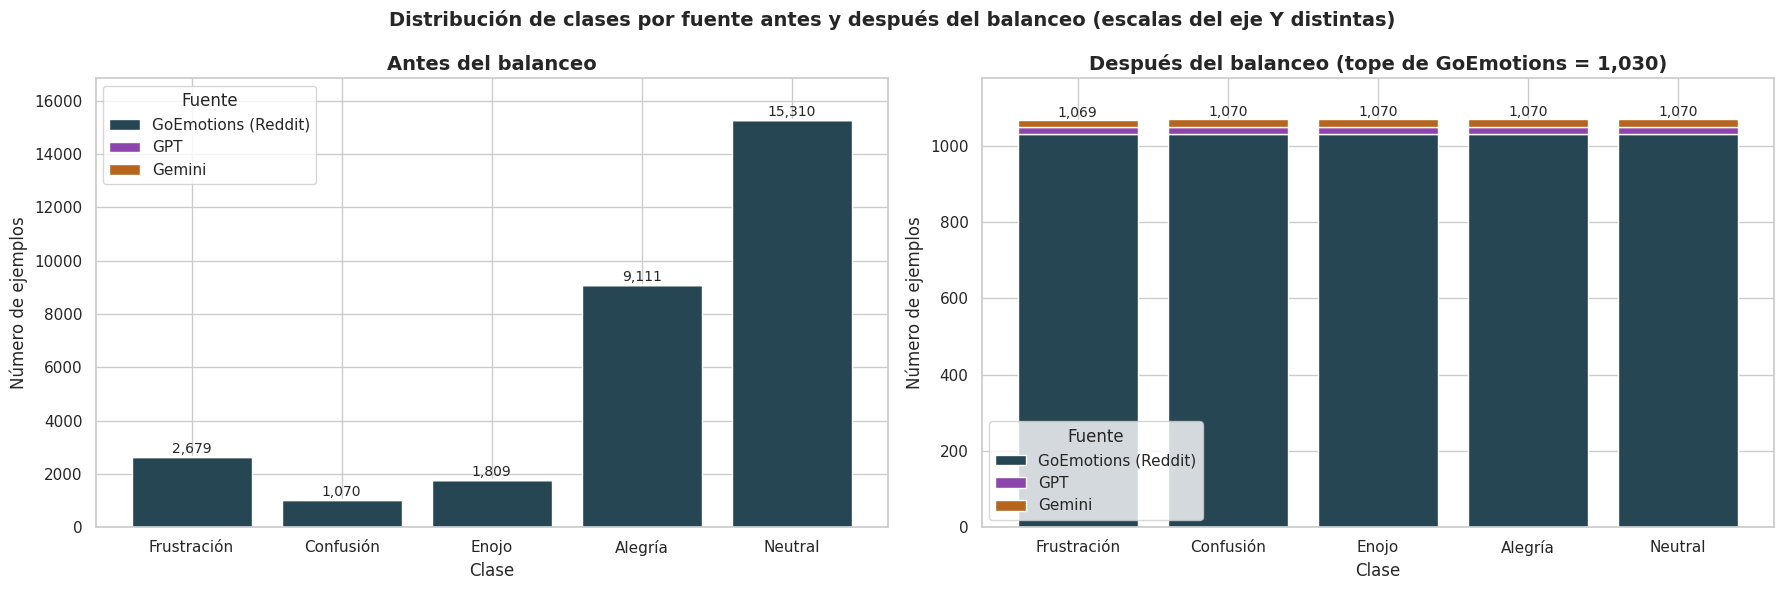

In [149]:
fig, ejes = plt.subplots(1, 2, figsize=(18, 6))
barras_apiladas_por_fuente(df_limpio, ejes[0], "Antes del balanceo")
barras_apiladas_por_fuente(df_balanceado, ejes[1], f"Después del balanceo (tope de GoEmotions = {TOPE_POR_CLASE:,})")
fig.suptitle("Distribución de clases por fuente antes y después del balanceo (escalas del eje Y distintas)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Dataset final.** Se conservan solo las cuatro columnas del esquema común: `texto`, `clase`, `emocion_original` y `fuente` (la columna auxiliar `texto_ingles` se descarta). El dataset se guarda en `DIRECTORIO_DATOS/dataset_final.csv` para no repetir todo el procesamiento en las secciones siguientes. En Colab, esa carpeta está en Google Drive, así que el archivo se conserva entre sesiones.

In [150]:
df_final = df_balanceado[["texto", "clase", "emocion_original", "fuente"]].copy()

tabla_final = pd.crosstab(df_final["clase"], df_final["fuente"], margins=True, margins_name="Total")
tabla_final = tabla_final.reindex(index=ORDEN_CLASES + ["Total"], columns=ORDEN_FUENTES + ["Total"], fill_value=0)
print("Dataset final: ejemplos por clase y fuente")
display(tabla_final)

porcentaje_sintetico_final = (df_final["fuente"] != "goemotions").groupby(df_final["clase"]).mean().reindex(ORDEN_CLASES) * 100
print("Porcentaje de ejemplos sintéticos por clase en el dataset final:")
display(porcentaje_sintetico_final.round(1).rename("% sintéticos").to_frame())
print(f"Porcentaje de ejemplos sintéticos en todo el dataset final: {(df_final['fuente'] != 'goemotions').mean():.1%}")

# Comprobación: los sintéticos deben repartirse de forma parecida entre clases. Si una clase tuviera
# muchos menos, la fuente empezaría a correlacionarse con la clase.
sinteticos_por_clase = df_final[df_final["fuente"] != "goemotions"]["clase"].value_counts().reindex(ORDEN_CLASES, fill_value=0)
media_sinteticos = sinteticos_por_clase.mean()
clases_con_pocos = sinteticos_por_clase[sinteticos_por_clase < 0.75 * media_sinteticos]
print(f"Sintéticos por clase: {sinteticos_por_clase.to_dict()} (media = {media_sinteticos:.1f})")
if clases_con_pocos.empty:
    print("Los sintéticos están repartidos de forma parecida entre las clases (ninguna por debajo del 75 % de la media).")
else:
    print(f"Advertencia: clases con muchos menos sintéticos que la media: {clases_con_pocos.to_dict()}")

os.makedirs(DIRECTORIO_DATOS, exist_ok=True)
df_final.to_csv(RUTA_DATASET_FINAL, index=False, encoding="utf-8")
print(f"Dataset final guardado en {RUTA_DATASET_FINAL}: {df_final.shape[0]:,} filas, {df_final.shape[1]} columnas")

df_final.head()

Dataset final: ejemplos por clase y fuente


fuente,goemotions,gpt,gemini,Total
clase,,,,
frustracion,1030,20,19,1069
confusion,1030,20,20,1070
enojo,1030,20,20,1070
alegria,1030,20,20,1070
neutral,1030,20,20,1070
Total,5150,100,99,5349


Porcentaje de ejemplos sintéticos por clase en el dataset final:


,% sintéticos
clase,
frustracion,3.6
confusion,3.7
enojo,3.7
alegria,3.7
neutral,3.7


Porcentaje de ejemplos sintéticos en todo el dataset final: 3.7%
Sintéticos por clase: {'frustracion': 39, 'confusion': 40, 'enojo': 40, 'alegria': 40, 'neutral': 40} (media = 39.8)
Los sintéticos están repartidos de forma parecida entre las clases (ninguna por debajo del 75 % de la media).
Dataset final guardado en /content/drive/MyDrive/analisis_sentimientos/data/dataset_final.csv: 5,349 filas, 4 columnas


,texto,clase,emocion_original,fuente
0,Yo también los odio a todos.,enojo,anger,goemotions
1,Pensé que esto era un Stossel socialista...,neutral,neutral,goemotions
2,"Ouch, mi corazón. Ni siquiera pensé en esto...",frustracion,disappointment,goemotions
3,*Ugh..* Tienes 23 años y no estás casado - permiso.,enojo,disgust,goemotions
4,"Ignóralo, es una pequeña rata rencorosa que está loca porque alguien hizo algo bueno y le recuerda lo patético que es.",enojo,anger,goemotions


**Interpretación.** [COMPLETAR tras ejecutar: el tope quedó en [COMPLETAR] ejemplos por clase para GoEmotions. Se submuestrearon las clases [COMPLETAR] y se conservó completa [COMPLETAR]. El ratio de desbalance pasó de [COMPLETAR] a [COMPLETAR].]

**Peso de los datos sintéticos.** Antes de eliminar las plantillas, los sintéticos eran el ~22,5 % de cada clase del dataset final; ahora son el [COMPLETAR] % del total (entre [COMPLETAR] % y [COMPLETAR] % según la clase). La cifra anterior era engañosa: buena parte de ese 22,5 % eran variantes de la misma frase, que no aportaban información nueva y sí riesgo de *data leakage*. La cifra actual refleja cuántos mensajes educativos realmente distintos tiene el dataset. [COMPLETAR: indicar si los sintéticos quedaron repartidos de forma parecida entre clases según la comprobación de la celda anterior; si alguna clase tiene muchos menos, la fuente podría correlacionarse con la clase.] Como el dominio educativo queda poco representado, la evaluación sobre un conjunto de prueba escrito por personas cobra aún más importancia.

**Cifras clave de 2.13**

- Filas antes del balanceo: [COMPLETAR] → filas del dataset final: [COMPLETAR] (GoEmotions = [COMPLETAR], GPT = [COMPLETAR], Gemini = [COMPLETAR]).
- Ejemplos por clase en el dataset final: frustración = [COMPLETAR], confusión = [COMPLETAR], enojo = [COMPLETAR], alegría = [COMPLETAR], neutral = [COMPLETAR].

### 2.14 Conclusiones del EDA

[COMPLETAR tras ejecutar la notebook completa, con las cifras obtenidas:]

1. **Tamaño y composición del dataset final.** De los [COMPLETAR] comentarios originales de GoEmotions se conservan [COMPLETAR] tras filtrar los de una sola etiqueta, agrupar en las cinco clases, limpiar y submuestrear; a ellos se suman [COMPLETAR] mensajes de GPT y [COMPLETAR] de Gemini. El dataset final tiene [COMPLETAR] ejemplos: frustración = [COMPLETAR], confusión = [COMPLETAR], enojo = [COMPLETAR], alegría = [COMPLETAR], neutral = [COMPLETAR]. Los datos sintéticos aportan el [COMPLETAR] % del total.
2. **Desbalance.** Tras la limpieza, el ratio de desbalance era de [COMPLETAR] (`[COMPLETAR]` frente a `[COMPLETAR]`); un clasificador trivial tendría una exactitud de [COMPLETAR] %. Por eso se evaluará con **F1-macro** y no con exactitud. El submuestreo con tope de [COMPLETAR] lo redujo a [COMPLETAR], y el desbalance restante se compensará con `class_weight="balanced"`.
3. **Datos reales frente a sintéticos.**
   - *Longitud:* los sintéticos tienen una mediana de [COMPLETAR] palabras y un coeficiente de variación de [COMPLETAR], frente a [COMPLETAR] y [COMPLETAR] en Reddit: [COMPLETAR: más homogéneos / similares]. El percentil 95 global ([COMPLETAR] palabras) está muy por debajo del límite de 128 tokens del encoder, así que la truncación no es un problema.
   - *Vocabulario:* Reddit contiene términos ajenos a la educación ([COMPLETAR]), mientras que los sintéticos se concentran en vocabulario académico ([COMPLETAR]).
   - *Muletillas:* [COMPLETAR: por ejemplo, el [COMPLETAR] % de los mensajes de confusión de GPT empiezan con "[COMPLETAR]"].
   - *Diversidad:* con muestras del mismo tamaño, el distinct-2 es de [COMPLETAR] en Reddit frente a [COMPLETAR] en GPT y [COMPLETAR] en Gemini, y la limpieza de casi duplicados eliminó el [COMPLETAR] % de GPT.
4. **Clases difíciles de separar.** Se anticipa que **frustración y enojo** serán las clases más difíciles de separar, porque `annoyance` y `anger` aparecen juntas en [COMPLETAR] comentarios multietiqueta, comparten vocabulario negativo y la revisión de los sintéticos mostró mensajes de una clase con pistas de la otra. [COMPLETAR: también confusión frente a neutral, si las preguntas neutras se parecen a las de confusión.] Esto se volverá a revisar en la visualización t-SNE y en la matriz de confusión.
5. **Plantillas en los datos sintéticos.** Los generadores no produjeron mensajes independientes: GPT usó [COMPLETAR] plantillas (20 por clase) con 10 variantes cada una, de modo que sus 1 000 mensajes eran en realidad [COMPLETAR] mensajes distintos; Gemini, [COMPLETAR] plantillas para sus [COMPLETAR] mensajes. Tras conservar un mensaje por plantilla, los sintéticos pasaron de [COMPLETAR] a [COMPLETAR] mensajes. **Lección metodológica:** un filtro de similitud sobre el texto completo (2.7.2) no detecta las plantillas generadas por LLMs, porque la parte variable domina la comparación en mensajes cortos; hay que analizar la **estructura** de los mensajes (inicios repetidos, enmascaramiento de la parte variable). Sin este paso, variantes de una misma frase habrían quedado en entrenamiento y en prueba de un mismo fold, inflando el F1.
6. **Limitaciones y mitigación.** GoEmotions aporta volumen y etiquetas humanas, pero proviene de Reddit, tiene errores de traducción y sus etiquetas se asignaron sobre el texto en inglés. Los sintéticos aportan el dominio educativo, pero son menos diversos, tienen muletillas y su etiqueta la puso el generador. Se mitigan combinando las fuentes, eliminando casi duplicados y variantes de plantilla, y evaluando el modelo final con un conjunto de prueba escrito por personas.

**Trabajo para las secciones siguientes**

- **t-SNE:** además de colorear los embeddings por clase (lo pide la rúbrica), se hará una segunda visualización coloreada **por fuente**, para comprobar si los datos sintéticos forman grupos separados de los de GoEmotions (lo que indicaría que el encoder distingue el estilo del generador).
- **Experimento entre generadores:** además del *repeated k-fold*, se entrenará con GoEmotions + GPT y se evaluará con Gemini, y viceversa, para medir si el modelo generaliza o aprende el estilo de un generador.
- **Regeneración de datos sintéticos:** si en el futuro se generan nuevos datos, el prompt debe pedir **variedad estructural** (frases construidas de forma distinta, no la misma frase cambiando la materia), y el análisis de plantillas de 2.7.3 debe repetirse sobre los datos nuevos antes de usarlos.
- **Conjunto de prueba humano:** el modelo final se evaluará sobre un conjunto pequeño de mensajes escritos por personas reales, que nunca se usa para entrenar.